# WorldPulse — Qu'est-ce qui rend un pays heureux ?

*Rapport d'analyse — données World Bank et World Happiness Report, rapport 2026, 146 pays*

---

**Contexte.** Une ONG internationale veut savoir quels facteurs (richesse, santé, éducation, internet, emploi, urbanisation) expliquent le mieux le niveau de bonheur d'un pays, pour orienter ses actions.

**Données.** 7 indicateurs de la World Bank (2013–2025), combinés au score de bonheur du *World Happiness Report*, récupéré sur Wikipedia.

> **Résultats clés**
>
> - **Le niveau de développement est le premier facteur** : le PIB par habitant (en log) explique à lui seul 62 % des écarts de bonheur entre pays.
> - **Le chômage est le deuxième facteur** : 5 points de chômage en plus vont de pair avec 0,3 point de bonheur en moins, autant qu'un PIB divisé par deux.
> - **Modèle retenu** : une régression linéaire à 5 variables, choisie par des critères chiffrés. Sur des pays qu'il n'a jamais vus, il explique **environ 63 % des écarts**, avec une erreur moyenne de 0,5 point sur 10.
> - **La gouvernance n'apporte rien au-delà de la richesse**, et le **paradoxe d'Easterlin ne se vérifie pas** sur 2016–2026 : quand un pays s'enrichit, son bonheur augmente.
> - Ce sont des **associations entre pays**, pas des liens de cause à effet.

**Sommaire**

| # | Section | Script |
|---|---|---|
| 1 | [Environnement et reproductibilité](#s1) | — |
| 2 | [Extraction World Bank](#s2) | `src/01_extraction_api.py` |
| 3 | [Scraping Wikipedia](#s3) | `src/02_scraping_wikipedia.py` |
| 4 | [Nettoyage et fusion](#s4) | `src/03_nettoyage_fusion.py` |
| 5 | [Base SQLite](#s5) | `src/04_base_sqlite.py` |
| 6 | [Analyse exploratoire](#s6) | ce notebook |
| 7 | [Modélisation et sélection des variables](#s7) | `src/05_modelisation.py` |
| 8 | [Clustering : des profils de pays](#s8) | `src/06_clustering.py` |
| 9 | [Analyse complémentaire : la gouvernance](#s9) | `src/07_gouvernance.py` |
| 10 | [Analyse complémentaire : le paradoxe d'Easterlin](#s10) | `src/08_easterlin.py` |
| 11 | [Conclusion et recommandations pour l'ONG](#s11) | — |

Ce notebook lit les fichiers produits par les scripts de `src/` et ne télécharge rien. Chaque section suit le même plan : la question posée, le code, le graphique, puis un encadré **Lecture** qui interprète le résultat.

---

<a id="s1"></a>

## 1. Environnement et reproductibilité

- **Environnement** : virtuel `.venv` (Python 3.12), dépendances dans `requirements.txt`. pandas est fixé à une version < 3, car `country_converter` 1.3.2 ne fonctionne pas avec pandas 3.
- **Reproduire les résultats** : lancer les scripts de `src/` dans l'ordre (`01` à `08`, voir le README), puis exécuter ce notebook.

La cellule ci-dessous charge les bibliothèques, les chemins du projet et la charte graphique, commune à tous les graphiques.

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from scipy import stats

%config InlineBackend.figure_format = "retina"   # graphiques nets sur tous les écrans

# Racine du projet (le notebook peut être lancé depuis notebooks/ ou depuis la racine)
RACINE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROCESSED = RACINE / "data" / "raw", RACINE / "data" / "processed"
REPORTS = RACINE / "reports"
BASE = RACINE / "db" / "worldpulse.db"

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)

# Charte graphique : palette lisible par les daltoniens, axes et grille discrets
BLEU, ORANGE, ROUGE, GRIS, AQUA = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7", "#1baf7a"
ENCRE, ENCRE_2, MUET, FOND = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRIS, "axes.labelcolor": ENCRE_2, "text.color": ENCRE,
    "xtick.color": MUET, "ytick.color": ENCRE_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelpad": 6, "legend.frameon": False,
})

def sans_cadre(ax):
    """Retire grille, graduations et bordures (pour les cartes de chaleur)."""
    ax.grid(False)
    ax.tick_params(length=0)
    for bord in ax.spines.values():
        bord.set_visible(False)

alea = np.random.default_rng(0)   # léger décalage aléatoire des points (lisibilité)

# Les 7 variables explicatives et leurs libellés lisibles
VARIABLES = ["log_pib", "esperance_vie", "internet_pct", "urbanisation_pct",
             "depenses_sante_pct_pib", "depenses_education_pct_pib", "chomage_pct"]
LIBELLES = {
    "pib_par_habitant_ppa": "PIB / habitant (PPA)",
    "log_pib": "PIB / habitant (log)",
    "esperance_vie": "Espérance de vie",
    "internet_pct": "Internet (% pop.)",
    "chomage_pct": "Chômage (%)",
    "depenses_education_pct_pib": "Dépenses éducation (% PIB)",
    "depenses_sante_pct_pib": "Dépenses santé (% PIB)",
    "urbanisation_pct": "Urbanisation (%)",
    "controle_corruption": "Contrôle de la corruption",
    "stabilite_politique": "Stabilité politique",
    "etat_de_droit": "État de droit",
}

# Noms de colonnes lisibles pour les tableaux affichés
COLONNES = {
    "coefficient": "Coefficient", "erreur_standard": "Erreur standard", "t": "t", "p_valeur": "p-valeur",
    "ic_bas": "IC 95 % bas", "ic_haut": "IC 95 % haut", "coefficient_standardise": "Coef. standardisé",
    "significatif": "Significatif (5 %)", "variables": "Variables", "nb_variables": "Nb variables",
    "r2_ajuste": "R² ajusté", "aic": "AIC", "bic": "BIC", "cp_mallows": "Cp de Mallows",
    "rmse_cv": "RMSE (CV)", "rmse_cv_es": "Erreur standard RMSE", "r2_cv": "R² (CV)",
    "rmse": "RMSE", "rmse_es": "Erreur standard RMSE", "mae": "MAE", "r2": "R²",
    "nb_variables_moyen": "Nb variables (moyenne)", "pente": "Pente",
    "pays": "Pays", "score_bonheur": "Score de bonheur", "score_min": "Score min", "score_max": "Score max",
}

def tableau(donnees, decimales=2):
    """Affiche un tableau avec des noms de colonnes lisibles et des valeurs arrondies."""
    return donnees.rename(columns=COLONNES, index=LIBELLES).round(decimales)

---

<a id="s2"></a>

## 2. Extraction World Bank

- **Liste des pays** via l'API JSON, agrégats régionaux exclus (217 pays et territoires).
- **7 indicateurs, 2013–2025**, par téléchargement groupé (ZIP/CSV). L'API JSON de données renvoyait des erreurs 502 en novembre 2026.
- Format long : une ligne par (pays, indicateur, année).

In [2]:
wb = pd.read_csv(RAW / "worldbank_indicateurs.csv")
print(wb.shape)
wb.head()

(16650, 5)


,iso3,indicateur,code_wb,annee,valeur
0,ABW,pib_par_habitant_ppa,NY.GDP.PCAP.PP.KD,2013,35711.93
1,AFG,pib_par_habitant_ppa,NY.GDP.PCAP.PP.KD,2013,3046.58
2,AGO,pib_par_habitant_ppa,NY.GDP.PCAP.PP.KD,2013,11622.98
3,ALB,pib_par_habitant_ppa,NY.GDP.PCAP.PP.KD,2013,12873.43
4,AND,pib_par_habitant_ppa,NY.GDP.PCAP.PP.KD,2013,57332.16


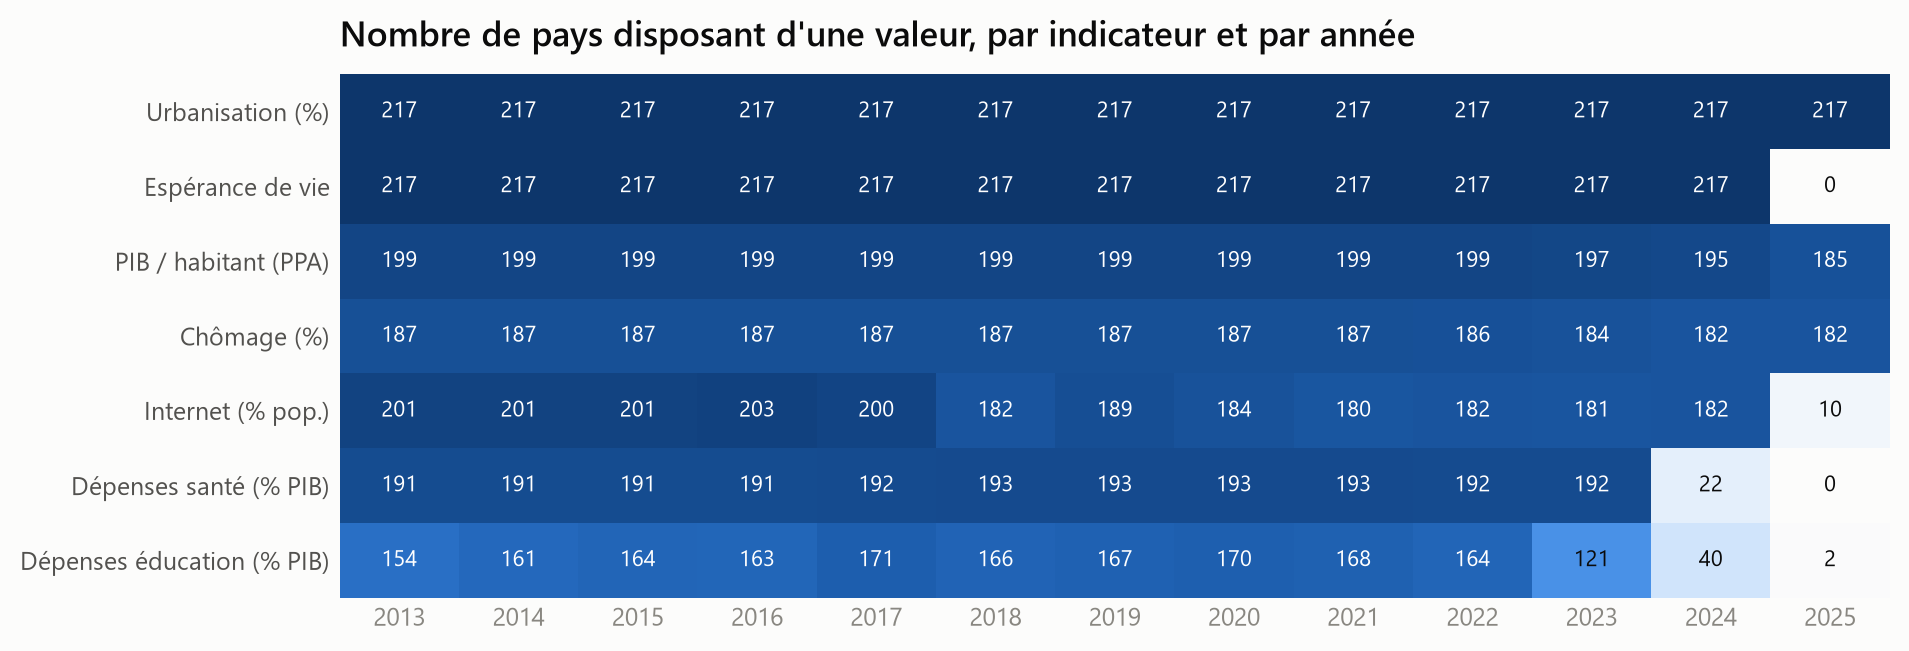

In [3]:
# Nombre de pays ayant une valeur, par indicateur et par année
couverture = (wb.pivot_table(index="indicateur", columns="annee", values="iso3", aggfunc="nunique")
                .fillna(0).astype(int).rename(index=LIBELLES))
couverture = couverture.loc[couverture.sum(axis=1).sort_values(ascending=False).index]

bleus = LinearSegmentedColormap.from_list("bleus", [FOND, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.imshow(couverture.values, cmap=bleus, vmin=0, vmax=217, aspect="auto")
for (i, j), n in np.ndenumerate(couverture.values):
    ax.text(j, i, n, ha="center", va="center", fontsize=8, color="white" if n > 140 else ENCRE)
ax.set_xticks(range(couverture.shape[1]), couverture.columns)
ax.set_yticks(range(couverture.shape[0]), couverture.index)
sans_cadre(ax)
ax.set_title("Nombre de pays disposant d'une valeur, par indicateur et par année")
plt.show()

> **Lecture.** La couverture est quasi complète jusqu'en 2022, puis elle chute : la World Bank publie ses chiffres avec 1 à 3 ans de retard. Les dépenses d'éducation (121 pays en 2023, 40 en 2024) et de santé (22 pays en 2024) sont les plus touchées, et 2025 n'est renseigné que pour le PIB, le chômage et l'urbanisation. Cela justifie la règle de repli de l'étape 4.

---

<a id="s3"></a>

## 3. Scraping Wikipedia

Page *World Happiness Report*, section « International rankings » : un tableau par rapport annuel. On fait une seule requête avec un User-Agent identifiable, et on garde une copie du HTML (`data/raw/wikipedia_whr.html`). On ne conserve que le rang, le pays et le score. Les colonnes « facteurs » du rapport sont des décompositions du score lui-même : les utiliser serait une fuite de données.

In [4]:
bonheur = pd.read_csv(RAW / "wikipedia_bonheur.csv")
print(bonheur.shape)
bonheur.head()

(1301, 6)


,rapport,enquete_debut,enquete_fin,rang,pays,score_bonheur
0,2026,2023,2025,1.0,Finland,7.76
1,2026,2023,2025,2.0,Iceland,7.54
2,2026,2023,2025,3.0,Denmark,7.54
3,2026,2023,2025,4.0,Costa Rica,7.44
4,2026,2023,2025,5.0,Sweden,7.25


In [5]:
(bonheur.groupby("rapport")
        .agg(pays=("pays", "nunique"), score_min=("score_bonheur", "min"), score_max=("score_bonheur", "max"))
        .sort_index(ascending=False).pipe(tableau))

,Pays,Score min,Score max
rapport,,,
2026,147,1.45,7.76
2025,147,1.36,7.74
2024,143,1.72,7.74
2020,153,2.57,7.81
2019,156,2.85,7.77
2018,156,2.90,7.63
2017,157,2.69,7.54
2016,157,2.90,7.53
2013,85,5.10,7.69


> **Lecture.** 9 rapports ont un score. Les rapports 2022 et 2023 apparaissent sur la page, mais sans score ; 2021, 2015 et 2014 sont absents. Le rapport 2013 ne liste que les 85 premiers pays (score minimum 5,1) : il est exclu, car il fausserait toute comparaison. Le score va de 1,4 (Afghanistan) à 7,8 (Finlande).

---

<a id="s4"></a>

## 4. Nettoyage et fusion

- **Pays → codes ISO3** avec `country_converter`. Corrections manuelles : *Northern Cyprus* et *Somaliland region* (sinon confondus avec Chypre et la Somalie), *World* et *Europe* exclus.
- **Une valeur par pays et par indicateur** : moyenne sur les années d'enquête du rapport (2023–2025 pour 2026) ; à défaut, dernière valeur de 2020–2022.
- **Valeur aberrante** : les dépenses d'éducation de la Somalie (≈ 0 % du PIB) sont traitées comme manquantes.
- **Fusion** (jointure interne sur `iso3`). Les valeurs manquantes restantes sont conservées ; elles seront imputées dans la validation croisée (étape 7).

In [6]:
df = pd.read_csv(PROCESSED / "worldpulse_2026.csv")
print(df.shape, "—", df.notna().all(axis=1).sum(), "pays complets")
df.head()

(146, 13) — 134 pays complets


,rapport,iso3,pays,region,niveau_revenu,score_bonheur,chomage_pct,depenses_education_pct_pib,depenses_sante_pct_pib,esperance_vie,internet_pct,pib_par_habitant_ppa,urbanisation_pct
0,2026,FIN,Finland,Europe & Central Asia,High income,7.76,8.34,6.38,10.47,81.96,93.62,55896.10,74.26
1,2026,ISL,Iceland,Europe & Central Asia,High income,7.54,3.58,7.31,8.84,82.63,98.08,68521.05,94.18
2,2026,DNK,Denmark,Europe & Central Asia,High income,7.54,5.33,6.36,9.47,82.00,99.27,70917.25,88.70
3,2026,CRI,Costa Rica,Latin America & Caribbean,High income,7.44,7.37,5.31,6.87,80.90,86.28,27382.33,79.31
4,2026,SWE,Sweden,Europe & Central Asia,High income,7.25,8.24,7.32,11.18,83.69,95.67,62681.13,88.86


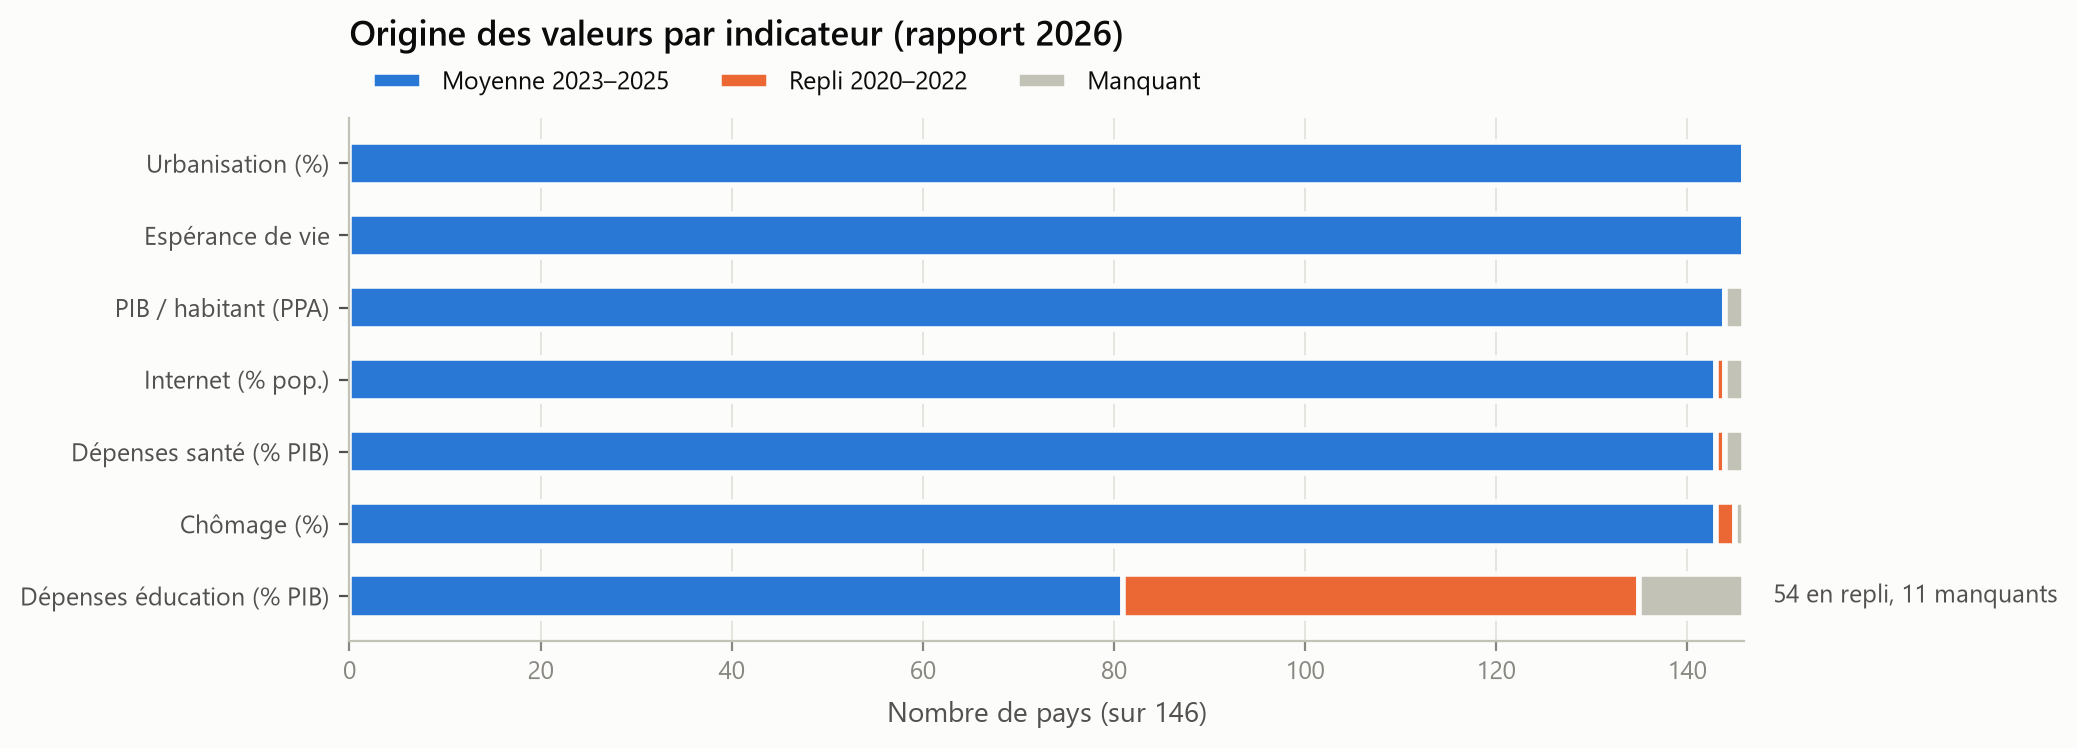

In [7]:
# Origine des valeurs de chaque indicateur, pour les 146 pays retenus
qualite = (pd.read_csv(PROCESSED / "qualite_indicateurs_2026.csv", index_col="indicateur")
             .rename(index=LIBELLES).sort_values("periode"))

fig, ax = plt.subplots(figsize=(9, 3.4))
gauche = np.zeros(len(qualite))
for colonne, couleur, nom in [("periode", BLEU, "Moyenne 2023–2025"),
                              ("repli", ORANGE, "Repli 2020–2022"),
                              ("manquant", GRIS, "Manquant")]:
    ax.barh(qualite.index, qualite[colonne], left=gauche, height=0.6,
            color=couleur, edgecolor=FOND, linewidth=2, label=nom)
    gauche += qualite[colonne].values
# Étiquette uniquement pour l'indicateur le plus fragile
fragile = "Dépenses éducation (% PIB)"
r = qualite.loc[fragile]
ax.text(149, list(qualite.index).index(fragile), f"{r.repli} en repli, {r.manquant} manquants",
        va="center", fontsize=9, color=ENCRE_2, clip_on=False)
ax.set_xlim(0, 146)
ax.set_xlabel("Nombre de pays (sur 146)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title("Origine des valeurs par indicateur (rapport 2026)", pad=26)
plt.show()

> **Lecture.** 6 indicateurs sur 7 sont mesurés sur la période 2023–2025 pour au moins 143 des 146 pays. Seules les **dépenses d'éducation** sont fragiles : 54 pays utilisent une valeur plus ancienne, et 11 n'en ont aucune. Leur poids dans le modèle devra être interprété avec prudence. Au total, 134 pays sur 146 ont des données complètes.

---

<a id="s5"></a>

## 5. Base SQLite

Tables brutes et fusionnées enregistrées dans `db/worldpulse.db`, plus une vue `worldpulse_2026` (le rapport principal). Les résultats ci-dessous sont obtenus directement par des requêtes SQL.

In [8]:
with sqlite3.connect(BASE) as connexion:
    tables = pd.read_sql("SELECT name AS nom, type FROM sqlite_master "
                         "WHERE type IN ('table', 'view') ORDER BY type, name", connexion)
    tables["lignes"] = [pd.read_sql(f"SELECT COUNT(*) AS n FROM {nom}", connexion)["n"][0]
                        for nom in tables["nom"]]
tables

,nom,type,lignes
0,bonheur_wikipedia,table,1301
1,indicateurs_wb,table,16650
2,pays,table,217
3,worldpulse,table,1200
4,worldpulse_2026,view,146


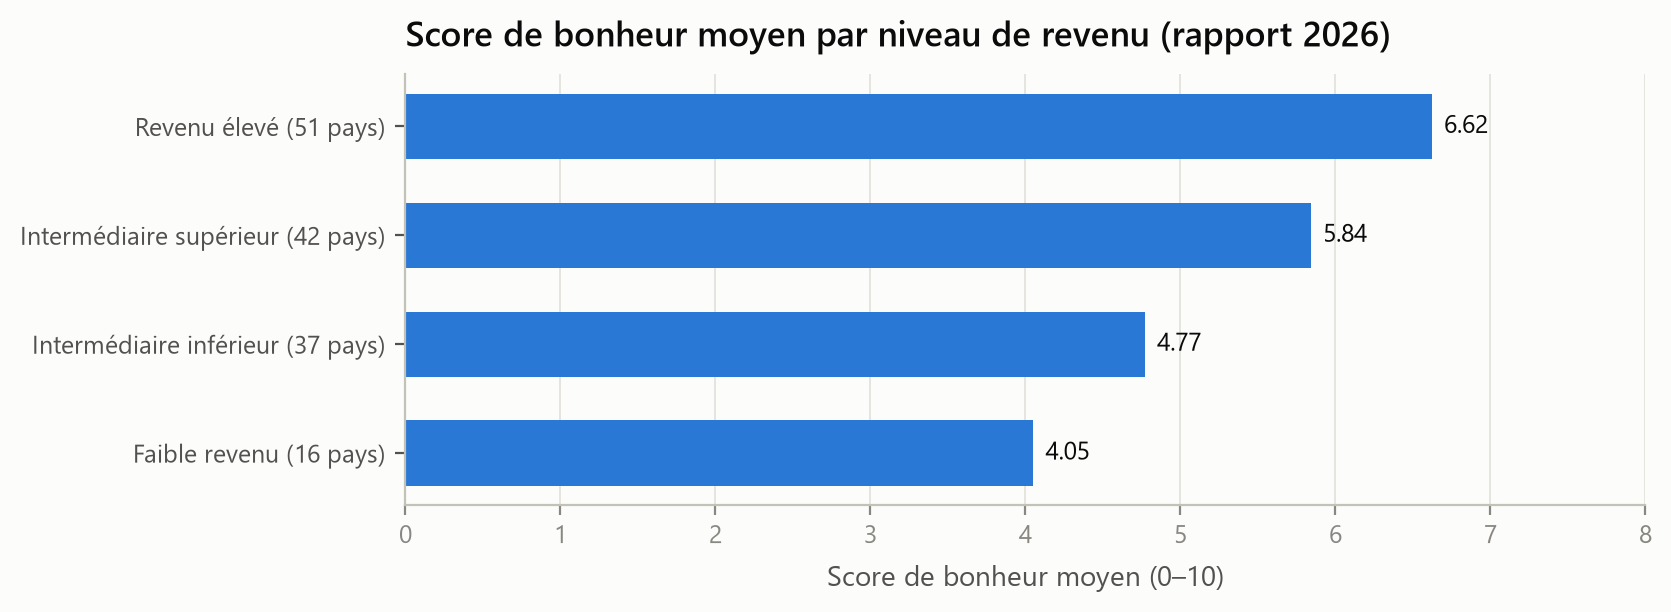

In [9]:
requete = """
SELECT niveau_revenu, COUNT(*) AS nb_pays, ROUND(AVG(score_bonheur), 2) AS score_moyen
FROM worldpulse_2026
GROUP BY niveau_revenu
ORDER BY score_moyen
"""
with sqlite3.connect(BASE) as connexion:
    revenu = pd.read_sql(requete, connexion)

noms_fr = {"Low income": "Faible revenu", "Lower middle income": "Intermédiaire inférieur",
           "Upper middle income": "Intermédiaire supérieur", "High income": "Revenu élevé"}
etiquettes = [f"{noms_fr[n]} ({k} pays)" for n, k in zip(revenu.niveau_revenu, revenu.nb_pays)]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(etiquettes, revenu.score_moyen, height=0.6, color=BLEU)
for i, score in enumerate(revenu.score_moyen):
    ax.text(score + 0.08, i, f"{score:.2f}", va="center", fontsize=9, color=ENCRE)
ax.set_xlim(0, 8)
ax.set_xlabel("Score de bonheur moyen (0–10)")
ax.grid(axis="y", visible=False)
ax.set_title("Score de bonheur moyen par niveau de revenu (rapport 2026)")
plt.show()

> **Lecture.** Le score monte à chaque palier de revenu : de 4,05 pour les pays à faible revenu à 6,62 pour les pays à revenu élevé, soit un écart de plus de 2,5 points sur une échelle de 10. La richesse semble fortement liée au bonheur. Ce lien sera mesuré précisément aux étapes 6 et 7, car le revenu va de pair avec d'autres facteurs, comme la santé et internet.

141 pays comparables : 90 en hausse, 49 en baisse, 2 inchangés


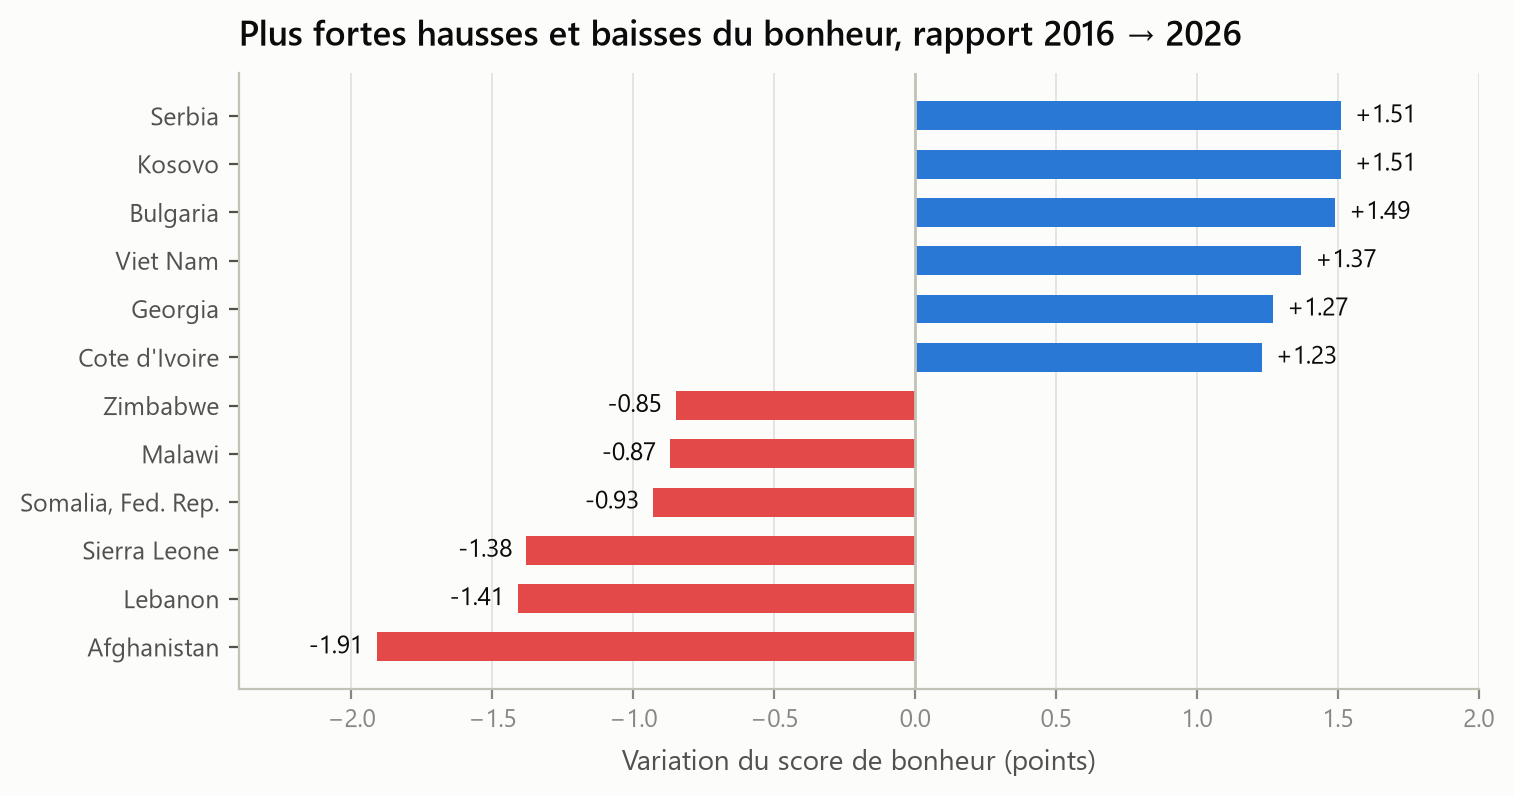

In [10]:
requete = """
SELECT a.pays, ROUND(b.score_bonheur - a.score_bonheur, 2) AS variation
FROM worldpulse AS a
JOIN worldpulse AS b ON a.iso3 = b.iso3
WHERE a.rapport = 2016 AND b.rapport = 2026
"""
with sqlite3.connect(BASE) as connexion:
    evolution = pd.read_sql(requete, connexion).sort_values("variation")
print(f"{len(evolution)} pays comparables : {(evolution.variation > 0).sum()} en hausse, "
      f"{(evolution.variation < 0).sum()} en baisse, {(evolution.variation == 0).sum()} inchangés")

extremes = pd.concat([evolution.head(6), evolution.tail(6)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(extremes.pays, extremes.variation, height=0.6,
        color=np.where(extremes.variation > 0, BLEU, ROUGE))
ax.axvline(0, color=GRIS, linewidth=1)
for i, v in enumerate(extremes.variation):
    ax.text(v + (0.05 if v > 0 else -0.05), i, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=ENCRE)
ax.set_xlim(-2.4, 2.0)
ax.set_xlabel("Variation du score de bonheur (points)")
ax.grid(axis="y", visible=False)
ax.set_title("Plus fortes hausses et baisses du bonheur, rapport 2016 → 2026")
plt.show()

> **Lecture.** Sur les 141 pays présents dans les deux rapports, 90 ont vu leur score augmenter, 49 baisser, et 2 n'ont pas bougé. Les plus fortes hausses concernent surtout l'Europe de l'Est et les Balkans (Serbie, Kosovo, Bulgarie, Géorgie), ainsi que le Viet Nam et la Côte d'Ivoire. Les plus fortes baisses touchent l'Afghanistan, le Liban, la Sierra Leone et plusieurs autres pays d'Afrique subsaharienne. *Contexte externe, non mesuré dans nos données* : l'Afghanistan a connu la guerre puis un changement de régime en 2021, et le Liban un effondrement économique depuis 2019. Le bonheur d'un pays n'est donc pas figé, et l'hypothèse qu'il réagit aux chocs politiques et économiques est plausible.

---

<a id="s6"></a>

## 6. Analyse exploratoire

Jeu principal : rapport 2026, 146 pays. Objectif : décrire la variable cible, repérer les transformations utiles et mesurer le lien entre chaque indicateur et le bonheur, avant toute modélisation.

### 6.1 La variable cible : le score de bonheur

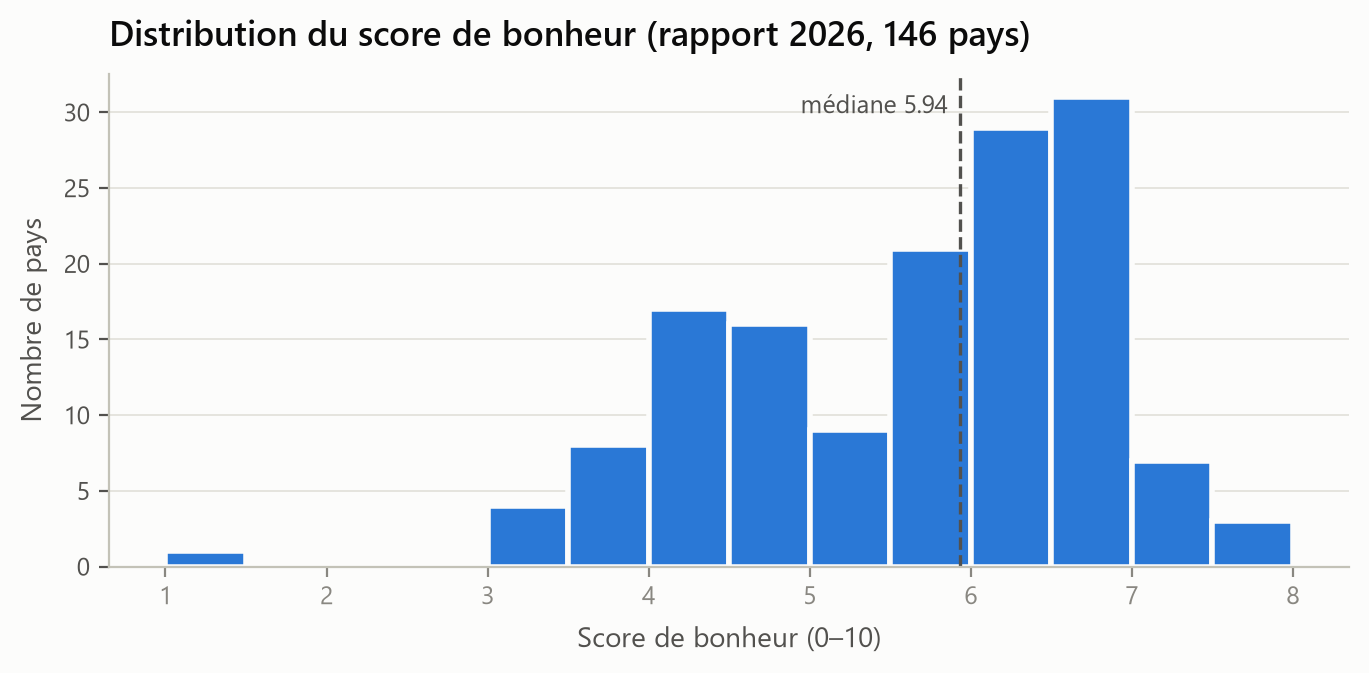

,count,mean,std,min,25%,50%,75%,max
score_bonheur,146.0,5.64,1.14,1.45,4.66,5.94,6.57,7.76


In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df.score_bonheur, bins=np.arange(1, 8.5, 0.5), color=BLEU, edgecolor=FOND, linewidth=2)
mediane = df.score_bonheur.median()
ax.axvline(mediane, color=ENCRE_2, linewidth=1.2, linestyle="--")
ax.text(mediane - 0.08, ax.get_ylim()[1] * 0.92, f"médiane {mediane:.2f}", ha="right", fontsize=9, color=ENCRE_2)
ax.set_xlabel("Score de bonheur (0–10)")
ax.set_ylabel("Nombre de pays")
ax.grid(axis="x", visible=False)
ax.set_title("Distribution du score de bonheur (rapport 2026, 146 pays)")
plt.show()
df.score_bonheur.describe().round(2).to_frame().T

> **Lecture.** La moitié des pays se situe entre 4,7 et 6,6. La distribution a **deux bosses** : un groupe de pays autour de 4–5 et un autre, plus nombreux, autour de 6–7. C'est un premier indice de « deux mondes » que le clustering (étape 8) pourra confirmer. La distribution est aussi étirée vers la gauche : quelques pays sont nettement moins heureux que les autres (Afghanistan 1,4, Sierra Leone, Malawi, Zimbabwe autour de 3,3). Ces cas extrêmes pèseront lourd dans le calcul des erreurs du modèle.

### 6.2 Distribution des indicateurs : le cas du PIB

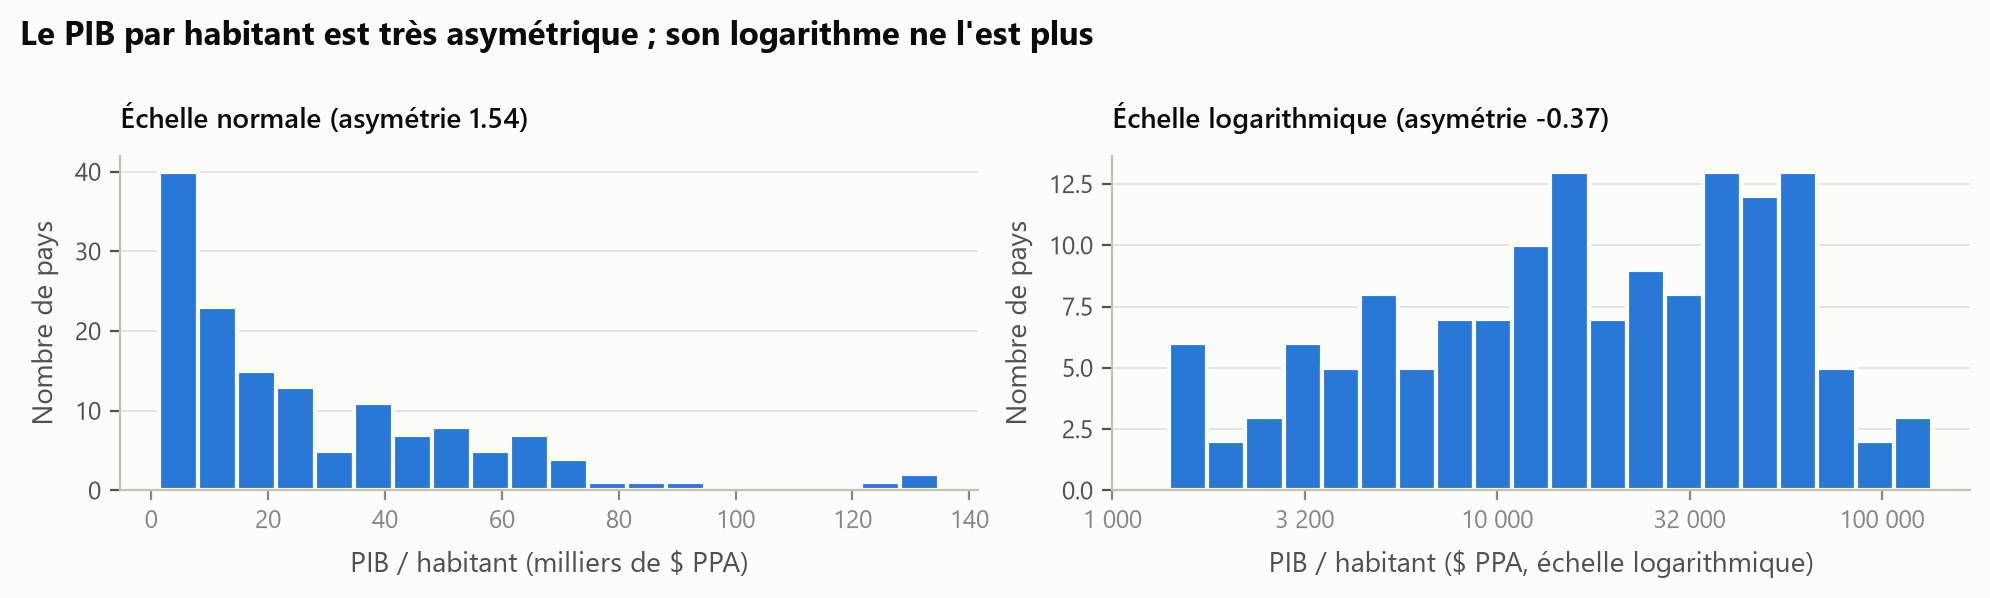

In [12]:
pib = df.pib_par_habitant_ppa.dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(pib / 1000, bins=20, color=BLEU, edgecolor=FOND, linewidth=1.5)
axes[0].set_xlabel("PIB / habitant (milliers de $ PPA)")
axes[0].set_title(f"Échelle normale (asymétrie {pib.skew():.2f})", fontsize=10)
axes[1].hist(np.log10(pib), bins=20, color=BLEU, edgecolor=FOND, linewidth=1.5)
axes[1].set_xticks([3, 3.5, 4, 4.5, 5], ["1 000", "3 200", "10 000", "32 000", "100 000"])
axes[1].set_xlabel("PIB / habitant ($ PPA, échelle logarithmique)")
axes[1].set_title(f"Échelle logarithmique (asymétrie {np.log10(pib).skew():.2f})", fontsize=10)
for ax in axes:
    ax.set_ylabel("Nombre de pays")
    ax.grid(axis="x", visible=False)
fig.suptitle("Le PIB par habitant est très asymétrique ; son logarithme ne l'est plus",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

> **Lecture.** Le PIB par habitant va de 1 400 $ à 135 000 $ : la plupart des pays sont pauvres ou intermédiaires, et quelques pays très riches (Luxembourg, Singapour, Irlande…) étirent la distribution. En échelle logarithmique, la distribution devient presque symétrique. C'est aussi plus logique économiquement : passer de 1 000 à 2 000 $ change bien plus la vie que passer de 50 000 à 51 000 $. **On utilisera donc le logarithme du PIB** (`log_pib`). Les autres indicateurs ne nécessitent pas de transformation. Le chômage (asymétrie 2,3, à cause de quelques pays au-delà de 20 %) restera tel quel, et la régression linéaire sera comparée à des modèles d'arbres, peu sensibles à ce problème.

### 6.3 Corrélations avec le bonheur

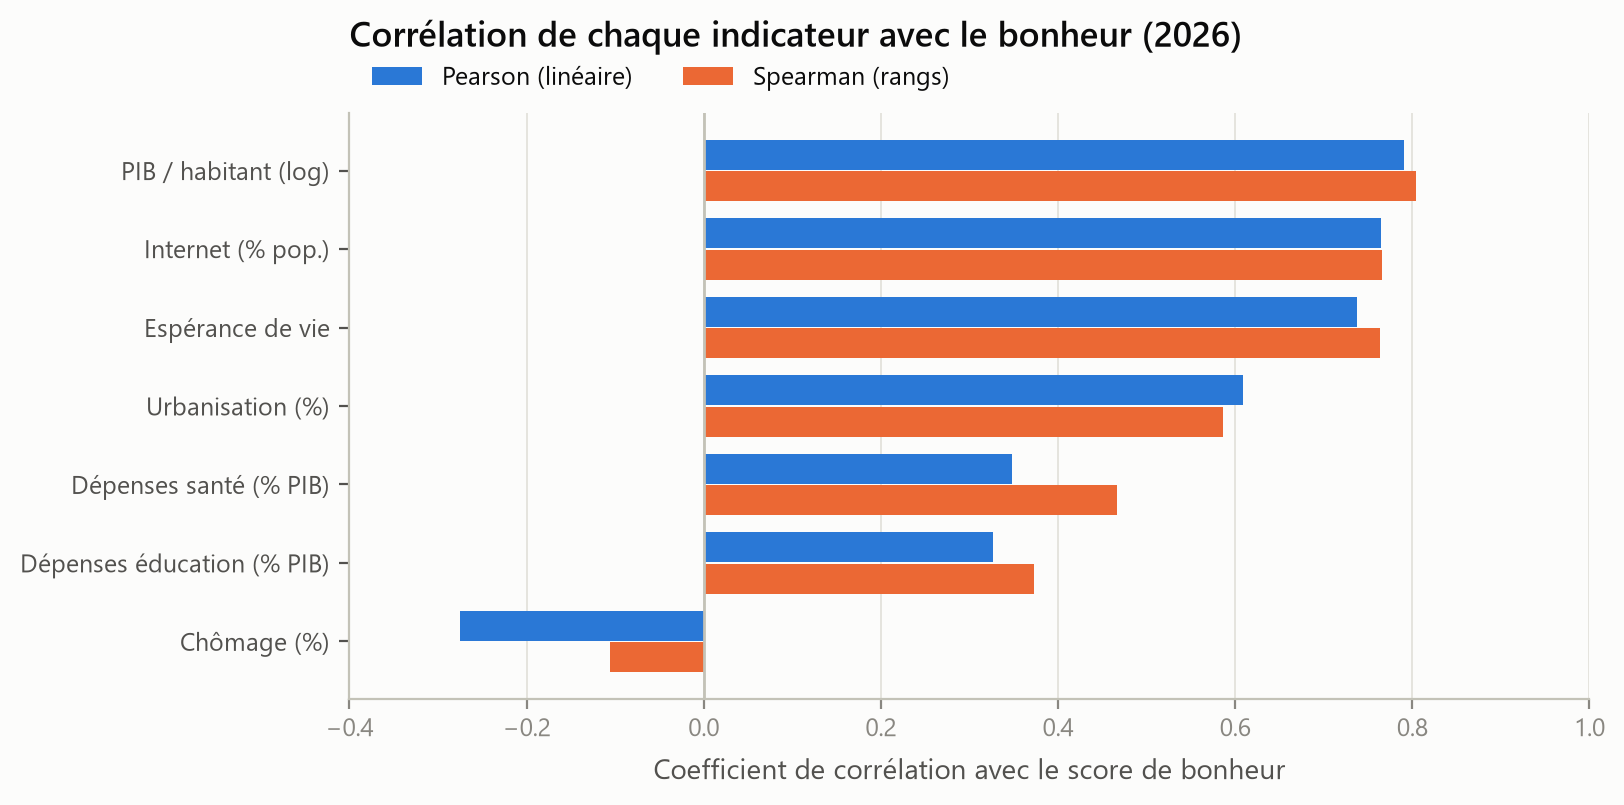

,PIB / habitant (log),Internet (% pop.),Espérance de vie,Urbanisation (%),Dépenses santé (% PIB),Dépenses éducation (% PIB),Chômage (%)
pearson,0.79,0.76,0.74,0.61,0.35,0.33,-0.28
spearman,0.80,0.77,0.76,0.59,0.47,0.37,-0.11


In [13]:
df["log_pib"] = np.log10(df.pib_par_habitant_ppa)

correlations = pd.DataFrame({
    "pearson": df[VARIABLES].corrwith(df.score_bonheur),
    "spearman": df[VARIABLES].corrwith(df.score_bonheur, method="spearman"),
}).rename(index=LIBELLES).sort_values("spearman")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(correlations))
ax.barh(y + 0.2, correlations.pearson, height=0.38, color=BLEU, label="Pearson (linéaire)")
ax.barh(y - 0.2, correlations.spearman, height=0.38, color=ORANGE, label="Spearman (rangs)")
ax.set_yticks(y, correlations.index)
ax.axvline(0, color=GRIS, linewidth=1)
ax.set_xlim(-0.4, 1)
ax.set_xlabel("Coefficient de corrélation avec le score de bonheur")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title("Corrélation de chaque indicateur avec le bonheur (2026)", pad=24)
plt.show()
correlations.sort_values("spearman", ascending=False).round(2).T

> **Lecture.** La corrélation mesure à quel point deux variables évoluent ensemble, de −1 à +1. Celle de Pearson mesure un lien en ligne droite ; celle de Spearman ne compare que les classements, ce qui la rend insensible aux valeurs extrêmes.
>
> - **Trois indicateurs se détachent** : le PIB (log, 0,79), internet (0,76) et l'espérance de vie (0,74). L'urbanisation suit (0,61).
> - **Les dépenses publiques de santé et d'éducation** (en % du PIB) sont nettement moins liées au bonheur (0,33 à 0,47). Ce qui compte n'est peut-être pas la part du PIB dépensée, mais le niveau de vie atteint.
> - **Le chômage** a une corrélation faible et négative (−0,28 en Pearson). En Spearman, elle tombe à −0,11 : le lien vient surtout de quelques pays au chômage très élevé.

### 6.4 Les indicateurs sont-ils liés entre eux ?

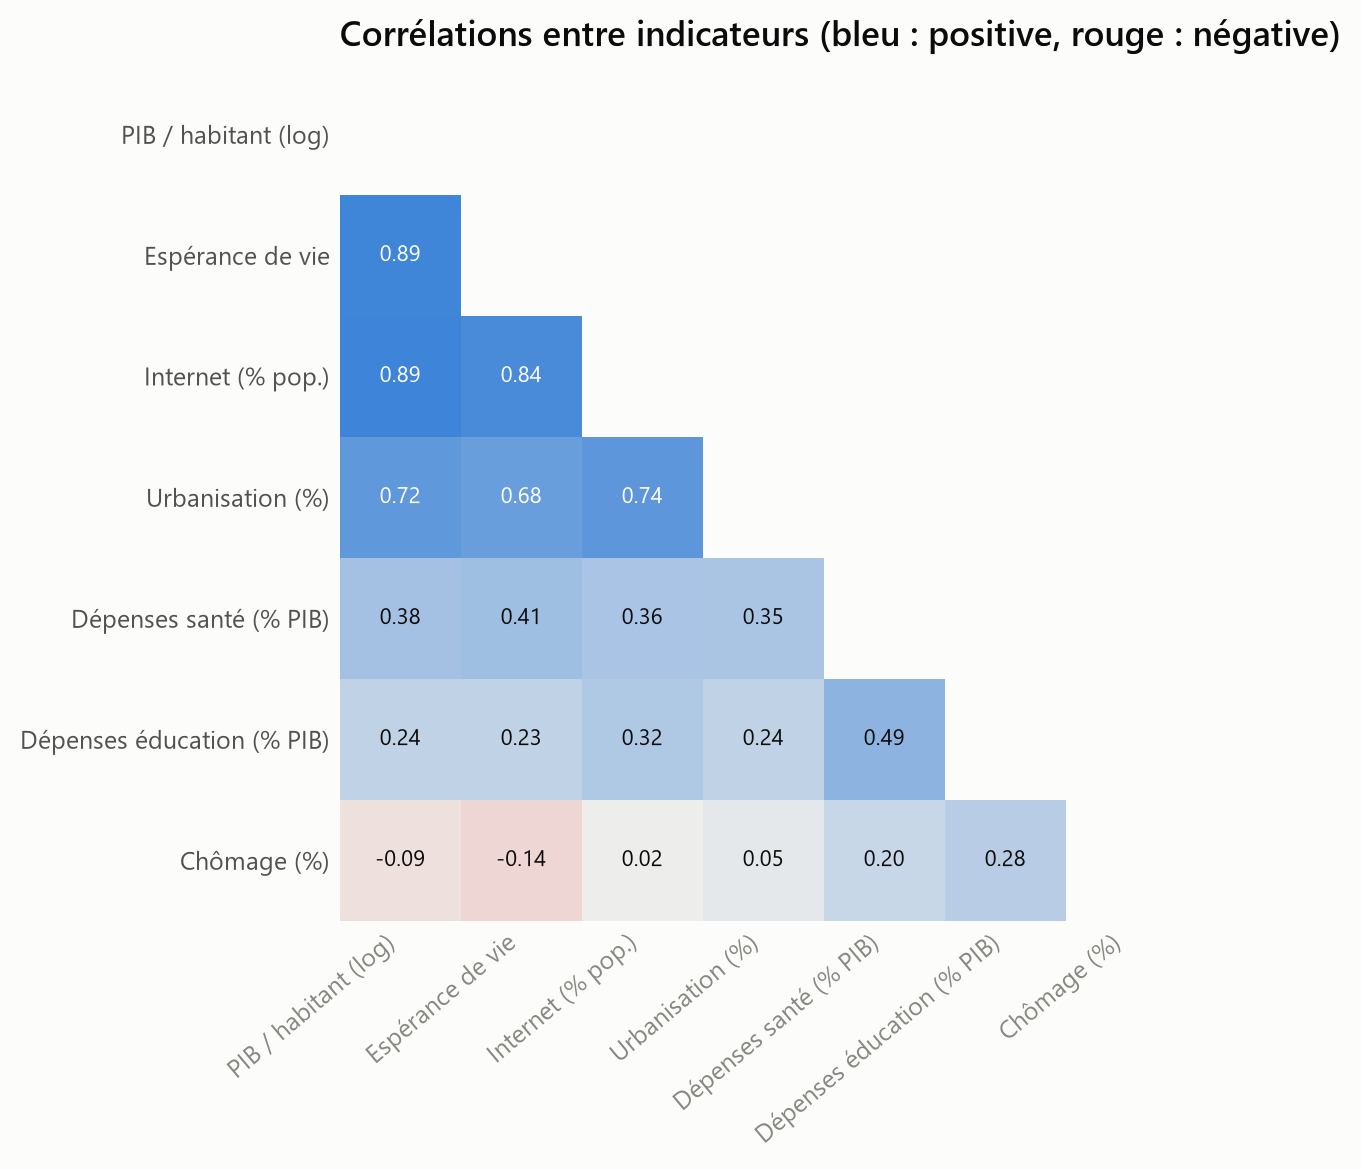

In [14]:
matrice = df[VARIABLES].corr().rename(index=LIBELLES, columns=LIBELLES)
masque = np.triu(np.ones_like(matrice, dtype=bool))
divergente = LinearSegmentedColormap.from_list("div", [ROUGE, "#f0efec", BLEU])

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.imshow(np.ma.masked_where(masque, matrice.values), cmap=divergente, vmin=-1, vmax=1)
for (i, j), r in np.ndenumerate(matrice.values):
    if not masque[i, j]:
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(r) > 0.6 else ENCRE)
ax.set_xticks(range(len(matrice)), matrice.columns, rotation=40, ha="right")
ax.set_yticks(range(len(matrice)), matrice.index)
sans_cadre(ax)
ax.set_title("Corrélations entre indicateurs (bleu : positive, rouge : négative)")
plt.show()

> **Lecture.** Le PIB (log), l'espérance de vie et internet sont **très corrélés entre eux** (0,84 à 0,89), et l'urbanisation leur est aussi liée (≈ 0,7). Les pays riches sont à la fois connectés, urbanisés et en bonne santé. On appelle cela la **multicolinéarité**. Conséquence pour l'étape 7 : le modèle aura du mal à séparer l'effet propre de chacune de ces variables, et leur importance pourra se « répartir » entre elles de façon instable. Il faudra les interpréter **comme un bloc** (le « développement économique ») plutôt qu'une par une.

### 6.5 Relation entre le bonheur et chaque indicateur

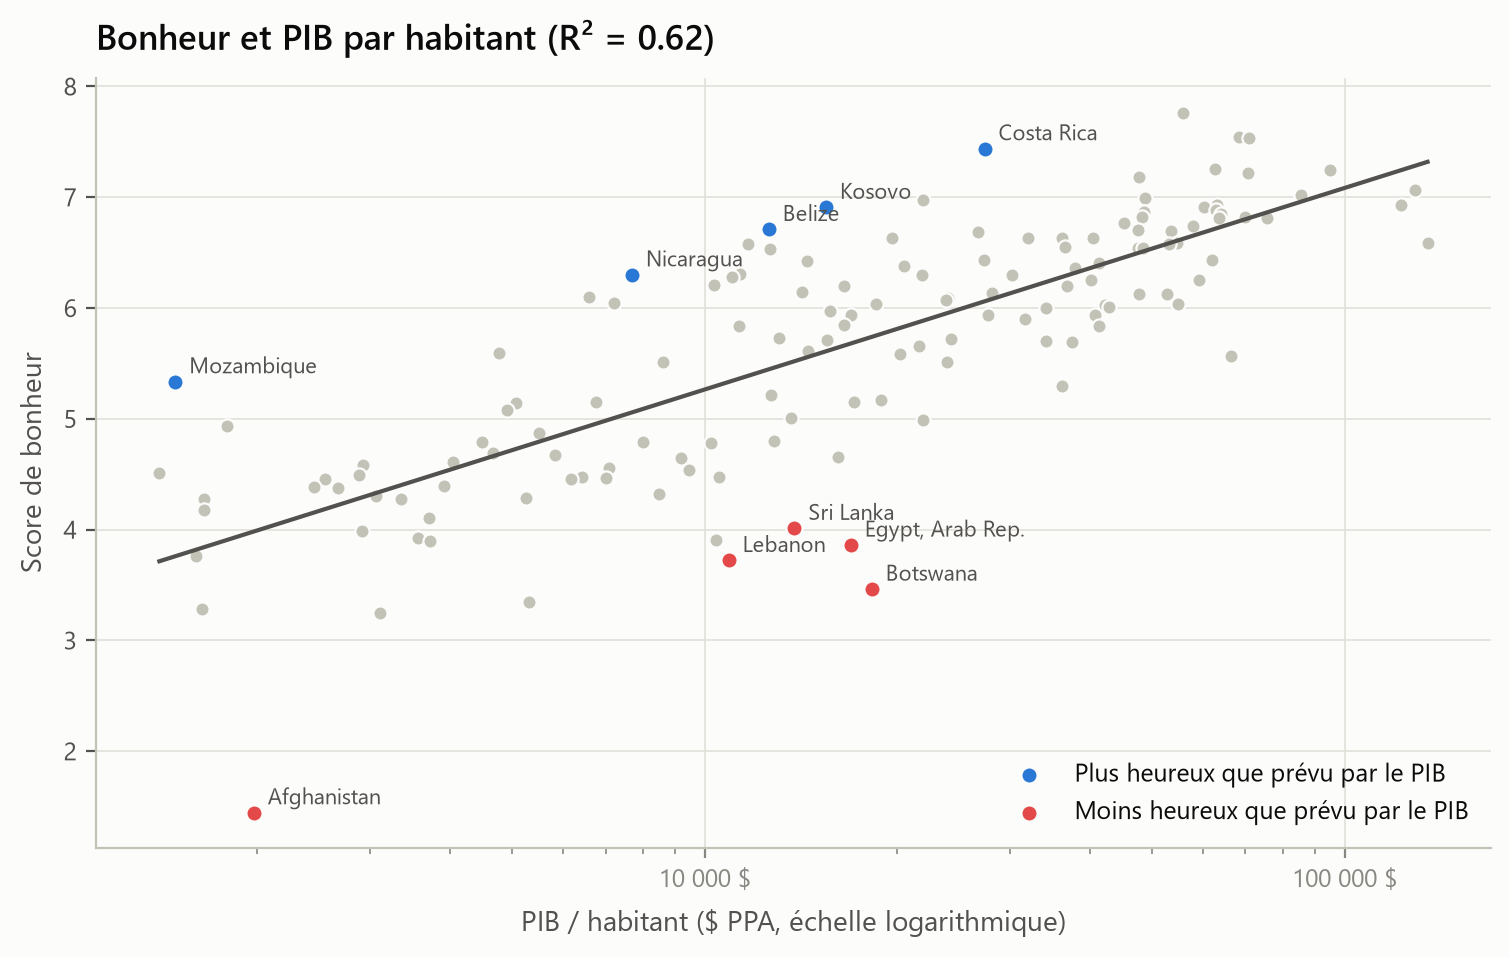

In [15]:
m = df.dropna(subset=["log_pib"]).copy()
pente, origine = np.polyfit(m.log_pib, m.score_bonheur, 1)
m["ecart"] = m.score_bonheur - (pente * m.log_pib + origine)
au_dessus, en_dessous = m.nlargest(5, "ecart"), m.nsmallest(5, "ecart")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(m.pib_par_habitant_ppa, m.score_bonheur, s=26, color=GRIS, edgecolor=FOND, linewidth=0.8)
ax.scatter(au_dessus.pib_par_habitant_ppa, au_dessus.score_bonheur, s=34, color=BLEU,
           edgecolor=FOND, linewidth=0.8, label="Plus heureux que prévu par le PIB")
ax.scatter(en_dessous.pib_par_habitant_ppa, en_dessous.score_bonheur, s=34, color=ROUGE,
           edgecolor=FOND, linewidth=0.8, label="Moins heureux que prévu par le PIB")
x = np.linspace(m.log_pib.min(), m.log_pib.max(), 50)
ax.plot(10 ** x, pente * x + origine, color=ENCRE_2, linewidth=1.5)
for _, pays in pd.concat([au_dessus, en_dessous]).iterrows():
    ax.annotate(pays.pays, (pays.pib_par_habitant_ppa, pays.score_bonheur), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=ENCRE_2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f} $".replace(",", " ")))
ax.set_xlabel("PIB / habitant ($ PPA, échelle logarithmique)")
ax.set_ylabel("Score de bonheur")
ax.legend(frameon=False, loc="lower right", fontsize=9)
r2 = np.corrcoef(m.log_pib, m.score_bonheur)[0, 1] ** 2
ax.set_title(f"Bonheur et PIB par habitant (R² = {r2:.2f})")
plt.show()

> **Lecture.** La droite montre la tendance : quand le PIB est multiplié par 10, le score augmente en moyenne de 1,8 point. **À lui seul, le PIB (log) explique 62 % des écarts de bonheur entre pays** (R² = 0,62). Les écarts à la droite sont tout aussi instructifs :
> - **Au-dessus** : surtout des pays d'**Amérique latine** (Costa Rica, Nicaragua, Belize, Salvador) et le Kosovo.
> - **En dessous** : l'Afghanistan, le Botswana, l'Égypte, le Liban et le Sri Lanka.
>
> Nos données ne permettent pas d'expliquer ces écarts. Voici des **hypothèses**, non testées ici :
> - *Amérique latine* : le World Happiness Report attribue ce bonheur « au-dessus du revenu » à des liens familiaux et sociaux forts (WHR 2018, chapitre 6, « Happiness in Latin America Has Social Foundations »).
> - *Botswana* : un PIB moyen élevé peut masquer de fortes inégalités de revenu. On pourrait le vérifier avec l'indice de Gini de la World Bank (`SI.POV.GINI`).
> - *Afghanistan, Liban* : des conflits et des crises que nos indicateurs ne mesurent pas. Cette hypothèse est testée en partie à la section 9 (gouvernance).
>
> Le Mozambique (5,3 pour seulement 1 500 $) est l'écart positif le plus fort. Ce cas atypique mérite de la prudence.

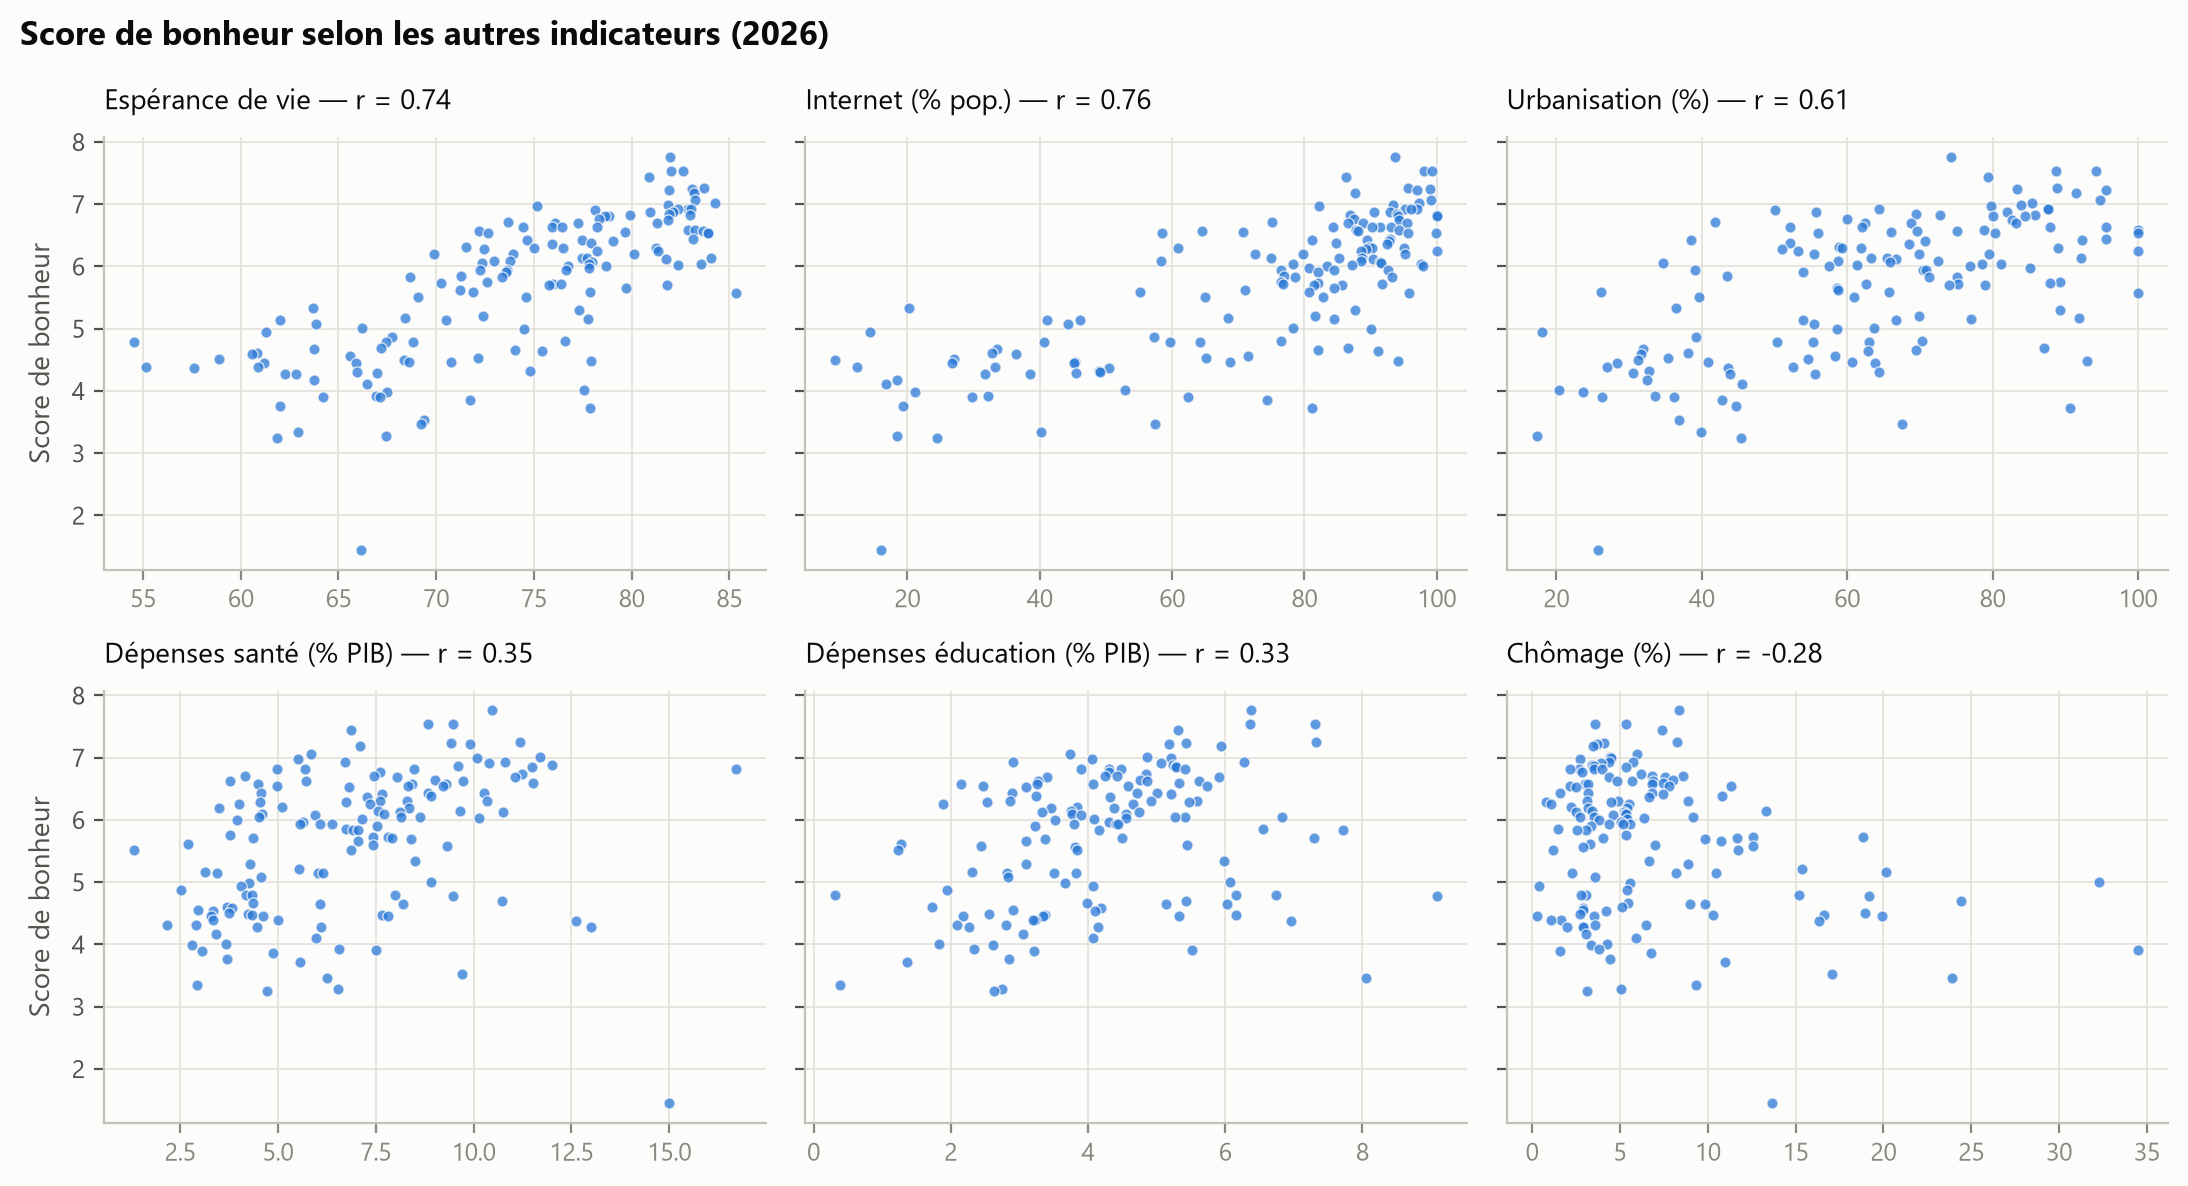

In [16]:
autres = ["esperance_vie", "internet_pct", "urbanisation_pct",
          "depenses_sante_pct_pib", "depenses_education_pct_pib", "chomage_pct"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, var in zip(axes.flat, autres):
    ax.scatter(df[var], df.score_bonheur, s=16, color=BLEU, alpha=0.75, edgecolor=FOND, linewidth=0.5)
    r = df[var].corr(df.score_bonheur)
    ax.set_title(f"{LIBELLES[var]} — r = {r:.2f}", fontsize=10, fontweight="normal")
for ax in axes[:, 0]:
    ax.set_ylabel("Score de bonheur")
fig.suptitle("Score de bonheur selon les autres indicateurs (2026)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

> **Lecture.**
> - **Espérance de vie** : le lien est net, mais il ne devient fort qu'au-delà d'environ 65 ans. En dessous, les pays (surtout africains) sont tous peu heureux.
> - **Internet** : la relation est presque linéaire. Mais à plus de 90 % de connexion, les scores vont de 4,5 à 7,8 : internet accompagne le développement sans le garantir (voir la requête de l'étape 5).
> - **Urbanisation, dépenses de santé et d'éducation** : les nuages sont dispersés, ce qui indique une tendance positive mais faible.
> - **Chômage** : pas de tendance claire pour la plupart des pays. Quelques pays à très fort chômage, en bas à droite, créent la corrélation négative.

### 6.6 Évolution du bonheur dans le temps

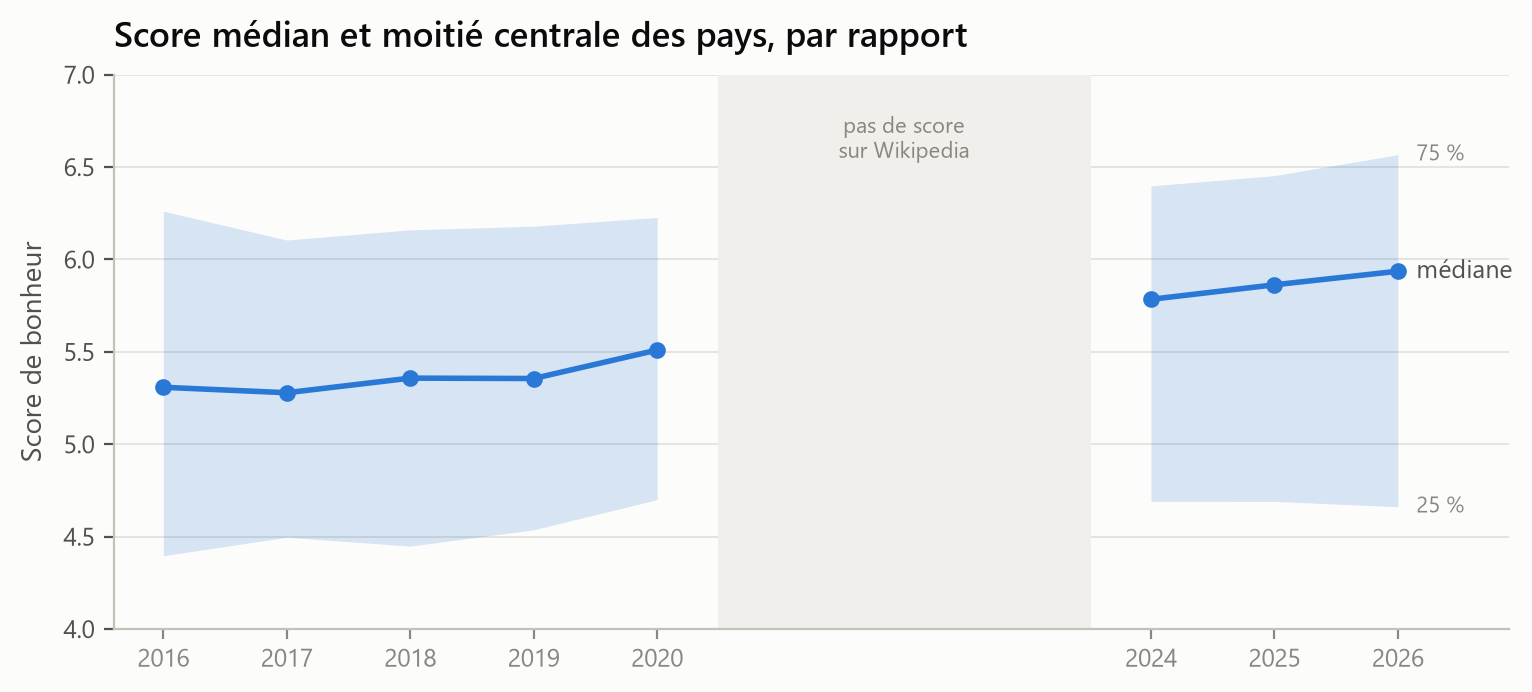

rapport,2016,2017,2018,2019,2020,2024,2025,2026
0.25,4.40,4.50,4.45,4.54,4.70,4.69,4.69,4.66
0.50,5.31,5.28,5.36,5.36,5.51,5.78,5.86,5.94
0.75,6.26,6.10,6.16,6.18,6.23,6.40,6.45,6.57


In [17]:
panel = pd.read_csv(PROCESSED / "worldpulse_panel.csv")
quartiles = panel.groupby("rapport").score_bonheur.quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots(figsize=(9, 3.6))
for periode in ([2016, 2017, 2018, 2019, 2020], [2024, 2025, 2026]):
    q = quartiles.loc[periode]
    ax.fill_between(q.index, q[0.25], q[0.75], color=BLEU, alpha=0.18, linewidth=0)
    ax.plot(q.index, q[0.5], color=BLEU, linewidth=2, marker="o", markersize=5)
ax.axvspan(2020.5, 2023.5, color="#f0efec")
ax.text(2022, 6.55, "pas de score\nsur Wikipedia", ha="center", fontsize=8, color=MUET)
ax.text(2026.15, quartiles.loc[2026, 0.5], "médiane", va="center", fontsize=9, color=ENCRE_2)
ax.text(2026.15, quartiles.loc[2026, 0.75], "75 %", va="center", fontsize=8, color=MUET)
ax.text(2026.15, quartiles.loc[2026, 0.25], "25 %", va="center", fontsize=8, color=MUET)
ax.set_xticks(quartiles.index)
ax.set_xlim(2015.6, 2026.9)
ax.set_ylim(4, 7)
ax.set_ylabel("Score de bonheur")
ax.grid(axis="x", visible=False)
ax.set_title("Score médian et moitié centrale des pays, par rapport")
plt.show()
quartiles.round(2).T

> **Lecture.** Le score médian passe de 5,31 (2016) à 5,94 (2026). La hausse est régulière, y compris après la période Covid. La hausse est surtout portée par le milieu de la distribution (médiane +0,6 point). Le quart des pays les moins heureux progresse deux fois moins (+0,3, de 4,40 à 4,66) : les pays en difficulté profitent peu de l'amélioration générale. Prudence toutefois : la liste des pays enquêtés change légèrement d'un rapport à l'autre (142 à 154 pays).

### 6.7 Synthèse de l'analyse exploratoire

> **À retenir**
>
> - **Le niveau de développement domine** : le PIB (en log), l'espérance de vie et internet sont les plus liés au bonheur (r ≈ 0,75–0,8). Le PIB explique à lui seul 62 % des écarts entre pays.
> - **Ces trois variables sont fortement corrélées entre elles** : il faudra interpréter leur importance comme un bloc.
> - **Les dépenses publiques (santé, éducation) et le chômage** sont faiblement liés au bonheur.
> - **Une part importante reste inexpliquée** : des pays d'Amérique latine sont plus heureux que leur PIB ne le laisse prévoir, et des pays en crise moins heureux. *Hypothèse* : des facteurs absents de nos données, comme les liens sociaux, la stabilité ou la gouvernance.
>
> **Choix pour la modélisation** : utiliser `log_pib` à la place du PIB brut, et imputer les valeurs manquantes dans la validation croisée.

---

<a id="s7"></a>

## 7. Modélisation et sélection des variables

**Question** : quelles variables expliquent le score de bonheur, et avec quelle précision peut-on le prédire pour un pays inconnu ?

Le choix des variables n'est pas fait « à l'œil » : il est **justifié par des critères chiffrés**, avec des règles de décision **fixées avant de voir les résultats**. Script : `src/05_modelisation.py`.

| Étape | Ce qu'on fait | Pourquoi |
|---|---|---|
| 7.1 | Ajuster le modèle complet (7 variables) | Point de départ : ajustement global, significativité de chaque variable |
| 7.2 | Mesurer la multicolinéarité (VIF) | Des variables redondantes rendent les coefficients instables |
| 7.3 | Vérifier les hypothèses de la régression | Les p-valeurs ne sont valides que si les résidus se comportent bien |
| 7.4 | Évaluer les 127 combinaisons de variables | Trouver le meilleur sous-ensemble, sans en oublier |
| 7.5 | Contrôle 1 : stabilité du Lasso | Une variable utile doit être retenue sur la plupart des échantillons |
| 7.6 | Contrôle 2 : régression sur composantes principales (ACP) | Une alternative à la sélection face à la multicolinéarité |
| 7.7 | Validation croisée imbriquée, puis décision | Mesurer honnêtement chaque procédure de sélection et choisir |
| 7.8 | Comparaison finale avec les modèles d'arbres | Le modèle linéaire retenu est-il compétitif ? |
| 7.9–7.11 | Modèle final : coefficients, erreurs, importance | Interpréter |

**Métriques utilisées**

| Métrique | Calcul | Lecture |
|---|---|---|
| **R²** | part de la variance du score expliquée | 1 = parfait, 0 = pas mieux que la moyenne |
| **R² ajusté** | R² pénalisé par le nombre de variables | n'augmente que si la variable ajoutée apporte vraiment |
| **AIC / BIC** | qualité d'ajustement − pénalité de complexité (plus forte pour le BIC) | plus bas = meilleur compromis |
| **Cp de Mallows** | erreur estimée du sous-modèle | bon modèle : Cp proche du nombre de paramètres |
| **RMSE / MAE** | erreur quadratique / absolue moyenne, en points de bonheur | plus bas = meilleur ; la RMSE pénalise les grosses erreurs |
| **p-valeur** | probabilité d'observer un tel coefficient si la variable n'avait aucun effet | < 0,05 : effet statistiquement significatif |
| **VIF** | à quel point une variable est prédite par les autres | > 5 : redondance notable ; > 10 : forte |

**Deux familles d'évaluation, à ne pas confondre :**
- **sur l'échantillon** (R², R² ajusté, AIC, BIC, Cp, p-valeurs) : le modèle est jugé sur les données qui ont servi à l'ajuster. Calcul sur les **134 pays complets**, car `statsmodels` n'accepte pas les valeurs manquantes ;
- **hors échantillon** (RMSE, MAE, R² en validation croisée) : le modèle est jugé sur des pays qu'il n'a **jamais vus**. Il y a **5 plis × 10 répétitions = 50 évaluations**, toujours **les mêmes plis** pour tous les modèles. Le calcul porte sur les **146 pays**, avec une imputation par la médiane apprise sur les plis d'entraînement seulement, pour éviter toute fuite de données.

**Règles fixées à l'avance :**
- seuil de significativité de 5 % ;
- **règle de l'écart-type** pour départager des modèles : parmi ceux dont l'erreur est à moins d'une erreur standard de la meilleure, on garde le plus simple ;
- la **validation croisée imbriquée** arbitre entre les procédures de sélection.

### 7.1 Le modèle complet : ajustement et coefficients

In [18]:
metriques_complet = pd.read_csv(REPORTS / "modele_complet_metriques.csv", index_col=0)["valeur"]
print("Ajustement sur l'échantillon (134 pays complets)")
print(f"  R² = {metriques_complet.r2:.3f}   R² ajusté = {metriques_complet.r2_ajuste:.3f}   "
      f"AIC = {metriques_complet.aic:.1f}   BIC = {metriques_complet.bic:.1f}")
print(f"  Test F global : F = {metriques_complet.f:.1f}, p = {metriques_complet.p_f:.1e}")

complet = pd.read_csv(REPORTS / "modele_complet_coefficients.csv")
tableau(complet.assign(significatif=np.where(complet.p_valeur < 0.05, "oui", "non"))
        .set_index("variable")[["coefficient", "erreur_standard", "t", "p_valeur", "ic_bas", "ic_haut",
                                "coefficient_standardise", "significatif"]], 3)

Ajustement sur l'échantillon (134 pays complets)
  R² = 0.764   R² ajusté = 0.751   AIC = 223.7   BIC = 246.9
  Test F global : F = 58.4, p = 1.4e-36


,Coefficient,Erreur standard,t,p-valeur,IC 95 % bas,IC 95 % haut,Coef. standardisé,Significatif (5 %)
variable,,,,,,,,
PIB / habitant (log),9.92e-01,2.57e-01,3.87,0.00e+00,4.84e-01,1.50e+00,4.86e-01,oui
Espérance de vie,1.00e-03,1.50e-02,0.10,9.20e-01,-2.80e-02,3.10e-02,1.10e-02,non
Internet (% pop.),1.20e-02,5.00e-03,2.48,1.50e-02,2.00e-03,2.10e-02,2.87e-01,oui
Urbanisation (%),0.00e+00,4.00e-03,0.06,9.50e-01,-7.00e-03,7.00e-03,5.00e-03,non
Dépenses santé (% PIB),6.00e-02,2.20e-02,2.75,7.00e-03,1.70e-02,1.03e-01,1.65e-01,oui
Dépenses éducation (% PIB),9.50e-02,3.60e-02,2.63,1.00e-02,2.30e-02,1.66e-01,1.49e-01,oui
Chômage (%),-5.90e-02,9.00e-03,-6.37,0.00e+00,-7.80e-02,-4.10e-02,-3.28e-01,oui


> **Lecture.**
> - **Le modèle dans son ensemble est très significatif** (test F, p ≈ 10⁻³⁶). Il explique 76 % de la variance **sur l'échantillon** (R² ajusté 0,75). Ce chiffre est optimiste, puisque le modèle est jugé sur les données qui ont servi à l'ajuster. La performance sur des pays inconnus est mesurée en 7.4 et 7.7.
> - **5 variables sur 7 sont significatives à 5 %** : PIB, internet, chômage, dépenses de santé et dépenses d'éducation.
> - **L'espérance de vie (p = 0,92) et l'urbanisation (p = 0,95) ne le sont pas** : une fois les autres variables connues, elles n'apportent rien. Pour l'espérance de vie, cela ne veut pas dire que la santé ne compte pas : son information est déjà portée par le PIB et internet (voir 7.2).
> - Le **coefficient standardisé** est l'effet d'une hausse d'un écart-type de la variable, en points de bonheur. Il permet de comparer des variables d'unités différentes.

### 7.2 Multicolinéarité : le facteur d'inflation de la variance (VIF)

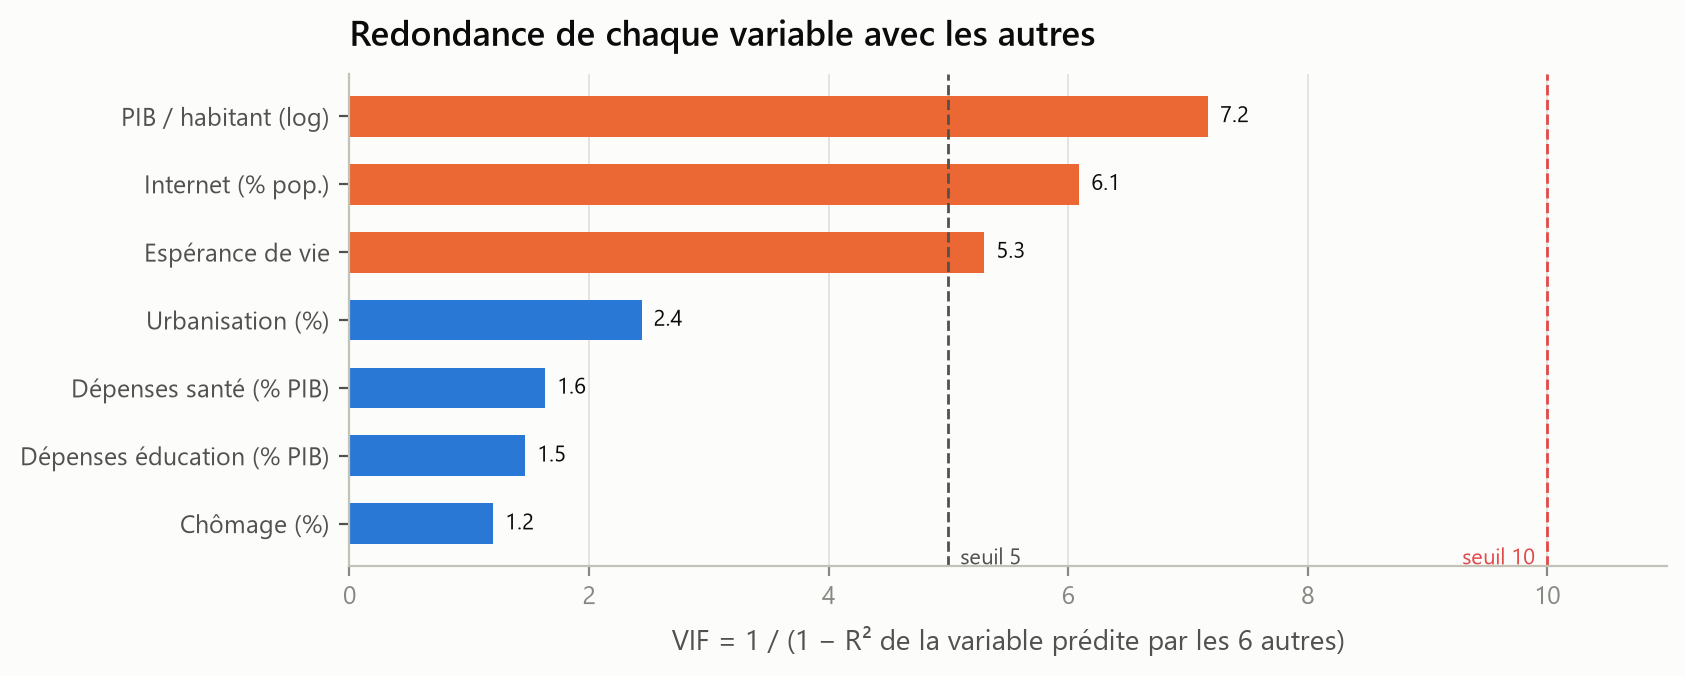

In [19]:
vif = pd.read_csv(REPORTS / "modele_vif.csv").sort_values("vif")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
couleurs = [ORANGE if v > 5 else BLEU for v in vif.vif]
ax.barh([LIBELLES[v] for v in vif.variable], vif.vif, height=0.6, color=couleurs)
for i, v in enumerate(vif.vif):
    ax.text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=8, color=ENCRE)
ax.axvline(5, color=ENCRE_2, linewidth=1, linestyle="--")
ax.text(5.1, -0.6, "seuil 5", fontsize=8, color=ENCRE_2)
ax.axvline(10, color=ROUGE, linewidth=1, linestyle="--")
ax.text(9.9, -0.6, "seuil 10", fontsize=8, color=ROUGE, ha="right")
ax.set_xlim(0, 11)
ax.set_xlabel("VIF = 1 / (1 − R² de la variable prédite par les 6 autres)")
ax.grid(axis="y", visible=False)
ax.set_title("Redondance de chaque variable avec les autres")
plt.show()

> **Lecture.** Le VIF mesure à quel point une variable est prévisible à partir des autres. Un VIF de 7 signifie que la variance de son coefficient est multipliée par 7 à cause de cette redondance.
> - **PIB (7,2), internet (6,1) et espérance de vie (5,3) dépassent le seuil de 5** : c'est le « bloc développement » repéré à l'étape 6.
> - **Aucune variable ne dépasse 10** : la multicolinéarité est **notable mais pas critique**. Les coefficients restent estimables, mais avec des intervalles de confiance élargis.
> - Ce résultat justifie de **tester des sous-ensembles** (7.4) et des méthodes qui gèrent la redondance (Lasso en 7.5, ACP en 7.6).

### 7.3 Hypothèses de la régression

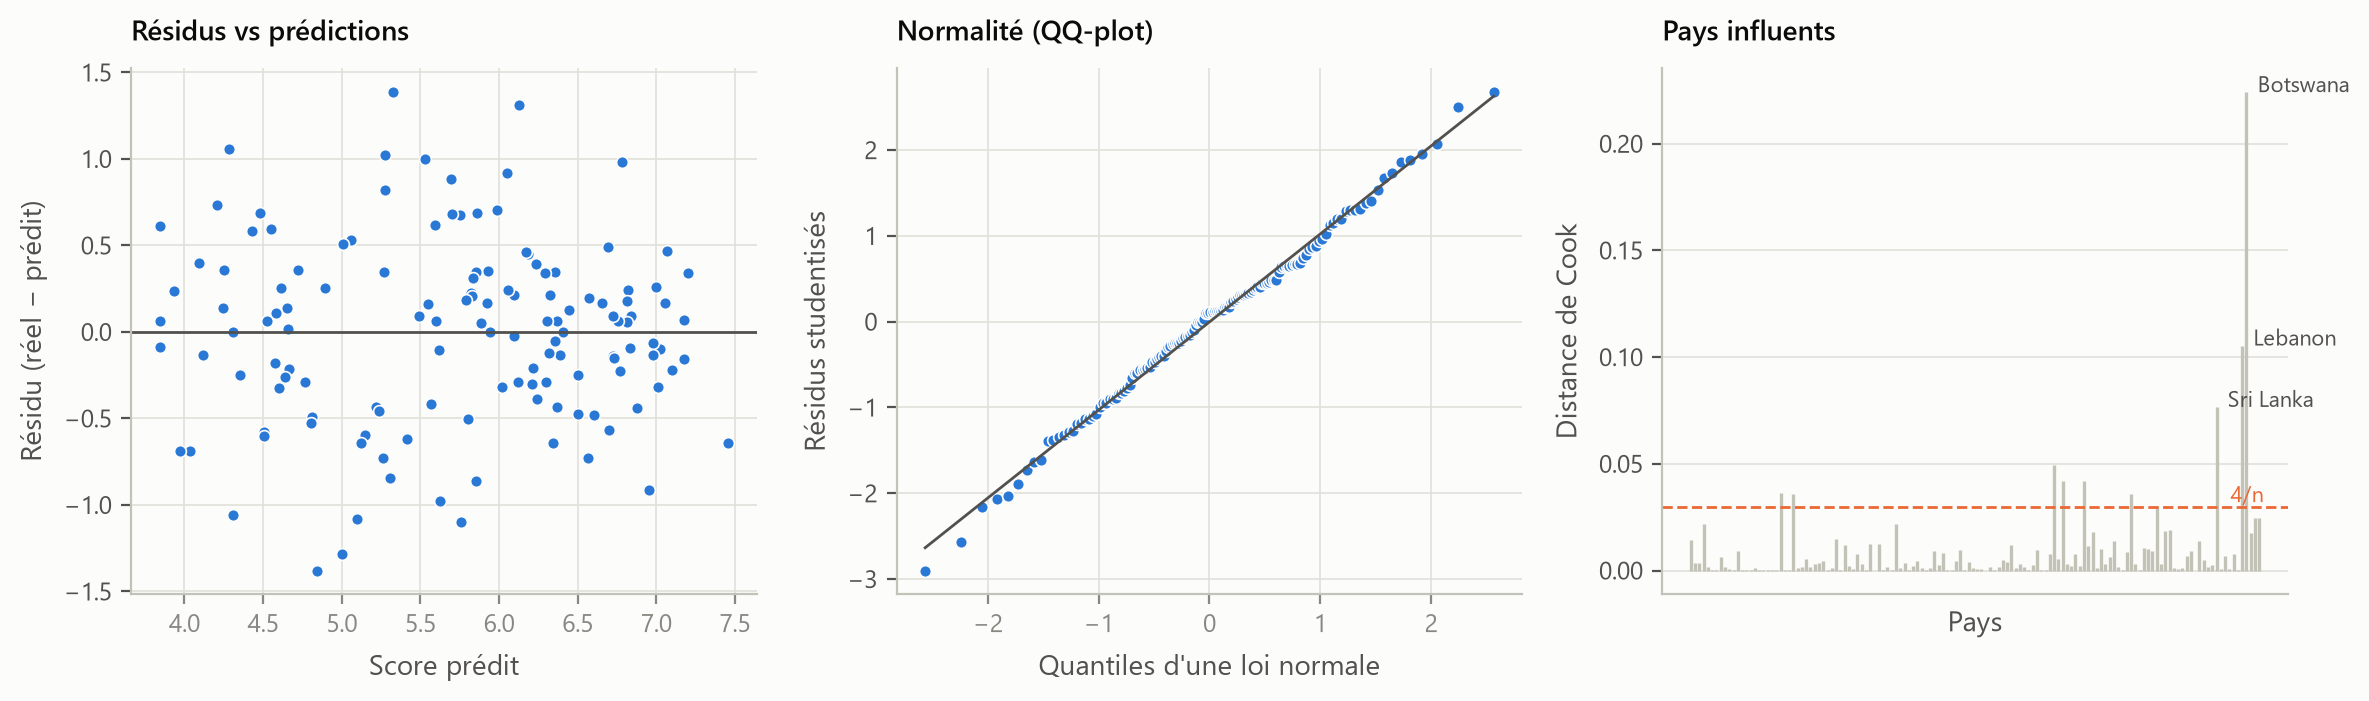

,test,hypothèse vérifiée,p-valeur,conclusion (seuil 5 %)
0,Shapiro-Wilk,normalité des résidus,0.94,non rejetée
1,Jarque-Bera,normalité des résidus,0.98,non rejetée
2,Breusch-Pagan,variance constante (homoscédasticité),0.12,non rejetée


In [20]:
diag = pd.read_csv(REPORTS / "modele_complet_diagnostics_pays.csv")
n = len(diag)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
ax.scatter(diag.prediction, diag.residu, s=18, color=BLEU, edgecolor=FOND, linewidth=0.6)
ax.axhline(0, color=ENCRE_2, linewidth=1)
ax.set_xlabel("Score prédit"); ax.set_ylabel("Résidu (réel − prédit)")
ax.set_title("Résidus vs prédictions", fontsize=10)

ax = axes[1]
(theoriques, observes), (pente, origine, _) = stats.probplot(diag.residu_studentise, dist="norm")
ax.scatter(theoriques, observes, s=18, color=BLEU, edgecolor=FOND, linewidth=0.6)
ax.plot(theoriques, origine + pente * theoriques, color=ENCRE_2, linewidth=1)
ax.set_xlabel("Quantiles d'une loi normale"); ax.set_ylabel("Résidus studentisés")
ax.set_title("Normalité (QQ-plot)", fontsize=10)

ax = axes[2]
ax.vlines(range(n), 0, diag.distance_cook, color=GRIS, linewidth=1.2)
ax.axhline(4 / n, color=ORANGE, linewidth=1, linestyle="--")
ax.text(n, 4 / n, "4/n", fontsize=8, color=ORANGE, va="bottom", ha="right")
for i, p in diag.nlargest(3, "distance_cook").iterrows():
    ax.annotate(p.pays, (i, p.distance_cook), xytext=(4, 0), textcoords="offset points", fontsize=8, color=ENCRE_2)
ax.set_xlabel("Pays"); ax.set_ylabel("Distance de Cook"); ax.set_xticks([])
ax.grid(axis="x", visible=False)
ax.set_title("Pays influents", fontsize=10)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "test": ["Shapiro-Wilk", "Jarque-Bera", "Breusch-Pagan"],
    "hypothèse vérifiée": ["normalité des résidus", "normalité des résidus", "variance constante (homoscédasticité)"],
    "p-valeur": [metriques_complet.p_shapiro, metriques_complet.p_jarque_bera, metriques_complet.p_breusch_pagan],
}).assign(**{"conclusion (seuil 5 %)": lambda t: np.where(t["p-valeur"] > 0.05, "non rejetée", "rejetée")}).round(3)

> **Lecture.** Les p-valeurs et les intervalles de confiance de la régression supposent des résidus **normaux**, de **variance constante**, et un modèle qui ne dépend pas de **quelques pays**.
> - **Normalité : vérifiée.** Les points du QQ-plot suivent la droite, et les tests de Shapiro-Wilk (p = 0,94) et de Jarque-Bera (p = 0,98) ne la rejettent pas. L'asymétrie (−0,04) et le kurtosis (3,04) sont ceux d'une loi normale (0 et 3).
> - **Variance constante : vérifiée.** Le nuage des résidus ne s'évase pas, et le test de Breusch-Pagan donne p = 0,12. Les erreurs standard classiques sont donc valides, sans correction « robuste ».
> - **Pays influents** : 10 pays dépassent le seuil indicatif 4/n, avec en tête le Botswana, le Liban et le Sri Lanka. Mais **aucune distance de Cook n'approche 1**, le seuil d'une influence forte, et aucun résidu studentisé ne dépasse ±3 : **aucun pays ne fait à lui seul les résultats**. L'Afghanistan n'apparaît pas ici, car il lui manque une valeur et il est donc exclu des 134 pays complets.

### 7.4 Sélection exhaustive : les 127 combinaisons de variables

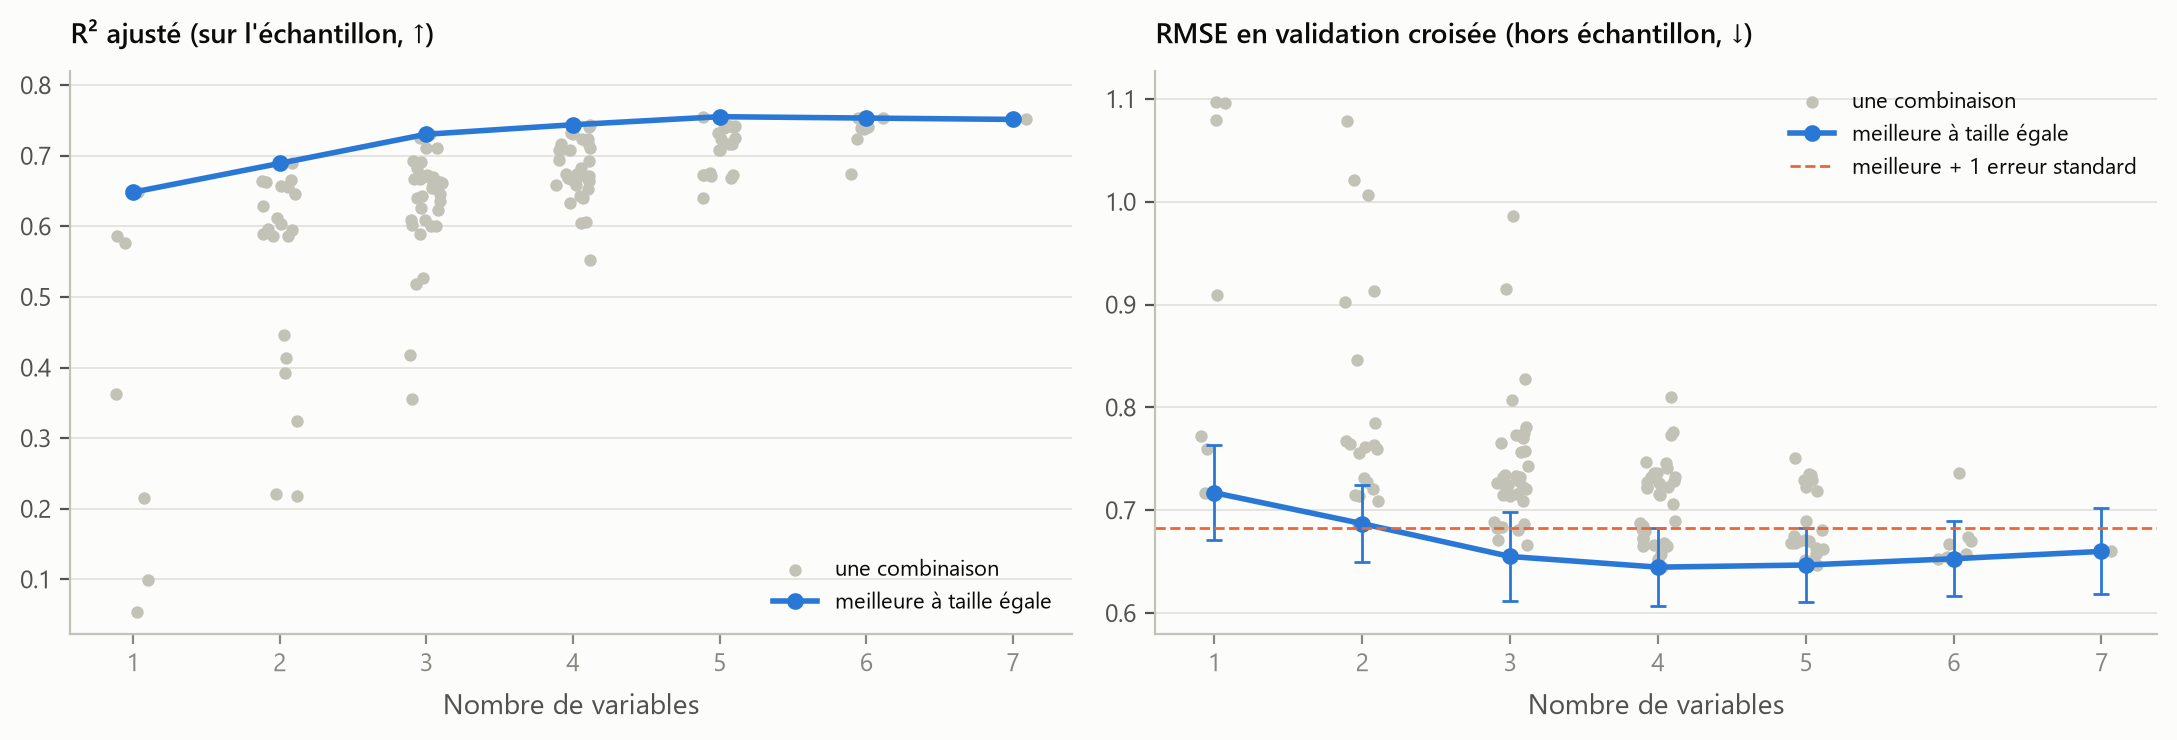

,Variables,Nb variables,R² ajusté,AIC,BIC,Cp de Mallows,RMSE (CV),Erreur standard RMSE,R² (CV)
R² ajusté max,log_pib + internet + dép_sante + dép_education...,5,0.76,219.75,237.14,4.01,0.65,0.04,0.65
AIC min,log_pib + internet + dép_sante + dép_education...,5,0.76,219.75,237.14,4.01,0.65,0.04,0.65
BIC min,log_pib + internet + dép_sante + dép_education...,5,0.76,219.75,237.14,4.01,0.65,0.04,0.65
Cp de Mallows min,log_pib + internet + dép_sante + dép_education...,5,0.76,219.75,237.14,4.01,0.65,0.04,0.65
RMSE CV min,log_pib + internet + dép_education + chomage,4,0.74,226.21,240.70,10.22,0.65,0.04,0.66
Règle de l'écart-type,log_pib + dép_education + chomage,3,0.73,230.79,242.38,14.98,0.66,0.04,0.65
Les 7 variables,log_pib + esp_vie + internet + urbanisation + ...,7,0.75,223.73,246.92,8.00,0.66,0.04,0.64


In [21]:
sous_ensembles = pd.read_csv(REPORTS / "modele_sous_ensembles.csv")
meilleurs = sous_ensembles.loc[sous_ensembles.groupby("nb_variables")["rmse_cv"].idxmin()]
reference = sous_ensembles.loc[sous_ensembles.rmse_cv.idxmin()]
seuil_1es = reference.rmse_cv + reference.rmse_cv_es

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, colonne, titre in [(axes[0], "r2_ajuste", "R² ajusté (sur l'échantillon, ↑)"),
                           (axes[1], "rmse_cv", "RMSE en validation croisée (hors échantillon, ↓)")]:
    ax.scatter(sous_ensembles.nb_variables + alea.uniform(-0.12, 0.12, len(sous_ensembles)),
               sous_ensembles[colonne], s=12, color=GRIS, label="une combinaison")
    meilleur_k = sous_ensembles.loc[sous_ensembles.groupby("nb_variables")[colonne].agg(
        "idxmax" if colonne == "r2_ajuste" else "idxmin")]
    ax.plot(meilleur_k.nb_variables, meilleur_k[colonne], color=BLEU, linewidth=2, marker="o", markersize=5,
            label="meilleure à taille égale")
    ax.set_xlabel("Nombre de variables")
    ax.set_title(titre, fontsize=10)
    ax.grid(axis="x", visible=False)
axes[1].errorbar(meilleurs.nb_variables, meilleurs.rmse_cv, yerr=meilleurs.rmse_cv_es, fmt="none",
                 ecolor=BLEU, elinewidth=1, capsize=3)
axes[1].axhline(seuil_1es, color=ORANGE, linewidth=1, linestyle="--", label="meilleure + 1 erreur standard")
axes[1].set_ylim(0.58, sous_ensembles.rmse_cv.max() + 0.03)
axes[0].set_ylim(sous_ensembles.r2_ajuste.min() - 0.03, 0.82)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

colonnes = ["variables", "nb_variables", "r2_ajuste", "aic", "bic", "cp_mallows", "rmse_cv", "rmse_cv_es", "r2_cv"]
criteres = {"R² ajusté max": sous_ensembles.r2_ajuste.idxmax(), "AIC min": sous_ensembles.aic.idxmin(),
            "BIC min": sous_ensembles.bic.idxmin(), "Cp de Mallows min": sous_ensembles.cp_mallows.idxmin(),
            "RMSE CV min": sous_ensembles.rmse_cv.idxmin(),
            "Règle de l'écart-type": sous_ensembles[sous_ensembles.rmse_cv <= seuil_1es]
                                        .sort_values(["nb_variables", "rmse_cv"]).index[0],
            "Les 7 variables": sous_ensembles.nb_variables.idxmax()}
abreger = lambda s: (s.replace("depenses_", "dép_").replace("_pct_pib", "").replace("_pct", "")
                      .replace("esperance_vie", "esp_vie"))
choix_criteres = sous_ensembles.loc[list(criteres.values()), colonnes].set_axis(list(criteres), axis=0)
tableau(choix_criteres.assign(variables=choix_criteres.variables.map(abreger)), 3)

> **Lecture.** Chaque point gris est une des 127 combinaisons possibles. La ligne bleue relie la meilleure combinaison à chaque nombre de variables.
> - **Sur l'échantillon, les quatre critères sont d'accord** : R² ajusté, AIC, BIC et Cp de Mallows désignent tous **le même modèle à 5 variables** (PIB, internet, santé, éducation, chômage). C'est exactement le modèle complet **sans** l'espérance de vie ni l'urbanisation, les deux variables non significatives en 7.1. Son Cp (4,0) est proche de son nombre de variables : il ne laisse pas de côté d'information utile.
> - **Hors échantillon, la courbe est plate de 3 à 7 variables** : la RMSE varie de 0,645 à 0,660, bien moins que son incertitude (± 0,04). Statistiquement, ces modèles se valent.
> - **La règle de l'écart-type** appliquée à ce tableau retiendrait 3 variables (PIB, éducation, chômage). Mais **choisir et évaluer sur les mêmes données est optimiste** : chaque RMSE de ce tableau est légèrement trop flatteuse pour la combinaison qui « gagne ». Seule la validation croisée imbriquée (7.7) permet de trancher honnêtement.

### 7.5 Contrôle 1 : stabilité du Lasso

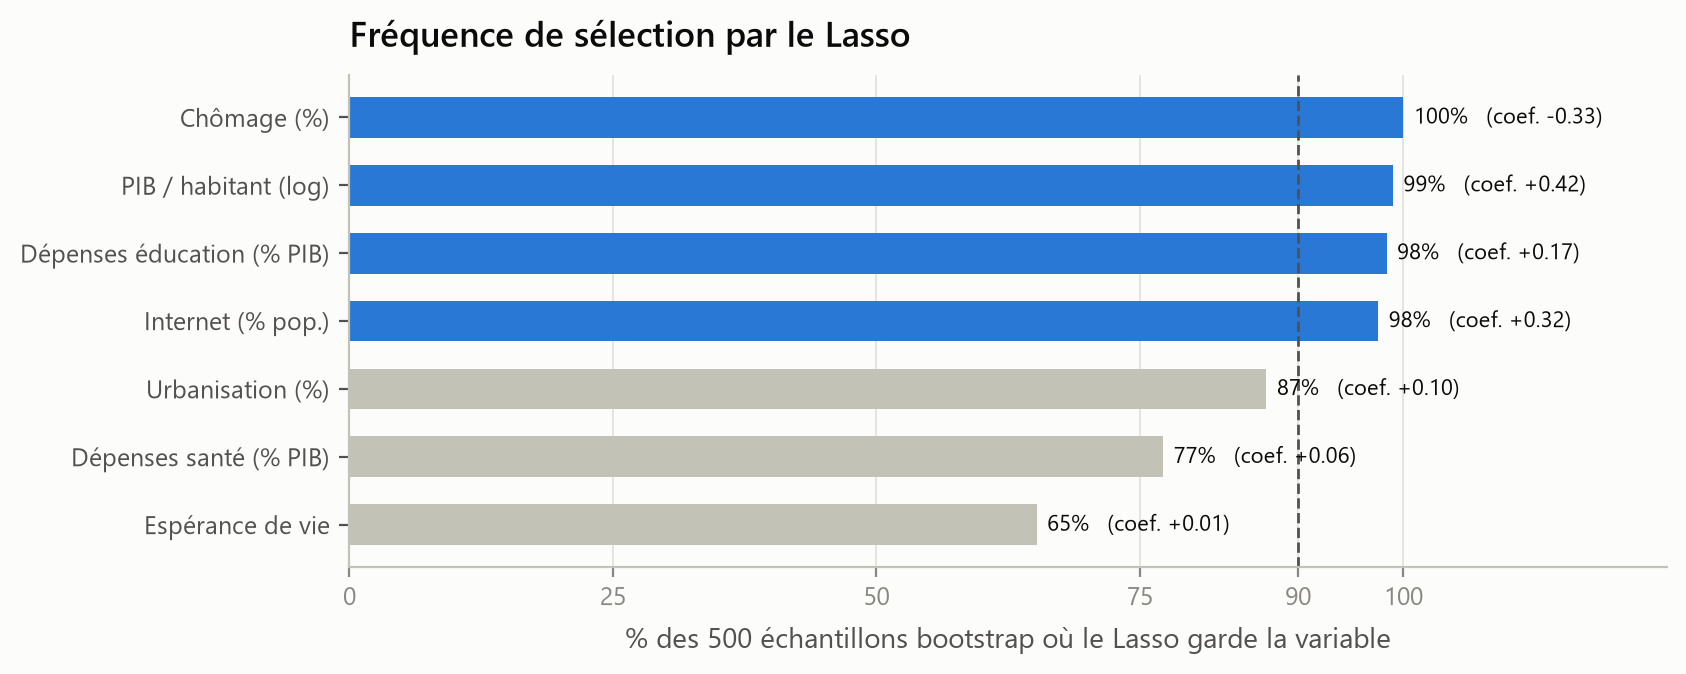

In [22]:
stabilite = pd.read_csv(REPORTS / "modele_lasso_stabilite.csv").sort_values("frequence_selection")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh([LIBELLES[v] for v in stabilite.variable], stabilite.frequence_selection * 100, height=0.6,
        color=[BLEU if f >= 0.9 else GRIS for f in stabilite.frequence_selection])
for i, (f, c) in enumerate(zip(stabilite.frequence_selection, stabilite.coefficient_lasso)):
    ax.text(f * 100 + 1, i, f"{f:.0%}   (coef. {c:+.2f})", va="center", fontsize=8, color=ENCRE)
ax.axvline(90, color=ENCRE_2, linewidth=1, linestyle="--")
ax.set_xlim(0, 125)
ax.set_xticks([0, 25, 50, 75, 90, 100])
ax.set_xlabel("% des 500 échantillons bootstrap où le Lasso garde la variable")
ax.grid(axis="y", visible=False)
ax.set_title("Fréquence de sélection par le Lasso")
plt.show()

> **Lecture.** Le **Lasso** est une régression qui pénalise la taille des coefficients. La force de la pénalité est choisie par validation croisée, et elle peut mettre à zéro les variables inutiles. On l'a relancé sur **500 échantillons bootstrap**, c'est-à-dire des pays tirés au hasard avec remise. Une variable vraiment utile doit être gardée presque à chaque fois.
> - **Gardées dans plus de 97 % des échantillons** : chômage (100 %), PIB, éducation, internet. C'est le noyau stable.
> - **Moins stables** : urbanisation (87 %), santé (77 %) et surtout **espérance de vie (65 %)**, la moins stable, avec un coefficient quasi nul (+0,01).
> - Le Lasso choisi par validation croisée pénalise peu, et il garde en moyenne 6,6 variables : il **réduit** les coefficients des variables faibles plutôt que de les éliminer. Il confirme l'ordre d'importance trouvé en 7.1 et 7.4.

### 7.6 Contrôle 2 : régression sur composantes principales (ACP)

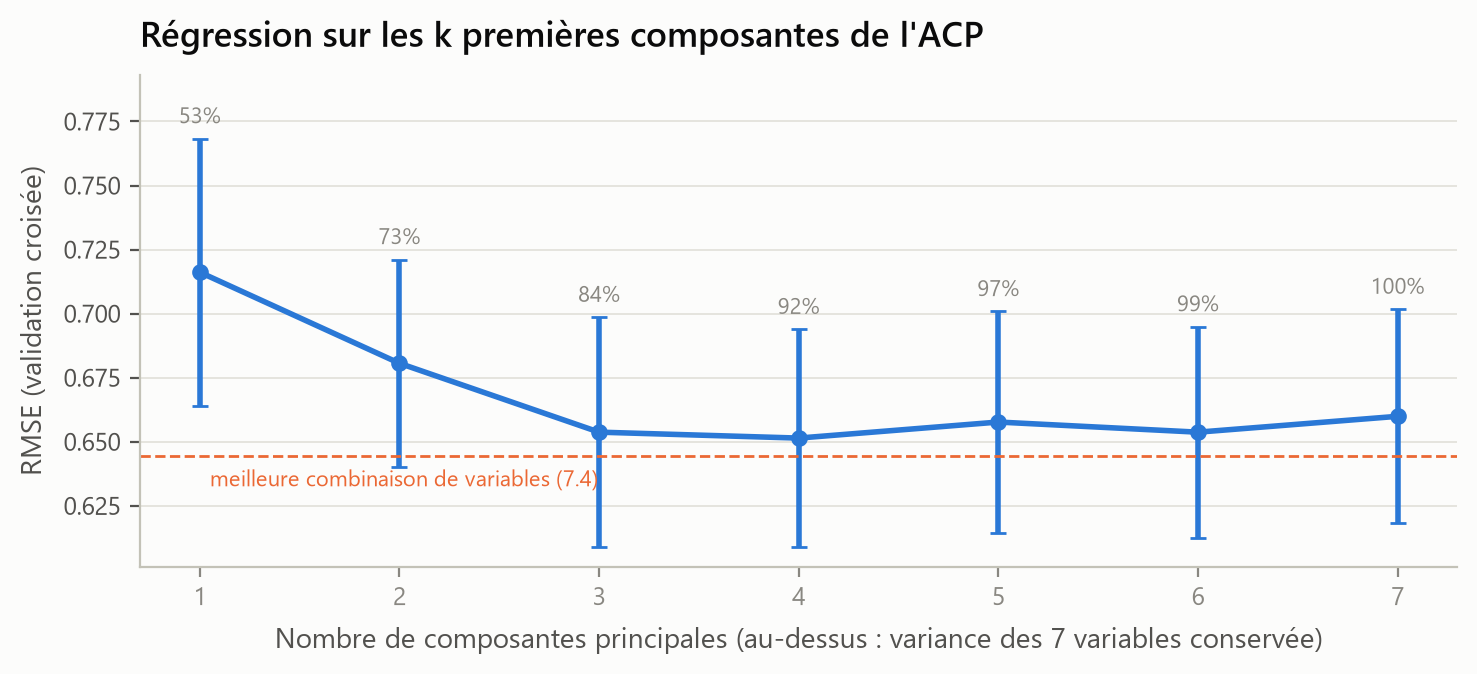

In [23]:
pcr = pd.read_csv(REPORTS / "modele_pcr.csv")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.errorbar(pcr.nb_composantes, pcr.rmse_cv, yerr=pcr.rmse_cv_es, color=BLEU, marker="o", markersize=5,
            capsize=3, linewidth=2)
for _, r in pcr.iterrows():
    ax.text(r.nb_composantes, r.rmse_cv + r.rmse_cv_es + 0.006, f"{r.variance_expliquee_cumulee:.0%}",
            ha="center", fontsize=8, color=MUET)
meilleure = sous_ensembles.rmse_cv.min()
ax.axhline(meilleure, color=ORANGE, linewidth=1, linestyle="--")
ax.text(1.05, meilleure - 0.012, "meilleure combinaison de variables (7.4)", fontsize=8, color=ORANGE, ha="left")
ax.set_ylim(None, (pcr.rmse_cv + pcr.rmse_cv_es).max() + 0.025)
ax.set_xlabel("Nombre de composantes principales (au-dessus : variance des 7 variables conservée)")
ax.set_ylabel("RMSE (validation croisée)")
ax.set_xticks(pcr.nb_composantes)
ax.grid(axis="x", visible=False)
ax.set_title("Régression sur les k premières composantes de l'ACP")
plt.show()

> **Lecture.** Au lieu de choisir des variables, on peut les **résumer** par une ACP, puis faire la régression sur les premières composantes. Ces composantes sont non corrélées entre elles, donc il n'y a plus de multicolinéarité.
> - Avec **1 composante** (le « niveau de développement », 53 % de la variance), la RMSE est de 0,72, comme le PIB seul.
> - Il faut **3 à 4 composantes** (84–92 % de la variance) pour atteindre 0,65, **le même niveau** que la meilleure combinaison de variables, sans faire mieux.
> - **Conclusion** : l'ACP n'améliore pas la prédiction, et elle rend les coefficients **illisibles**, car chaque composante mélange les 7 variables. On garde donc une sélection de variables. L'ACP reste utilisée pour la **visualisation** au clustering (section 8).

### 7.7 Validation croisée imbriquée et décision

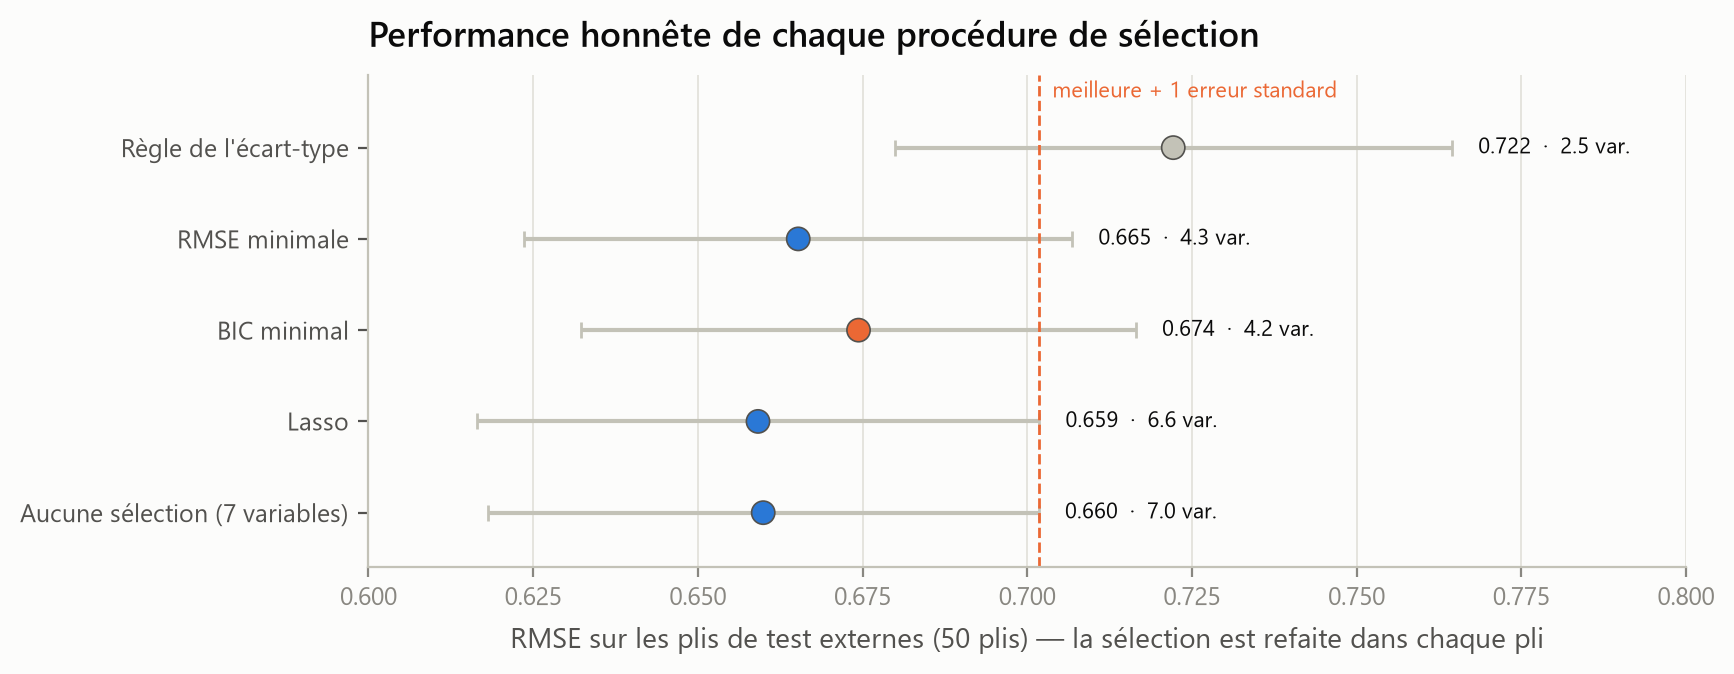

Procédure retenue : BIC minimal
Appliquée aux 146 pays, elle retient : log_pib + internet_pct + depenses_sante_pct_pib + depenses_education_pct_pib + chomage_pct


,RMSE,Erreur standard RMSE,MAE,R²,Nb variables (moyenne)
procedure,,,,,
Règle de l'écart-type,0.72,0.04,0.55,0.57,2.52
RMSE minimale,0.67,0.04,0.50,0.64,4.28
BIC minimal,0.67,0.04,0.50,0.63,4.16
Lasso,0.66,0.04,0.49,0.64,6.58
Aucune sélection (7 variables),0.66,0.04,0.49,0.64,7.00


In [24]:
imbriquee = pd.read_csv(REPORTS / "modele_cv_imbriquee.csv")
decision = pd.read_csv(REPORTS / "modele_decision.csv").iloc[0]
PROCEDURES = ["Règle de l'écart-type", "RMSE minimale", "BIC minimal", "Lasso", "Aucune sélection (7 variables)"]
resume = imbriquee.groupby("procedure").agg(
    rmse=("RMSE", "mean"), rmse_es=("RMSE", lambda r: r.std() / np.sqrt(5)), mae=("MAE", "mean"),
    r2=("R2", "mean"), nb_variables_moyen=("nb_variables", "mean")).loc[PROCEDURES]
seuil = resume.rmse.min() + resume.loc[resume.rmse.idxmin(), "rmse_es"]

fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(resume))[::-1]
couleurs = [ORANGE if p == decision.procedure else (BLEU if r <= seuil else GRIS)
            for p, r in zip(resume.index, resume.rmse)]
ax.errorbar(resume.rmse, y, xerr=resume.rmse_es, fmt="none", ecolor=GRIS, elinewidth=1.5, capsize=3)
ax.scatter(resume.rmse, y, s=70, color=couleurs, edgecolor=ENCRE_2, linewidth=0.6, zorder=3)
for yi, (p, r) in zip(y, resume.iterrows()):
    ax.text(r.rmse + r.rmse_es + 0.004, yi, f"{r.rmse:.3f}  ·  {r.nb_variables_moyen:.1f} var.", va="center",
            fontsize=8, color=ENCRE)
ax.axvline(seuil, color=ORANGE, linewidth=1, linestyle="--")
ax.text(seuil + 0.002, len(resume) - 0.45, "meilleure + 1 erreur standard", fontsize=8, color=ORANGE)
ax.set_yticks(y, resume.index)
ax.set_xlim(0.6, 0.8)
ax.set_ylim(-0.6, len(resume) - 0.2)
ax.set_xlabel("RMSE sur les plis de test externes (50 plis) — la sélection est refaite dans chaque pli")
ax.grid(axis="y", visible=False)
ax.set_title("Performance honnête de chaque procédure de sélection")
plt.show()

print(f"Procédure retenue : {decision.procedure}")
print(f"Appliquée aux 146 pays, elle retient : {decision.variables}")
tableau(resume, 3)

In [25]:
# Combinaisons choisies par chaque procédure dans les 50 plis : la sélection est-elle stable ?
(imbriquee[imbriquee.procedure.isin(PROCEDURES[:3])]
 .assign(variables=lambda d: d.variables.map(abreger))
 .groupby("procedure")["variables"].value_counts().groupby(level=0).head(3).rename("nb_plis").to_frame())

nb_plis
procedure             variables                                                  
BIC minimal           log_pib + internet + dép_sante + chomage                 18
                      log_pib + internet + dép_sante + dép_education ...       16
                      log_pib + dép_education + chomage                         8
RMSE minimale         log_pib + internet + dép_education + chomage             28
                      log_pib + internet + urbanisation + dép_educati...        7
                      log_pib + internet + dép_sante + dép_education ...        6
Règle de l'écart-type log_pib + dép_education + chomage                        16
                      log_pib + chomage                                        14
                      internet + chomage                                        8

> **Lecture.** On répète **toute la démarche de sélection** à l'intérieur de chacun des 50 plis :
> 1. sur les 80 % de pays d'entraînement, on évalue les 127 combinaisons et on choisit selon la procédure ;
> 2. on entraîne le modèle choisi ;
> 3. on le teste sur les 20 % de pays restants, qui n'ont servi ni au choix ni à l'entraînement.
>
> On mesure ainsi la performance de la **procédure**, et non celle d'une combinaison choisie a posteriori.
>
> - **La règle de l'écart-type échoue** : RMSE 0,722 et R² 0,57, nettement moins bien que les autres. Sur environ 117 pays, elle retient souvent des modèles à 2 variables, trop simples. Elle est **hors du seuil**, et donc écartée.
> - **Les quatre autres procédures sont statistiquement à égalité** : RMSE de 0,659 à 0,674, toutes sous le seuil de 0,702.
> - **Décision**, par la même règle appliquée aux procédures : on garde la **plus simple** des procédures à égalité, le **BIC minimal**, avec 4,2 variables en moyenne.
> - **Appliqué aux 146 pays, le BIC retient 5 variables** : PIB, internet, dépenses de santé, dépenses d'éducation, chômage. Il écarte l'espérance de vie et l'urbanisation.
> - **Stabilité** : d'un pli à l'autre, le BIC hésite surtout sur les dépenses de santé et d'éducation. Le PIB, internet et le chômage sont presque toujours retenus.
>
> **Performance honnête du modèle final** : celle de la procédure, mesurée par la validation croisée imbriquée, soit **R² ≈ 0,63 et RMSE ≈ 0,67**. Le score de la section suivante (0,65) est un peu optimiste, car les variables y ont été choisies sur l'ensemble des pays.
>
> **Ce que confirment les 5 critères** :
> - l'**espérance de vie** et l'**urbanisation** n'apportent rien une fois les autres variables connues (p > 0,9 ; absentes du meilleur modèle selon les 4 critères sur l'échantillon ; espérance de vie la moins stable au Lasso) ;
> - le **chômage**, le **PIB** et **internet** sont indispensables.

### 7.8 Comparaison finale des modèles

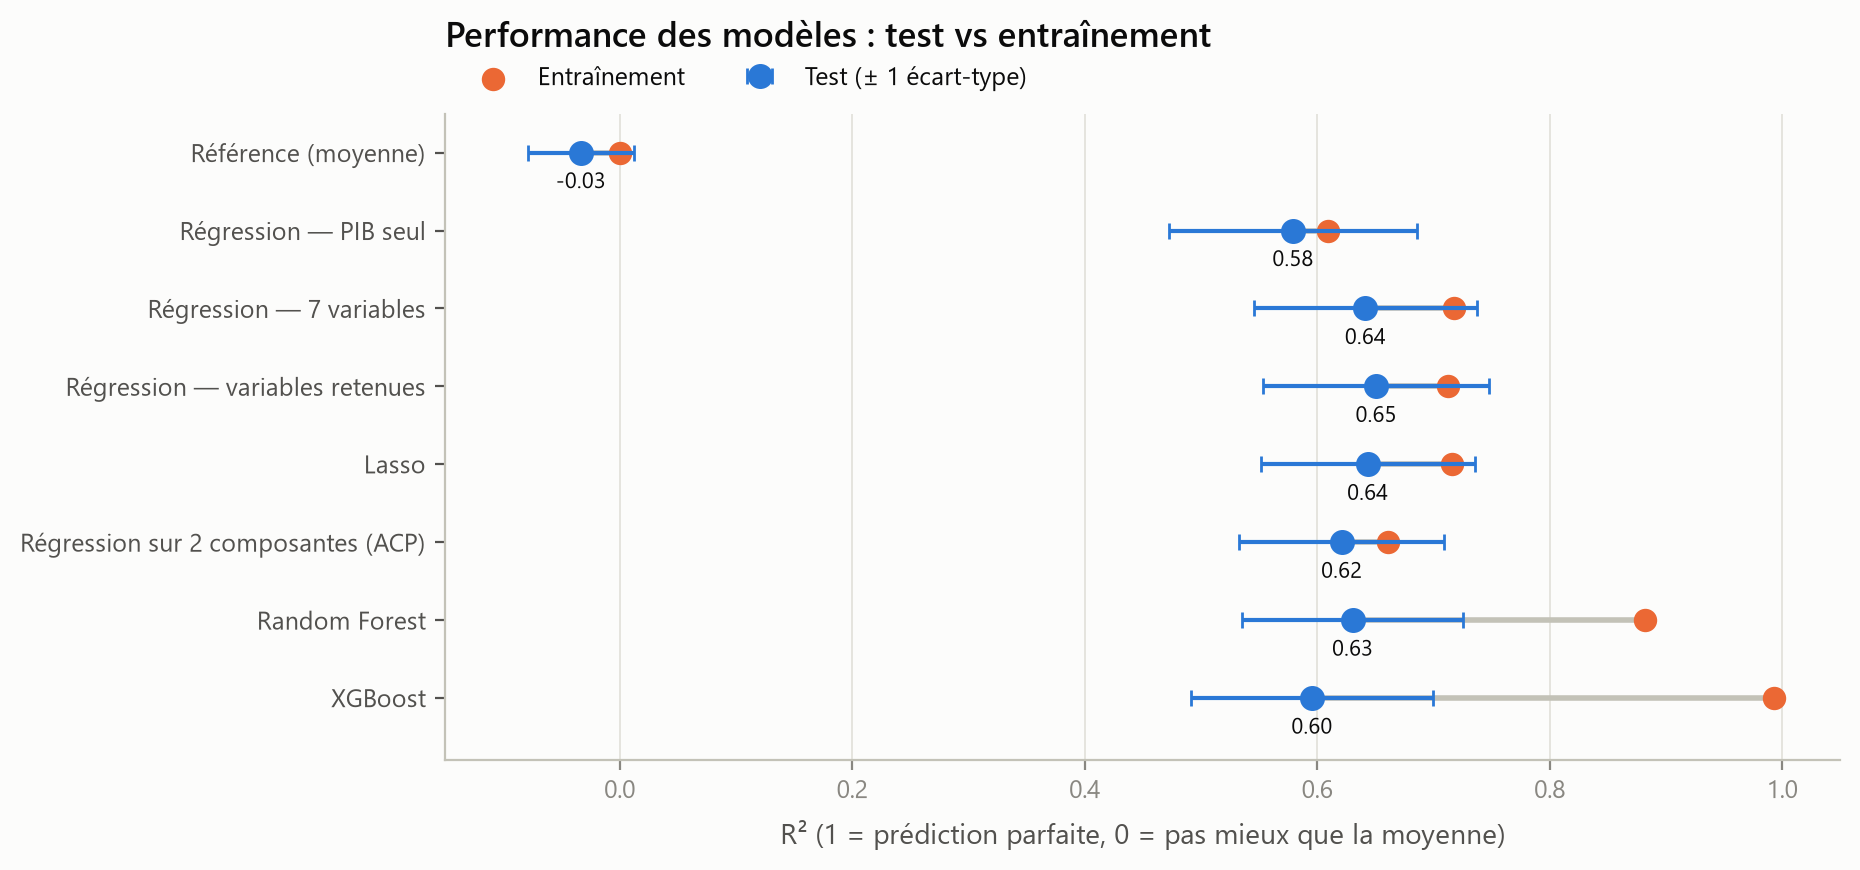

,MAE test,RMSE test,R² test,± R² test,R² entraînement
modele,,,,,
Référence (moyenne),0.96,1.14,-0.03,0.04,0.00
Régression — PIB seul,0.54,0.72,0.58,0.11,0.61
Régression — 7 variables,0.49,0.66,0.64,0.10,0.72
Régression — variables retenues,0.48,0.65,0.65,0.10,0.71
Lasso,0.49,0.66,0.64,0.09,0.72
Régression sur 2 composantes (ACP),0.51,0.68,0.62,0.09,0.66
Random Forest,0.50,0.67,0.63,0.10,0.88
XGBoost,0.54,0.70,0.60,0.10,0.99


In [26]:
scores = pd.read_csv(REPORTS / "modele_scores_cv.csv")
ordre = list(scores.modele.unique())
perf = scores.groupby("modele").agg(**{
    "MAE test": ("MAE", "mean"), "RMSE test": ("RMSE", "mean"), "R² test": ("R2", "mean"),
    "± R² test": ("R2", "std"), "R² entraînement": ("R2_entrainement", "mean")}).loc[ordre]

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(ordre))[::-1]
ax.hlines(y, perf["R² test"], perf["R² entraînement"], color=GRIS, linewidth=2)
ax.scatter(perf["R² entraînement"], y, s=55, color=ORANGE, zorder=3, label="Entraînement")
ax.errorbar(perf["R² test"], y, xerr=perf["± R² test"], fmt="o", color=BLEU, markersize=8,
            capsize=3, zorder=4, label="Test (± 1 écart-type)")
for yi, r2 in zip(y, perf["R² test"]):
    ax.text(r2, yi - 0.25, f"{r2:.2f}", ha="center", va="top", fontsize=8, color=ENCRE)
ax.set_yticks(y, ordre)
ax.set_xlim(-0.15, 1.05)
ax.set_ylim(-0.8, len(ordre) - 0.5)
ax.set_xlabel("R² (1 = prédiction parfaite, 0 = pas mieux que la moyenne)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title("Performance des modèles : test vs entraînement", pad=24)
plt.show()
perf.round(3)

> **Lecture.** Tous les modèles sont évalués sur les mêmes 50 plis.
> - **Le modèle retenu** (régression à 5 variables) a la plus faible erreur : R² 0,65, MAE 0,48 point sur une échelle de 10. Ce chiffre est légèrement optimiste ; l'estimation honnête est 0,63 (7.7).
> - **Toutes les régressions sont proches** (0,62 à 0,65), et l'écart-type d'un pli à l'autre est de ± 0,10 : retirer 2 variables ne coûte rien en précision, et rend le modèle plus simple et plus stable.
> - **Les modèles d'arbres n'apportent rien** : le Random Forest (0,63) et XGBoost (0,60) apprennent par cœur les données d'entraînement (R² de 0,88 et 0,99), sans mieux généraliser. Avec 146 pays et des relations surtout linéaires, **la simplicité l'emporte**.
> - **Gain par rapport au PIB seul** : R² 0,58 → 0,65. Les autres variables apportent un gain réel, mais modeste.

### 7.9 Le modèle final : coefficients et interprétation

Modèle final (5 variables, 134 pays complets) : R² = 0.764, R² ajusté = 0.755, AIC = 219.8, BIC = 237.1  (modèle complet : R² ajusté 0.751, BIC 246.9)


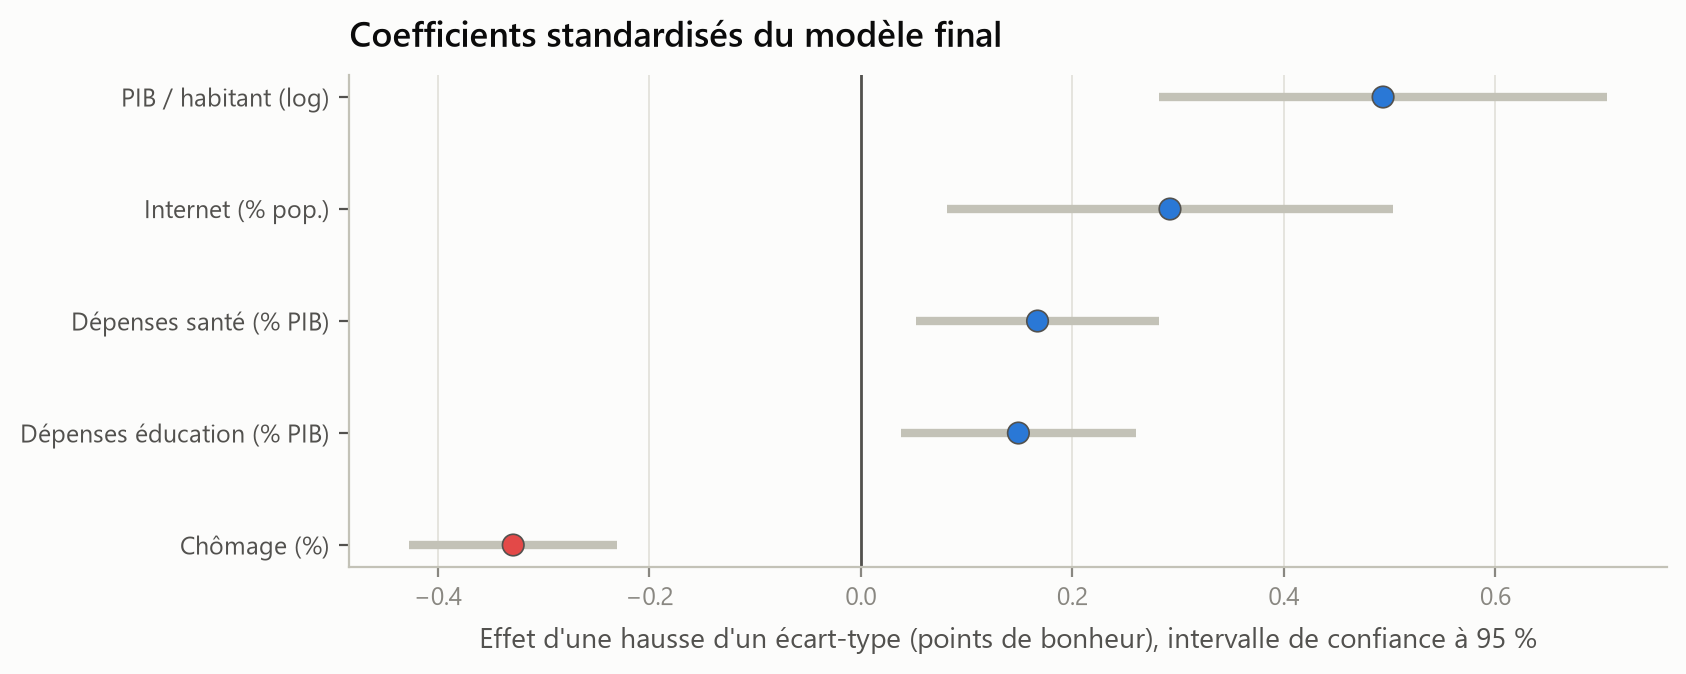

,Coefficient,Erreur standard,p-valeur,IC 95 % bas,IC 95 % haut,Coef. standardisé
variable,,,,,,
PIB / habitant (log),1.01,2.18e-01,0.00e+00,5.75e-01,1.44,0.49
Internet (% pop.),0.01,4.00e-03,7.00e-03,3.00e-03,0.02,0.29
Dépenses santé (% PIB),0.06,2.10e-02,5.00e-03,1.90e-02,0.10,0.17
Dépenses éducation (% PIB),0.10,3.60e-02,9.00e-03,2.40e-02,0.17,0.15
Chômage (%),-0.06,9.00e-03,0.00e+00,-7.70e-02,-0.04,-0.33


In [27]:
final = pd.read_csv(REPORTS / "modele_final_coefficients.csv")
metriques_final = pd.read_csv(REPORTS / "modele_final_metriques.csv", index_col=0)["valeur"]
print(f"Modèle final ({int(metriques_final.nb_variables)} variables, {int(metriques_final.n)} pays complets) : "
      f"R² = {metriques_final.r2:.3f}, R² ajusté = {metriques_final.r2_ajuste:.3f}, "
      f"AIC = {metriques_final.aic:.1f}, BIC = {metriques_final.bic:.1f}  "
      f"(modèle complet : R² ajusté {metriques_complet.r2_ajuste:.3f}, BIC {metriques_complet.bic:.1f})")

ordre_final = final.sort_values("coefficient_standardise")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(ordre_final))
ax.errorbar(ordre_final.coefficient_standardise, y,
            xerr=[ordre_final.coefficient_standardise - ordre_final.ic_bas_standardise,
                  ordre_final.ic_haut_standardise - ordre_final.coefficient_standardise],
            fmt="none", ecolor=GRIS, elinewidth=3, capsize=0)
ax.scatter(ordre_final.coefficient_standardise, y, s=60, zorder=3, edgecolor=ENCRE_2, linewidth=0.6,
           color=np.where(ordre_final.coefficient_standardise >= 0, BLEU, ROUGE))
ax.set_yticks(y, [LIBELLES[v] for v in ordre_final.variable])
ax.axvline(0, color=ENCRE_2, linewidth=1)
ax.set_xlabel("Effet d'une hausse d'un écart-type (points de bonheur), intervalle de confiance à 95 %")
ax.grid(axis="y", visible=False)
ax.set_title("Coefficients standardisés du modèle final")
plt.show()

tableau(final.set_index("variable")[
    ["coefficient", "erreur_standard", "p_valeur", "ic_bas", "ic_haut", "coefficient_standardise"]], 3)

> **Lecture.**
> - **Retirer 2 variables améliore le modèle** : le R² ajusté passe de 0,751 à 0,755, et le BIC de 246,9 à 237,1. Le modèle explique autant avec moins de variables.
> - **Les 5 coefficients sont significatifs** (p ≤ 0,01), et aucun intervalle de confiance ne contient 0. Les hypothèses de la régression étant vérifiées (7.3), ces intervalles sont fiables.
>
> **Effet de chaque variable, les autres restant égales :**
>
> | Variable | Coefficient (IC 95 %) | Traduction concrète |
> |---|---|---|
> | PIB / habitant (log10) | +1,01 [0,58 ; 1,44] | PIB × 2 → **+0,30 point** |
> | Internet (% pop.) | +0,012 [0,003 ; 0,020] | +10 points d'accès à internet → **+0,12 point** |
> | Chômage (%) | −0,060 [−0,077 ; −0,042] | +5 points de chômage → **−0,30 point** |
> | Dépenses d'éducation (% PIB) | +0,095 [0,024 ; 0,165] | +1 point de PIB → **+0,09 point** |
> | Dépenses de santé (% PIB) | +0,061 [0,019 ; 0,102] | +1 point de PIB → **+0,06 point** |
>
> - **Le PIB reste le premier facteur**, mais son effet « à autres variables égales » (+1,0 par ×10) est **plus faible** que son effet seul à l'étape 6 (+1,8) : une partie de l'effet du PIB passe par internet et l'emploi.
> - **Le chômage est le deuxième facteur en ampleur** : −0,33 point par écart-type, avec l'intervalle de confiance le plus étroit.
> - **Les dépenses publiques de santé et d'éducation ont un effet positif, réel mais faible.**
>
> ⚠️ Ce sont des **associations** entre pays, pas des effets causaux garantis.

### 7.10 Quels pays le modèle prédit-il mal ?

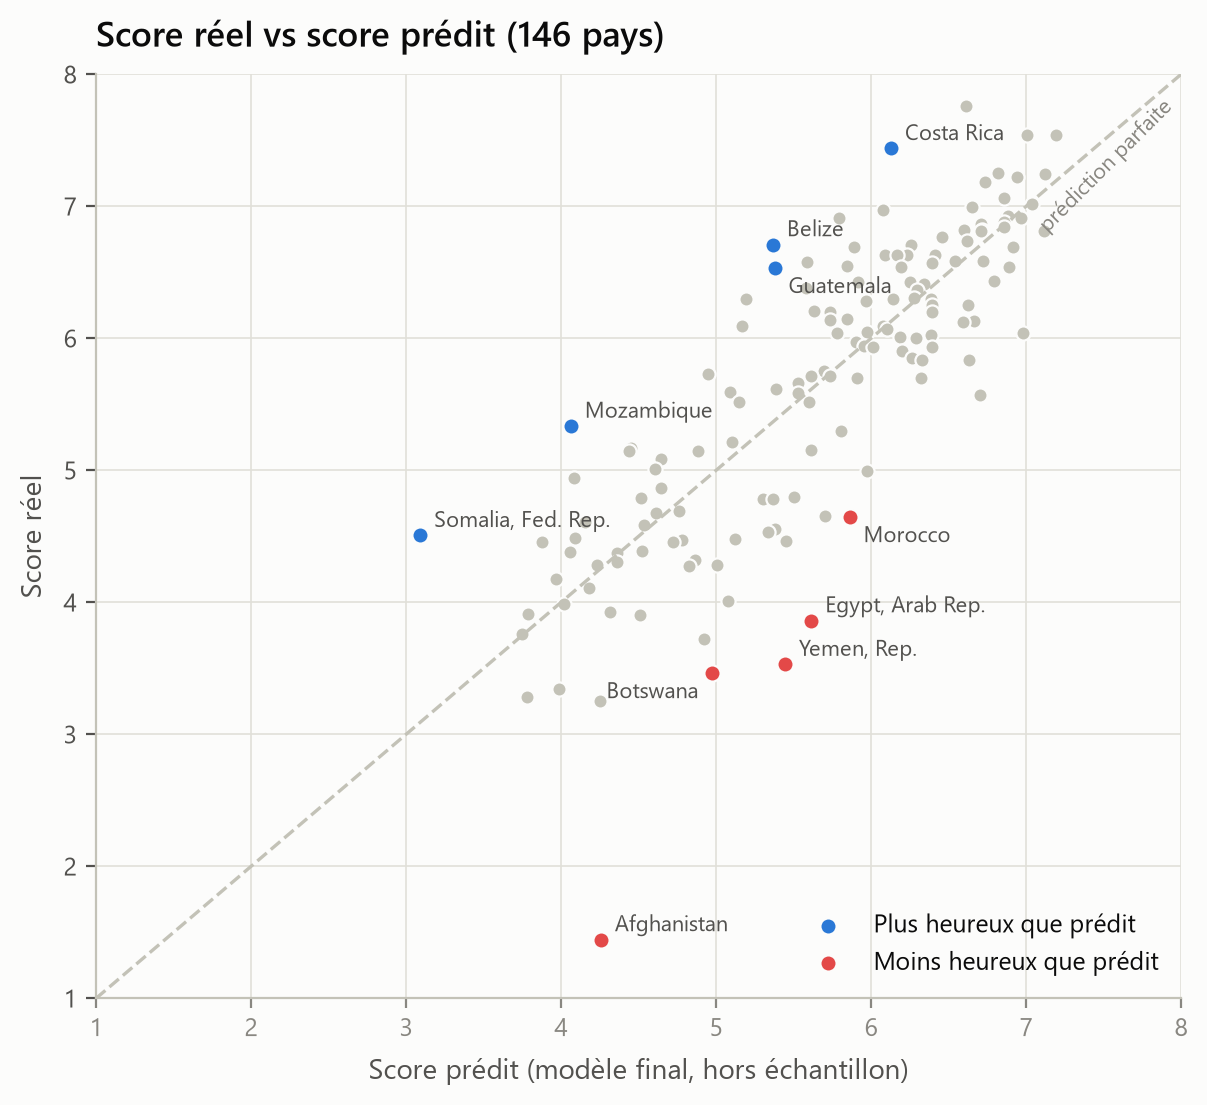

In [28]:
pred = pd.read_csv(REPORTS / "modele_predictions.csv")
PRED = "prediction_regression_finale"
pred["ecart"] = pred.score_bonheur - pred[PRED]
sous_estimes, sur_estimes = pred.nlargest(5, "ecart"), pred.nsmallest(5, "ecart")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([1, 8], [1, 8], color=GRIS, linewidth=1.2, linestyle="--")
ax.text(7.95, 7.75, "prédiction parfaite", ha="right", fontsize=8, color=MUET, rotation=45, rotation_mode="anchor")
ax.scatter(pred[PRED], pred.score_bonheur, s=26, color=GRIS, edgecolor=FOND, linewidth=0.8)
ax.scatter(sous_estimes[PRED], sous_estimes.score_bonheur, s=34, color=BLEU, edgecolor=FOND, linewidth=0.8,
           label="Plus heureux que prédit")
ax.scatter(sur_estimes[PRED], sur_estimes.score_bonheur, s=34, color=ROUGE, edgecolor=FOND, linewidth=0.8,
           label="Moins heureux que prédit")
decalages = {"Egypt, Arab Rep.": (5, 3, "left"), "Botswana": (-5, -9, "right"), "Morocco": (5, -9, "left"),
             "Guatemala": (5, -9, "left")}
for _, p in pd.concat([sous_estimes, sur_estimes]).iterrows():
    dx, dy, alignement = decalages.get(p.pays, (5, 3, "left"))
    ax.annotate(p.pays, (p[PRED], p.score_bonheur), xytext=(dx, dy), textcoords="offset points",
                ha=alignement, fontsize=8, color=ENCRE_2)
ax.set_xlim(1, 8); ax.set_ylim(1, 8)
ax.set_xlabel("Score prédit (modèle final, hors échantillon)")
ax.set_ylabel("Score réel")
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("Score réel vs score prédit (146 pays)")
plt.show()

> **Lecture.** Chaque pays est prédit par un modèle qui ne l'a **pas vu à l'entraînement**. La plupart des points suivent la diagonale.
> - Le modèle **surestime** le bonheur de pays en guerre ou en crise : Afghanistan (−2,8 points), Yémen, Égypte, Botswana, Maroc.
> - Il **sous-estime** celui de la Somalie, du Belize, du Costa Rica, du Mozambique et du Guatemala.
>
> *Hypothèse* : ces erreurs viendraient de facteurs que nos indicateurs ne mesurent pas, comme les conflits ou les liens sociaux. La gouvernance est testée à la section 9.

### 7.11 Importance des variables : permutation et SHAP

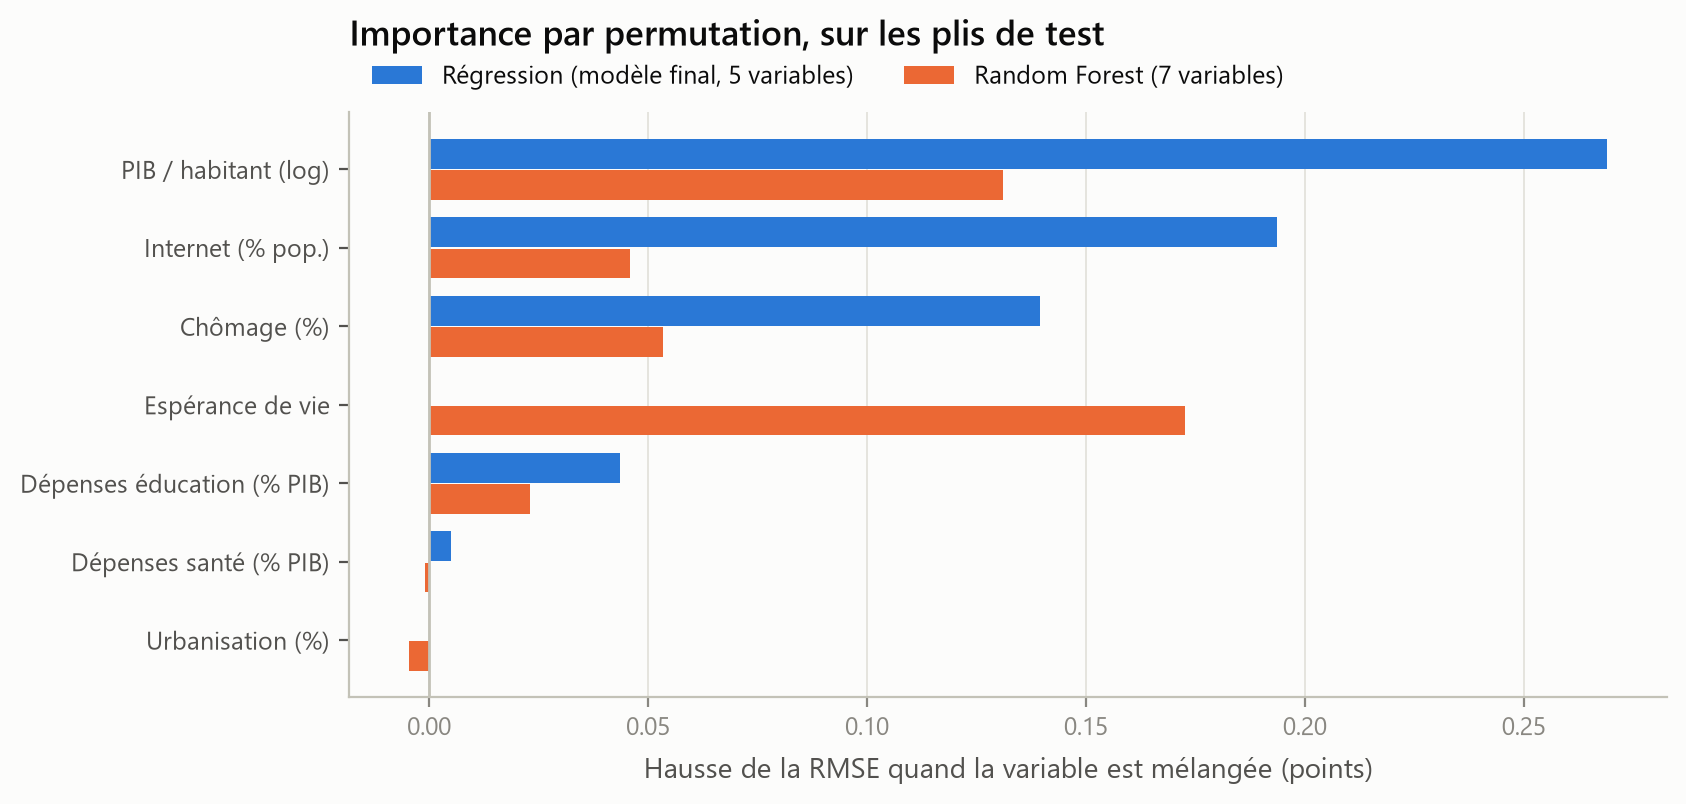

In [29]:
importance = (pd.read_csv(REPORTS / "modele_importance.csv")
                .groupby(["variable", "modele"])["importance"].mean().unstack())
importance = importance.loc[importance.mean(axis=1).sort_values().index].rename(index=LIBELLES)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(importance))
ax.barh(y + 0.2, importance["Régression — variables retenues"], height=0.38, color=BLEU,
        label="Régression (modèle final, 5 variables)")
ax.barh(y - 0.2, importance["Random Forest"], height=0.38, color=ORANGE, label="Random Forest (7 variables)")
ax.set_yticks(y, importance.index)
ax.axvline(0, color=GRIS, linewidth=1)
ax.set_xlabel("Hausse de la RMSE quand la variable est mélangée (points)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title("Importance par permutation, sur les plis de test", pad=24)
plt.show()

> **Lecture.** L'**importance par permutation** consiste à mélanger au hasard les valeurs d'une variable, ce qui casse son lien avec le score, puis à mesurer de combien l'erreur augmente sur des pays de test.
> - **Modèle final** : PIB (+0,27 point d'erreur), internet (+0,19) et chômage (+0,14) dominent. L'espérance de vie et l'urbanisation sont à 0, puisqu'elles ne sont pas dans le modèle.
> - **Le Random Forest**, qui dispose des 7 variables, s'appuie d'abord sur **l'espérance de vie**, puis sur le PIB. C'est l'effet de la multicolinéarité (7.2) : l'espérance de vie et le PIB portent la même information, et chaque modèle en privilégie une. La bonne lecture reste celle d'un **bloc développement**, quelle que soit la variable qui le représente.
> - **Le chômage est le facteur n° 2 dans les deux modèles.**

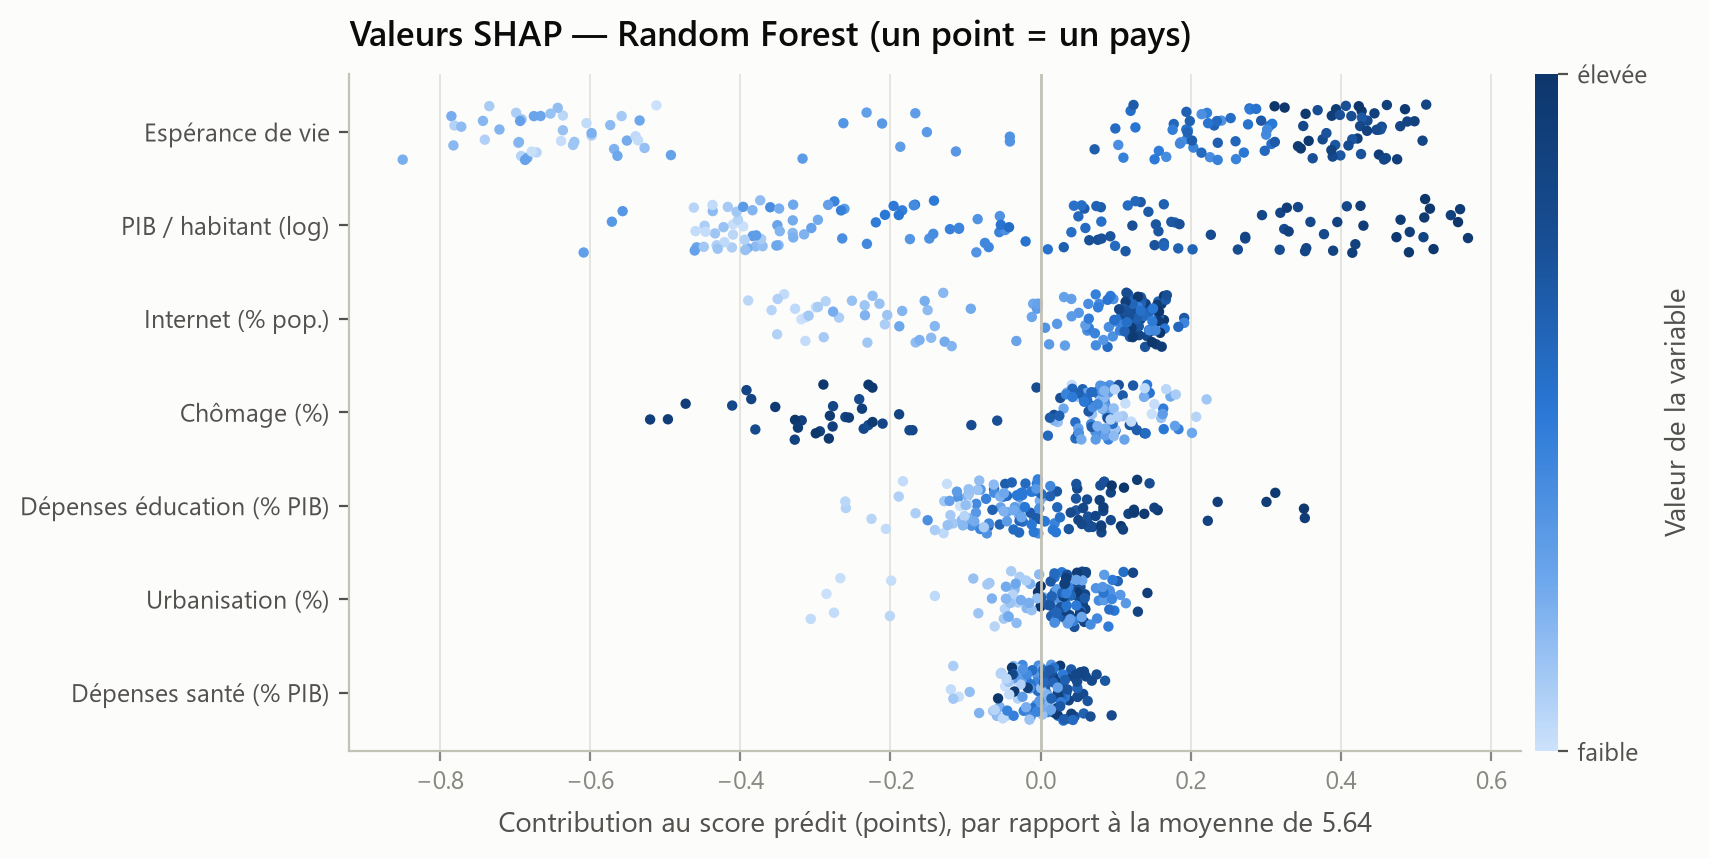

In [30]:
shap_df = pd.read_csv(REPORTS / "modele_shap.csv")
colonnes = shap_df.filter(like="shap_").abs().mean().sort_values().index
sequentielle = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])

fig, ax = plt.subplots(figsize=(9, 4.4))
for i, col in enumerate(colonnes):
    variable = col.removeprefix("shap_")
    points = ax.scatter(shap_df[col], i + alea.uniform(-0.3, 0.3, len(shap_df)), s=14,
                        c=shap_df[variable].rank(pct=True), cmap=sequentielle, vmin=0, vmax=1, edgecolor="none")
ax.set_yticks(range(len(colonnes)), [LIBELLES[c.removeprefix("shap_")] for c in colonnes])
ax.axvline(0, color=GRIS, linewidth=1)
ax.set_xlabel(f"Contribution au score prédit (points), par rapport à la moyenne de {shap_df.valeur_de_base[0]:.2f}")
ax.grid(axis="y", visible=False)
barre = fig.colorbar(points, ax=ax, ticks=[0, 1], pad=0.01, aspect=30)
barre.ax.set_yticklabels(["faible", "élevée"])
barre.set_label("Valeur de la variable", color=ENCRE_2)
barre.outline.set_visible(False)
ax.set_title("Valeurs SHAP — Random Forest (un point = un pays)")
plt.show()

> **Lecture.** Les valeurs **SHAP** décomposent chaque prédiction du Random Forest en contributions de chaque variable. Pour chaque pays, on part du score moyen (5,64), puis chaque variable ajoute ou retire des points.
> - **Espérance de vie et PIB** ont les contributions les plus étendues, d'environ −0,8 à +0,6 point.
> - **Le chômage agit à l'envers** : un chômage élevé (points foncés, à gauche) fait baisser le score prédit.
> - Les autres variables contribuent peu. SHAP confirme ainsi, par une méthode indépendante du modèle linéaire, la hiérarchie **développement > chômage > le reste**.

### 7.12 Synthèse de la modélisation

> **À retenir**
>
> | Question | Réponse | Preuve |
> |---|---|---|
> | Quelles variables garder ? | **PIB, internet, chômage, dépenses de santé, dépenses d'éducation** | R² ajusté, AIC, BIC et Cp d'accord ; procédure BIC retenue en validation croisée imbriquée |
> | Lesquelles écarter ? | **Espérance de vie, urbanisation** | p > 0,9 ; écartées par les 4 critères ; espérance de vie la moins stable au Lasso (65 %) |
> | Le modèle est-il valide ? | **Oui** | résidus normaux (p = 0,94), variance constante (p = 0,12), aucun pays dominant (Cook < 1) |
> | Quelle précision sur un pays inconnu ? | **R² ≈ 0,63, erreur moyenne ≈ 0,5 point sur 10** | validation croisée imbriquée |
> | Un modèle plus complexe fait-il mieux ? | **Non** | Random Forest 0,63, XGBoost 0,60, avec un fort surapprentissage |
>
> - **Facteur n° 1 : le niveau de développement** (PIB, internet). **Facteur n° 2 : le chômage.** Les dépenses publiques de santé et d'éducation ont un effet positif, mais faible.
> - **Environ 35 % des écarts restent inexpliqués.** *Hypothèse* : ils viendraient de facteurs absents de nos données, comme les conflits ou les liens sociaux. La gouvernance est testée à la section 9.
>
> ⚠️ Ce sont des **associations**, pas des causes : le modèle ne dit pas qu'augmenter le PIB *rend* un pays plus heureux.

---

<a id="s8"></a>

## 8. Clustering : des profils de pays

**Question** : existe-t-il des groupes de pays aux profils similaires, et diffèrent-ils en bonheur ?

- **K-Means** répartit les pays en *k* groupes, de sorte que les pays d'un même groupe soient proches sur leurs 7 indicateurs.
- C'est une méthode **non supervisée** : le score de bonheur n'est **pas** utilisé pour former les groupes. On le compare ensuite entre les groupes.
- Les variables sont **standardisées** (moyenne 0, écart-type 1). K-Means mesure des distances : sans cela, le PIB, dont les valeurs sont grandes, écraserait les autres variables.

### 8.1 Choix du nombre de groupes

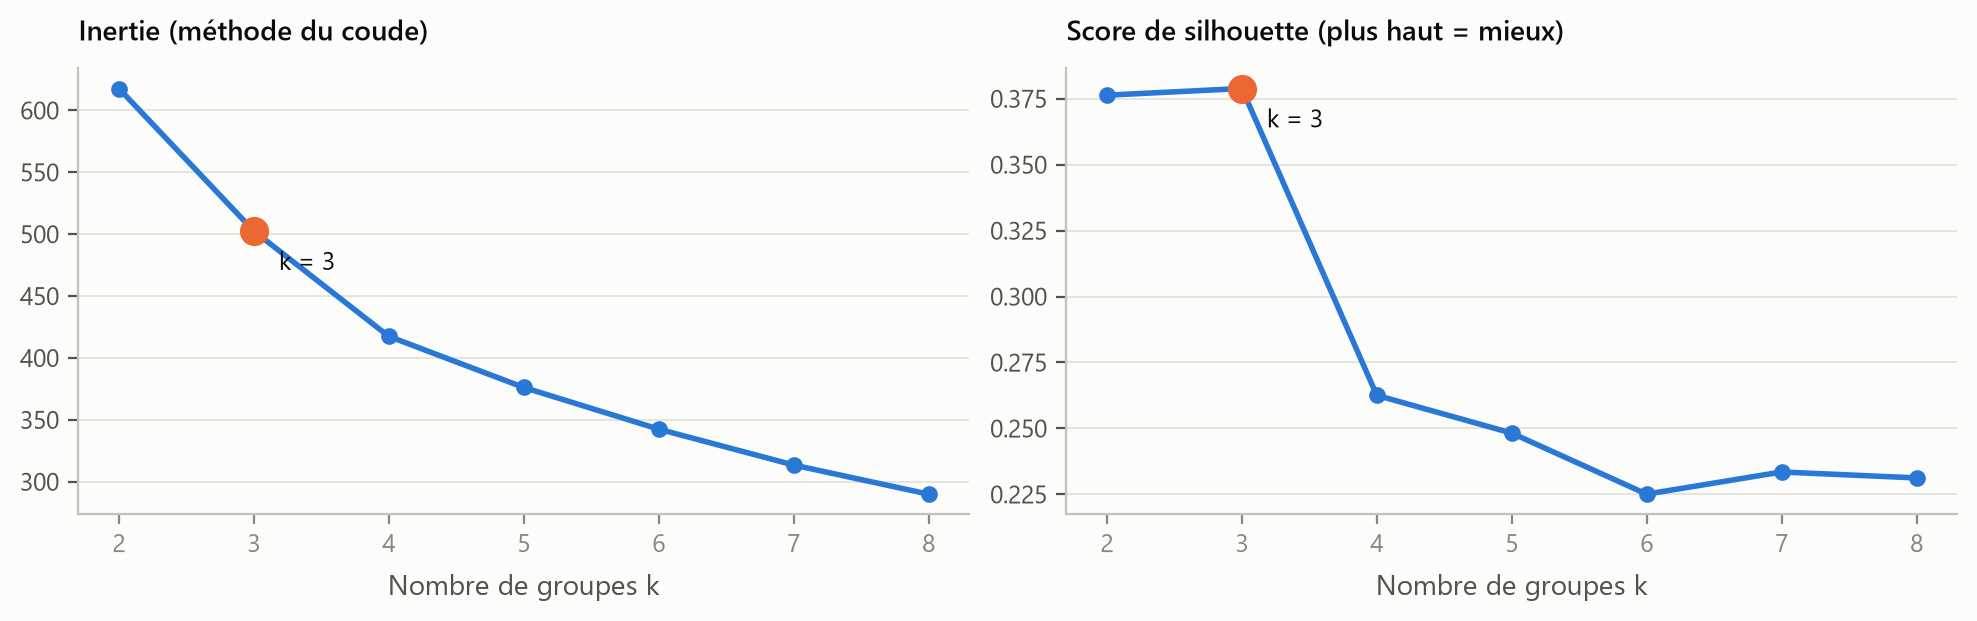

In [31]:
choix = pd.read_csv(REPORTS / "clustering_choix_k.csv")
K = 3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, colonne, titre in [(axes[0], "inertie", "Inertie (méthode du coude)"),
                           (axes[1], "silhouette", "Score de silhouette (plus haut = mieux)")]:
    ax.plot(choix.k, choix[colonne], color=BLEU, linewidth=2, marker="o", markersize=5)
    retenu = choix.set_index("k").loc[K, colonne]
    ax.scatter([K], [retenu], s=90, color=ORANGE, zorder=3)
    ax.annotate(f"k = {K}", (K, retenu), xytext=(9, -14), textcoords="offset points", fontsize=9, color=ENCRE)
    ax.set_xlabel("Nombre de groupes k")
    ax.set_xticks(choix.k)
    ax.set_title(titre, fontsize=10)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

> **Lecture.**
> - **L'inertie** mesure la dispersion des pays autour du centre de leur groupe. Elle baisse toujours quand on ajoute des groupes. On cherche le « coude », c'est-à-dire le point à partir duquel ajouter un groupe n'apporte plus grand-chose. Ici, le coude est peu marqué.
> - **Le score de silhouette** (de −1 à 1) mesure si chaque pays est plus proche de son groupe que du groupe voisin. Il est **maximal pour k = 3** (0,38), puis chute nettement à partir de k = 4 (0,26).
>
> **On retient k = 3.** Une silhouette de 0,38 indique une structure réelle, mais des groupes qui se touchent : de nombreux pays sont « entre deux » profils.

### 8.2 Profil des groupes

In [32]:
profils = pd.read_csv(REPORTS / "clustering_profils.csv", index_col="groupe")
profils["pib_par_habitant"] = (10 ** profils.log_pib).round(-2)
colonnes = ["nb_pays", "score_bonheur", "pib_par_habitant", "esperance_vie", "internet_pct",
            "urbanisation_pct", "chomage_pct", "depenses_sante_pct_pib", "depenses_education_pct_pib"]
profils[colonnes].round(1)

,nb_pays,score_bonheur,pib_par_habitant,esperance_vie,internet_pct,urbanisation_pct,chomage_pct,depenses_sante_pct_pib,depenses_education_pct_pib
groupe,,,,,,,,,
Développés et émergents,87,6.3,34800.0,78.7,89.1,75.0,5.9,7.8,4.5
En développement,44,4.8,4900.0,66.9,44.6,41.8,3.9,4.8,3.2
Chômage élevé,15,4.4,7400.0,67.2,60.1,60.0,20.0,7.7,6.0


In [33]:
pays_groupes = pd.read_csv(REPORTS / "clustering_pays.csv")
pd.crosstab(pays_groupes.region, pays_groupes.groupe)[profils.index]

groupe,Développés et émergents,En développement,Chômage élevé
region,,,
East Asia & Pacific,10,6,0
Europe & Central Asia,45,2,0
Latin America & Caribbean,17,4,0
"Middle East, North Africa, Afghanistan & Pakistan",12,2,6
North America,2,0,0
South Asia,0,4,0
Sub-Saharan Africa,1,26,9


> **Lecture.** Les 3 groupes ont des profils bien distincts :
>
> | Groupe | Pays | Profil | Bonheur (médiane) |
> |---|---|---|---|
> | **Développés et émergents** | 87 | PIB ≈ 35 000 $, espérance de vie 79 ans, 89 % sur internet | **6,4** |
> | **En développement** | 44 | PIB ≈ 4 900 $, espérance de vie 67 ans, 45 % sur internet, chômage bas (3,9 %) | 4,5 |
> | **Chômage élevé** | 15 | Revenu intermédiaire (≈ 7 400 $), chômage à **20 %**, dépenses publiques élevées en % du PIB | 4,5 |
>
> - Les « deux bosses » de l'histogramme (étape 6) correspondent au premier groupe (autour de 6) d'un côté, et aux deux autres (autour de 4–5) de l'autre.
> - **Le résultat le plus parlant** : le groupe « Chômage élevé » (Afrique australe, Maghreb et Moyen-Orient, territoires en conflit) est **50 % plus riche** (7 400 $ contre 4 900 $) et plus connecté (60 % contre 45 %) que le groupe « En développement », mais **pas plus heureux** (médiane 4,5 dans les deux cas). Sa richesse supplémentaire ne se traduit pas en bonheur, ce qui est cohérent avec le rôle du chômage mis en évidence à l'étape 7. On compare les médianes, car la moyenne de ce petit groupe (15 pays) est tirée vers le bas par l'Afghanistan (1,4).
> - Le groupe « Développés et émergents » est large. Il réunit l'Europe, l'Amérique du Nord et latine, et une partie de l'Asie. Avec k = 4, il se scinde en « très développés » et « intermédiaires », mais la silhouette indique des groupes moins nets.

### 8.3 Visualisation des groupes

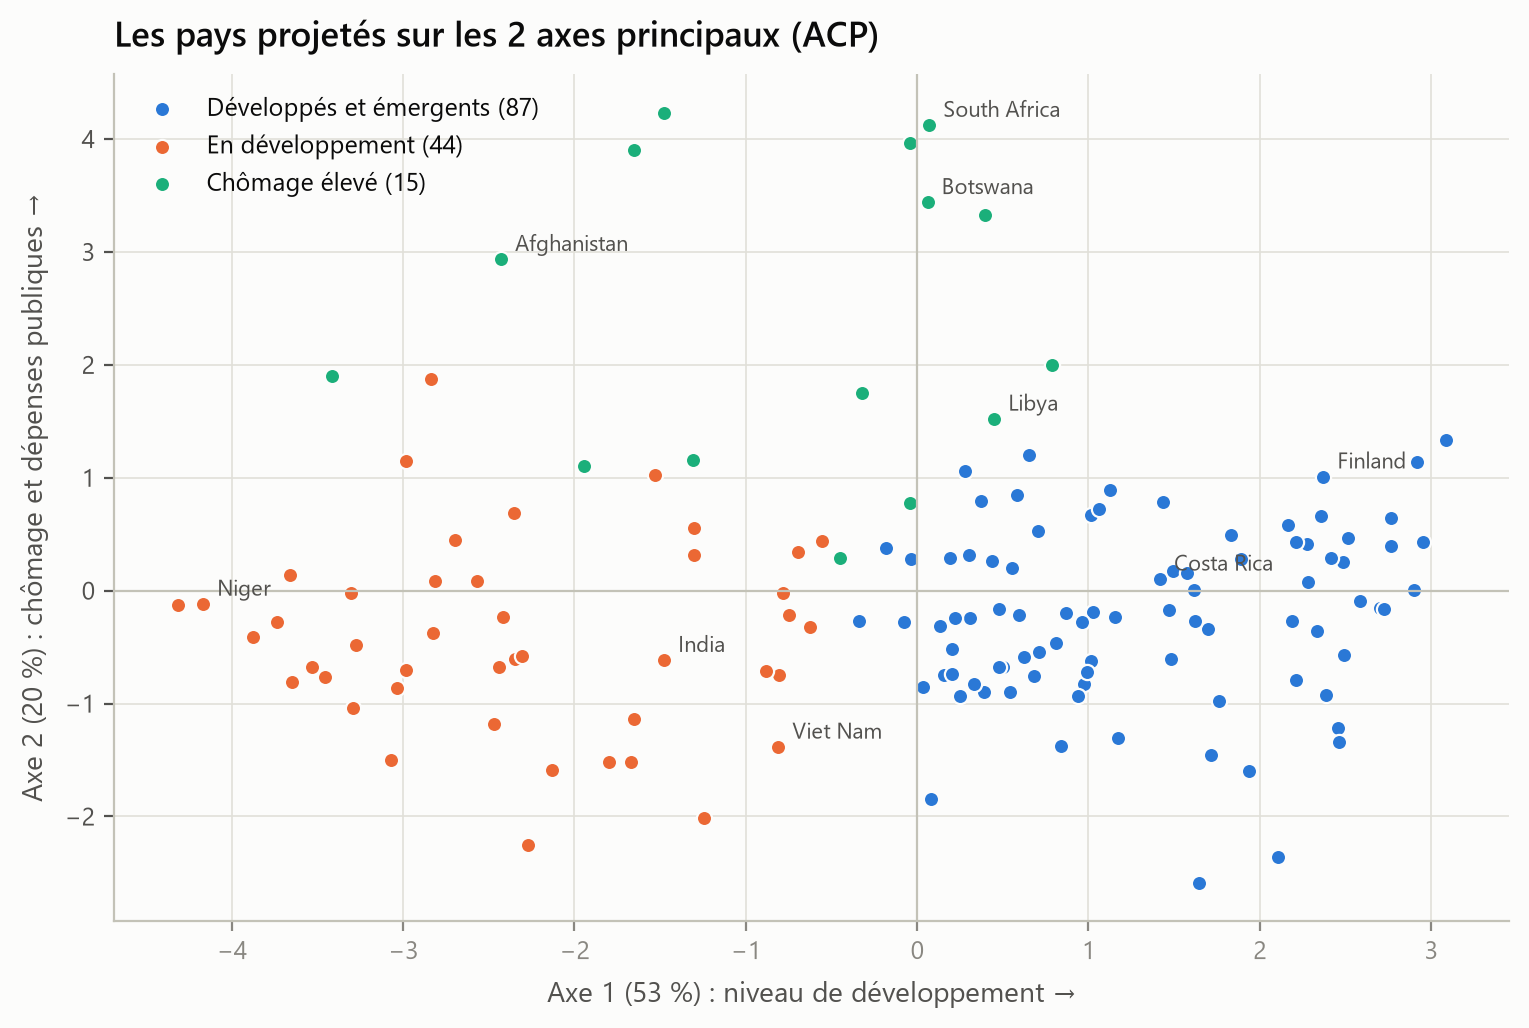

In [34]:
COULEURS_GROUPES = {"Développés et émergents": BLEU, "En développement": ORANGE, "Chômage élevé": AQUA}
exemples = ["Finland", "Costa Rica", "Viet Nam", "Niger", "South Africa", "Botswana",
            "Afghanistan", "Libya", "India"]

fig, ax = plt.subplots(figsize=(9, 5.5))
for groupe, couleur in COULEURS_GROUPES.items():
    g = pays_groupes[pays_groupes.groupe == groupe]
    ax.scatter(g.acp_1, g.acp_2, s=30, color=couleur, edgecolor=FOND, linewidth=0.8,
               label=f"{groupe} ({len(g)})")
for _, p in pays_groupes[pays_groupes.pays.isin(exemples)].iterrows():
    ax.annotate(p.pays, (p.acp_1, p.acp_2), xytext=(5, 3), textcoords="offset points", fontsize=8, color=ENCRE_2)
ax.axhline(0, color=GRIS, linewidth=0.8)
ax.axvline(0, color=GRIS, linewidth=0.8)
ax.set_xlabel("Axe 1 (53 %) : niveau de développement →")
ax.set_ylabel("Axe 2 (20 %) : chômage et dépenses publiques →")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_title("Les pays projetés sur les 2 axes principaux (ACP)")
plt.show()

> **Lecture.** L'**ACP** (analyse en composantes principales) résume les 7 indicateurs en 2 axes, qui conservent 73 % de l'information. On peut ainsi dessiner les pays sur un plan.
> - **L'axe horizontal** combine le PIB, l'espérance de vie, internet et l'urbanisation : c'est le **niveau de développement**.
> - **L'axe vertical** est porté par le chômage et les dépenses publiques en % du PIB.
>
> Les groupes « Développés et émergents » et « En développement » s'opposent sur l'axe horizontal. Le groupe « Chômage élevé » se détache vers le haut. Les frontières entre groupes sont floues, ce qui est cohérent avec la silhouette modérée.

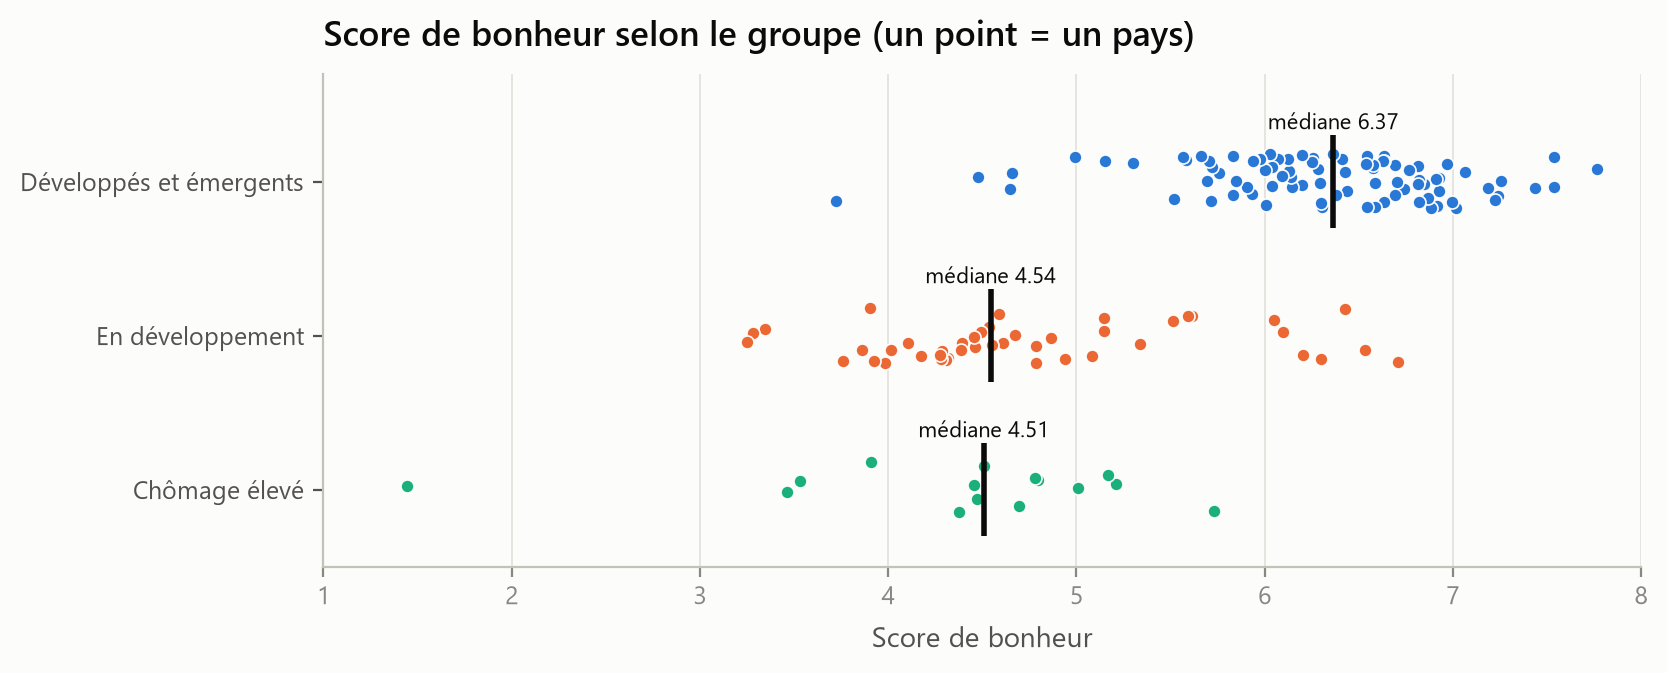

In [35]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, (groupe, couleur) in enumerate(reversed(list(COULEURS_GROUPES.items()))):
    g = pays_groupes[pays_groupes.groupe == groupe]
    ax.scatter(g.score_bonheur, i + alea.uniform(-0.18, 0.18, len(g)), s=22, color=couleur,
               edgecolor=FOND, linewidth=0.6)
    mediane = g.score_bonheur.median()
    ax.vlines(mediane, i - 0.3, i + 0.3, color=ENCRE, linewidth=2)
    ax.text(mediane, i + 0.34, f"médiane {mediane:.2f}", ha="center", fontsize=8, color=ENCRE)
ax.set_yticks(range(3), list(reversed(list(COULEURS_GROUPES))))
ax.set_ylim(-0.5, 2.7)
ax.set_xlim(1, 8)
ax.set_xlabel("Score de bonheur")
ax.grid(axis="y", visible=False)
ax.set_title("Score de bonheur selon le groupe (un point = un pays)")
plt.show()

> **Lecture.** Les groupes, formés **sans connaître le bonheur**, ont pourtant des scores très différents : une médiane de 6,4 pour les pays développés et émergents, contre 4,5 pour les deux autres groupes. Les profils socio-économiques sont donc bien liés au bonheur. Il existe toutefois des recouvrements : certains pays « En développement » (Belize, Nicaragua, Viet Nam…) sont aussi heureux que la moyenne des pays développés.

### 8.4 Synthèse du clustering

> **À retenir**
>
> - **Trois profils de pays** : développés et émergents (87), en développement (44), à chômage élevé (15).
> - **Le profil « chômage élevé » n'est pas plus heureux que le profil « en développement »**, alors qu'il est 50 % plus riche. Cela confirme le rôle du chômage.
> - **Groupes utiles mais aux frontières floues** (silhouette 0,38) : ils servent à orienter des actions par profil de pays, pas à classer chaque pays de façon certaine.

---

<a id="s9"></a>

## 9. Analyse complémentaire : la gouvernance

**Hypothèse testée** : une partie des écarts que le modèle final de l'étape 7 n'explique pas (environ 35 %) viendrait de la qualité des institutions. Si c'est le cas, ajouter des indicateurs de gouvernance à ce modèle devrait **augmenter le R²** et **mieux prédire le Liban et l'Afghanistan**.

**Données** : 3 des *Worldwide Governance Indicators* de la World Bank (plus la valeur est haute, meilleure est la gouvernance) :
- **contrôle de la corruption** (`CC.EST`) ;
- **stabilité politique et absence de violence** (`PV.EST`) ;
- **État de droit** (`RL.EST`).

⚠️ **La source a changé.** Ces indicateurs sont désormais **archivés** par l'API World Bank : seul le téléchargement groupé fonctionne, et les données s'arrêtent en **2023**. Cette année fait partie de la période d'enquête du rapport 2026 (2023–2025), et la gouvernance évolue lentement : on utilise donc la valeur 2023.

⚠️ **Anomalie du fichier archivé** : les valeurs ne sont pas sur l'échelle officielle (−2,5 à +2,5), et cette échelle change d'une année à l'autre (en 2023, environ la moitié de 2020, pour tous les pays). Le **classement** des pays reste cohérent : Danemark et Finlande en tête, Soudan du Sud et Syrie en bas, corrélation de rang de 0,98 entre 2020 et 2023. On n'utilise donc **qu'une seule année**. Les valeurs restent comparables entre pays, et les modèles ne sont pas affectés : la régression standardise les variables, et les arbres ne dépendent que de l'ordre des valeurs.

**Méthode** : on refait la validation croisée (5 plis × 10 répétitions) **avec exactement les mêmes plis**, avec et sans gouvernance. Seules les variables changent. Script : `src/07_gouvernance.py`.

In [36]:
gouv = pd.read_csv(PROCESSED / "worldpulse_2026_gouvernance.csv")
gouv["log_pib"] = np.log10(gouv.pib_par_habitant_ppa)
WGI = ["controle_corruption", "stabilite_politique", "etat_de_droit"]
print(gouv.shape, "— pays sans donnée de gouvernance :", int(gouv[WGI].isna().any(axis=1).sum()))
(gouv[["score_bonheur", "log_pib"] + WGI].corr().loc[WGI].rename(index=LIBELLES)
     .rename(columns={"score_bonheur": "Bonheur", "log_pib": "log PIB"}).round(2))

(146, 17) — pays sans donnée de gouvernance : 0


,Bonheur,log PIB,controle_corruption,stabilite_politique,etat_de_droit
Contrôle de la corruption,0.63,0.75,1.00,0.72,0.96
Stabilité politique,0.61,0.67,0.72,1.00,0.78
État de droit,0.64,0.80,0.96,0.78,1.00


> **Lecture.**
> - Les 3 indicateurs sont **corrélés au bonheur** (0,61 à 0,64), mais **moins que le PIB** (0,79).
> - Ils sont surtout **très liés au PIB** (0,67 à 0,80) et entre eux : le contrôle de la corruption et l'État de droit sont corrélés à 0,96, c'est presque la même mesure. Il y a donc un risque qu'ils n'apportent **aucune information nouvelle**.

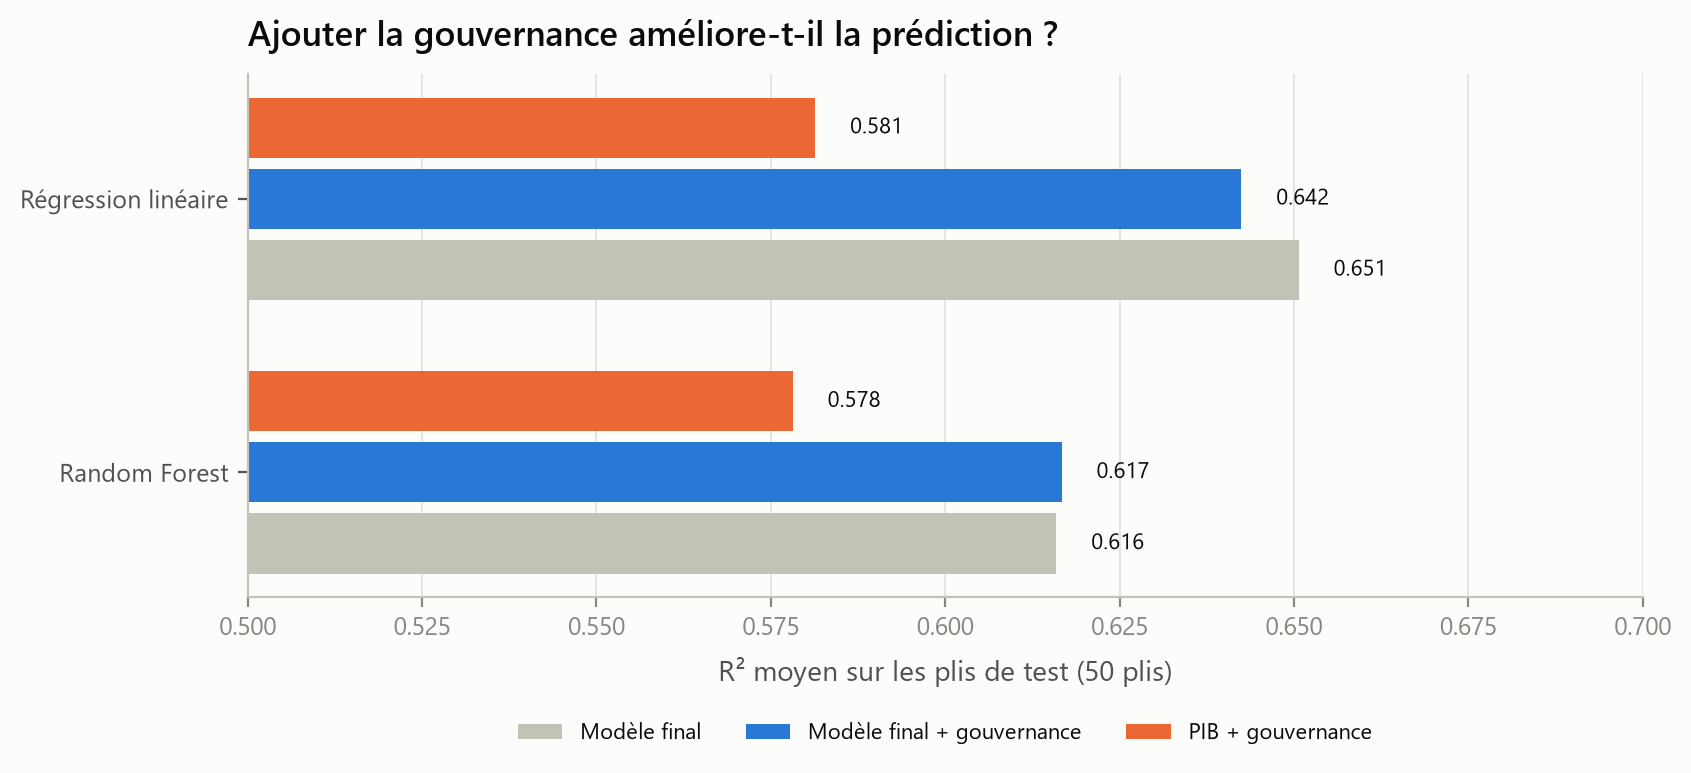

,gain moyen de R²,plis où ça aide (sur 50)
modele,,
Random Forest,1.00e-03,29
Régression linéaire,-8.00e-03,24


In [37]:
scores_g = pd.read_csv(REPORTS / "gouvernance_scores_cv.csv").query("metrique == 'R2'")
JEUX = ["Modèle final", "Modèle final + gouvernance", "PIB + gouvernance"]
COULEURS_JEUX = dict(zip(JEUX, [GRIS, BLEU, ORANGE]))
modeles_g = ["Régression linéaire", "Random Forest"]

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, modele in enumerate(modeles_g):
    for j, jeu in enumerate(JEUX):
        r2 = scores_g.query("modele == @modele and variables == @jeu")["test"]
        y = i + (1 - j) * 0.26
        ax.barh(y, r2.mean(), height=0.22, color=COULEURS_JEUX[jeu], label=jeu if i == 0 else None)
        ax.text(r2.mean() + 0.005, y, f"{r2.mean():.3f}", va="center", fontsize=8, color=ENCRE)
ax.set_yticks(range(len(modeles_g)), modeles_g)
ax.invert_yaxis()
ax.set_xlim(0.5, 0.7)
ax.set_xlabel("R² moyen sur les plis de test (50 plis)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.set_title("Ajouter la gouvernance améliore-t-il la prédiction ?")
plt.show()

gain = (scores_g.pivot_table(index=["modele", "pli"], columns="variables", values="test")
        .eval("gain = `Modèle final + gouvernance` - `Modèle final`").groupby("modele")["gain"])
pd.DataFrame({"gain moyen de R²": gain.mean().round(3), "plis où ça aide (sur 50)": gain.apply(lambda g: (g > 0).sum())})

> **Lecture.** L'axe horizontal commence à 0,5 pour rendre les écarts visibles : ils sont **faibles**.
> Le « modèle final » est la régression à 5 variables retenue à l'étape 7.
> - **Régression linéaire** : la gouvernance **n'améliore pas** le modèle. Le R² passe de 0,651 à 0,642, et la gouvernance n'aide que dans 24 plis sur 50, soit au hasard. Elle ajoute 3 variables redondantes, ce qui rend le modèle un peu plus instable.
> - **Random Forest** : aucun gain (0,616 → 0,617, dans 29 plis sur 50).
> - **PIB + gouvernance** (0,58) fait à peine mieux que le PIB seul (0,58, étape 7) : la gouvernance n'apporte presque rien **une fois la richesse connue**.

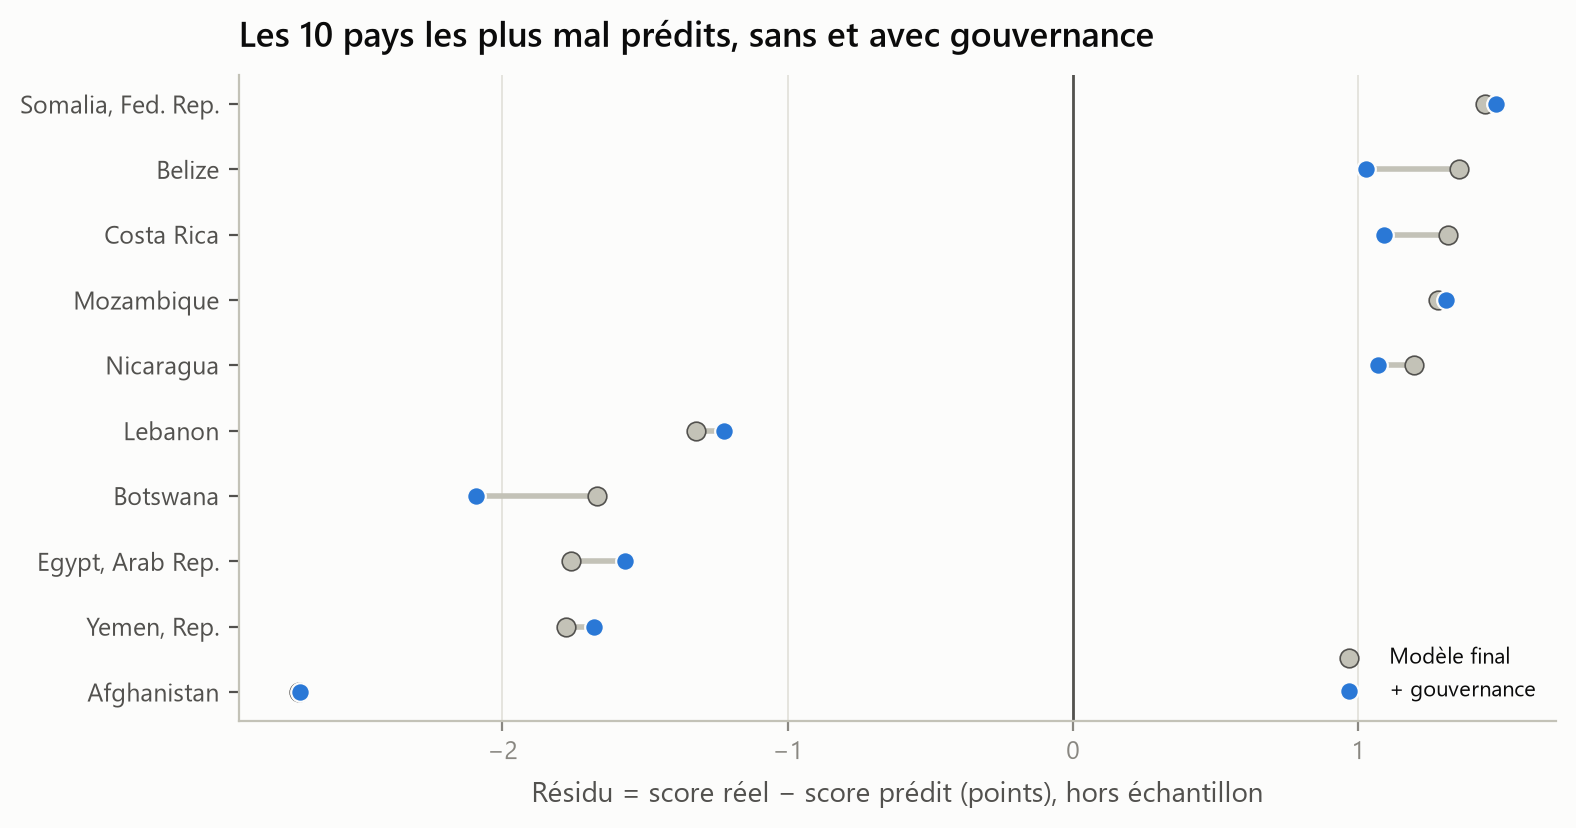

In [38]:
preds_g = pd.read_csv(REPORTS / "gouvernance_predictions.csv")
AVANT, APRES = "residu_Modèle final", "residu_Modèle final + gouvernance"
suivis = preds_g.reindex(preds_g[AVANT].abs().sort_values(ascending=False).index).head(10)
suivis = suivis.sort_values(AVANT)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(suivis))
ax.hlines(y, suivis[AVANT], suivis[APRES], color=GRIS, linewidth=2)
ax.scatter(suivis[AVANT], y, s=45, color=GRIS, edgecolor=ENCRE_2, linewidth=0.6, zorder=3, label="Modèle final")
ax.scatter(suivis[APRES], y, s=45, color=BLEU, edgecolor=FOND, linewidth=0.8, zorder=3, label="+ gouvernance")
ax.set_yticks(y, suivis.pays)
ax.axvline(0, color=ENCRE_2, linewidth=1)
ax.set_xlabel("Résidu = score réel − score prédit (points), hors échantillon")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Les 10 pays les plus mal prédits, sans et avec gouvernance")
plt.show()

> **Lecture.** Chaque ligne relie l'erreur du modèle sans gouvernance (gris) à celle du modèle avec gouvernance (bleu). Plus un point est proche de 0, meilleure est la prédiction. Les prédictions sont moyennées sur 10 découpages de validation croisée.
> - **Liban** : légère amélioration (−1,32 → −1,22). La gouvernance capte une petite partie de la crise.
> - **Afghanistan** : **aucune amélioration** (−2,71 → −2,71). Sa mauvaise gouvernance ne suffit pas à expliquer un score aussi bas (1,45).
> - **Botswana** : la prédiction **se dégrade** (−1,67 → −2,09). C'est l'un des pays les mieux gouvernés d'Afrique, mais il est peu heureux. La gouvernance pousse sa prédiction vers le haut, à tort.

### 9.1 Synthèse

> **À retenir**
>
> - **L'hypothèse est en grande partie rejetée** : la gouvernance n'augmente le R² ni de la régression linéaire, ni du Random Forest.
> - **Explication** : dans ces données, la gouvernance est très liée à la richesse (corrélation jusqu'à 0,80). Elle mesure en grande partie la même chose que le « bloc développement ».
> - **L'Afghanistan reste inexpliqué.** *Hypothèse* : son score reflète des facteurs que ces indicateurs nationaux ne mesurent pas, comme la situation des femmes ou la peur au quotidien.
> - **Limite** : les indicateurs datent de 2023 (source archivée), et on ne teste que 3 des 6 indicateurs WGI.
>
> C'est un **résultat négatif utile** : pour l'ONG, la gouvernance n'est pas un levier distinct de la richesse dans ces données.

---

<a id="s10"></a>

## 10. Analyse complémentaire : le paradoxe d'Easterlin

**Le paradoxe** (Richard Easterlin, 1974) : **entre pays**, les plus riches sont plus heureux, mais **dans le temps**, quand un pays s'enrichit, son bonheur augmenterait à peine.

**Question** : dans nos données, quand le PIB d'un pays augmente, son score augmente-t-il autant que le prévoit la comparaison entre pays (+1,8 point pour un PIB multiplié par 10, étape 6) ?

**Méthode** (script `src/08_easterlin.py`), en mesurant toujours la pente en points de bonheur pour un PIB multiplié par 10 :
1. **Entre pays** : la pente de l'étape 6, mesurée pour le rapport 2016 et pour le rapport 2026.
2. **Dans le temps** : pour chacun des 139 pays présents en 2016 et en 2026, on relie la variation de son PIB à la variation de son score.
3. **Panel à effets fixes** : on utilise les 8 rapports, en ajoutant un terme par pays, qui retire les différences permanentes entre pays, et un terme par rapport, qui retire les chocs communs comme le Covid. Il ne reste que les variations propres à chaque pays.

Intervalle de confiance à 95 % par **bootstrap** : on tire 1 000 fois des pays au hasard, avec remise, et on recalcule la pente à chaque fois.

In [39]:
variations = pd.read_csv(REPORTS / "easterlin_variations.csv")
pentes = pd.read_csv(REPORTS / "easterlin_pentes.csv")
print(f"{len(variations)} pays — croissance médiane du PIB/hab. : {variations.croissance_pib_pct.median():+.0f} %, "
      f"variation médiane du score : {variations.delta_score.median():+.2f}")

139 pays — croissance médiane du PIB/hab. : +16 %, variation médiane du score : +0.22


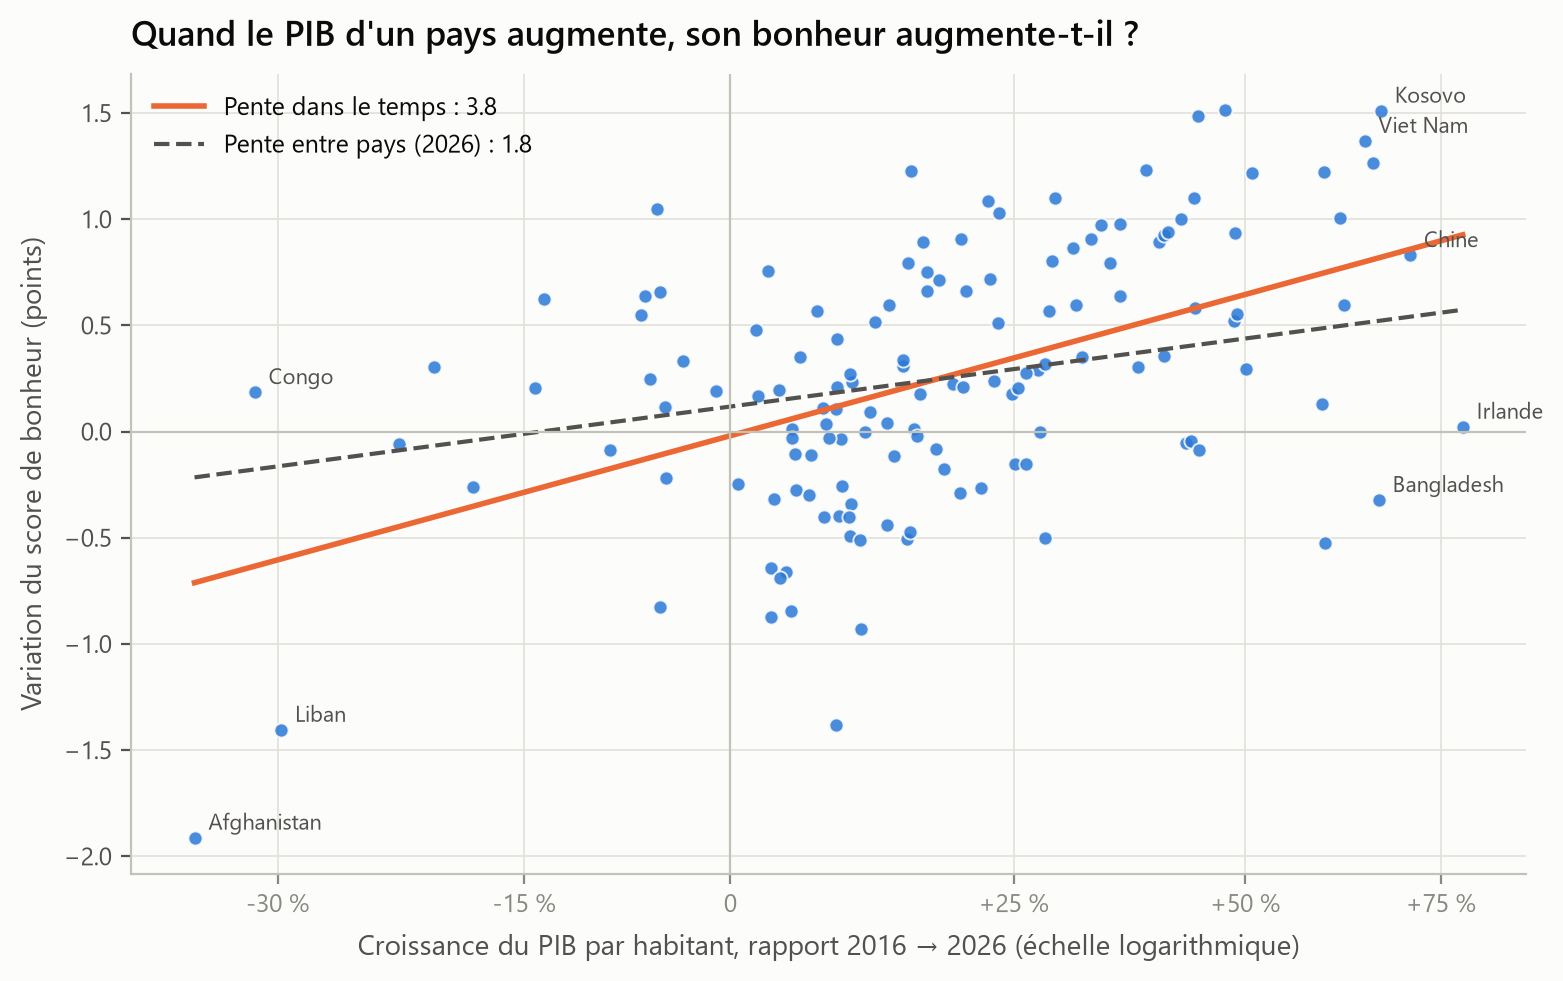

In [40]:
pente_entre = pentes.set_index("approche").loc["Entre pays (2026)", "pente"]
b, a = np.polyfit(variations.delta_log_pib, variations.delta_score, 1)
x = np.linspace(variations.delta_log_pib.min(), variations.delta_log_pib.max(), 50)
mx, my = variations.delta_log_pib.mean(), variations.delta_score.mean()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(variations.delta_log_pib, variations.delta_score, s=26, color=BLEU, edgecolor=FOND, linewidth=0.7, alpha=0.85)
ax.plot(x, a + b * x, color=ORANGE, linewidth=2, label=f"Pente dans le temps : {b:.1f}")
ax.plot(x, my + pente_entre * (x - mx), color=ENCRE_2, linewidth=1.5, linestyle="--",
        label=f"Pente entre pays (2026) : {pente_entre:.1f}")
noms = {"Afghanistan": "Afghanistan", "Lebanon": "Liban", "Viet Nam": "Viet Nam", "Kosovo": "Kosovo",
        "China": "Chine", "Ireland": "Irlande", "Bangladesh": "Bangladesh", "Congo, Rep.": "Congo"}
for _, p in variations[variations.pays.isin(noms)].iterrows():
    ax.annotate(noms[p.pays], (p.delta_log_pib, p.delta_score), xytext=(5, 3), textcoords="offset points",
                fontsize=8, color=ENCRE_2)
ax.axhline(0, color=GRIS, linewidth=0.8)
ax.axvline(0, color=GRIS, linewidth=0.8)
graduations = [-30, -15, 0, 25, 50, 75]
ax.set_xticks(np.log10(1 + np.array(graduations) / 100), [f"{g:+d} %" if g else "0" for g in graduations])
ax.set_xlabel("Croissance du PIB par habitant, rapport 2016 → 2026 (échelle logarithmique)")
ax.set_ylabel("Variation du score de bonheur (points)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Quand le PIB d'un pays augmente, son bonheur augmente-t-il ?")
plt.show()

> **Lecture.** Chaque point est un pays : à l'horizontale, l'évolution de son PIB par habitant, à la verticale, celle de son score de bonheur.
> - **Les deux évolutions vont dans le même sens** (corrélation de 0,50). Les pays à forte croissance (Viet Nam, Kosovo, Chine) ont gagné en bonheur. Ceux dont le PIB s'est effondré (Afghanistan, Liban) en ont perdu beaucoup.
> - **La pente dans le temps (orange) est plus raide que la pente entre pays (pointillés)**, alors que le paradoxe d'Easterlin prédit l'inverse.
> - **Exceptions instructives** :
>   - l'**Irlande** (+78 %) ne gagne rien. Son PIB est gonflé par les bénéfices des multinationales installées dans le pays, sans que le revenu des habitants augmente autant ;
>   - le **Bangladesh** (+67 %) perd du bonheur ;
>   - le **Congo** (−31 %) n'en perd pas.

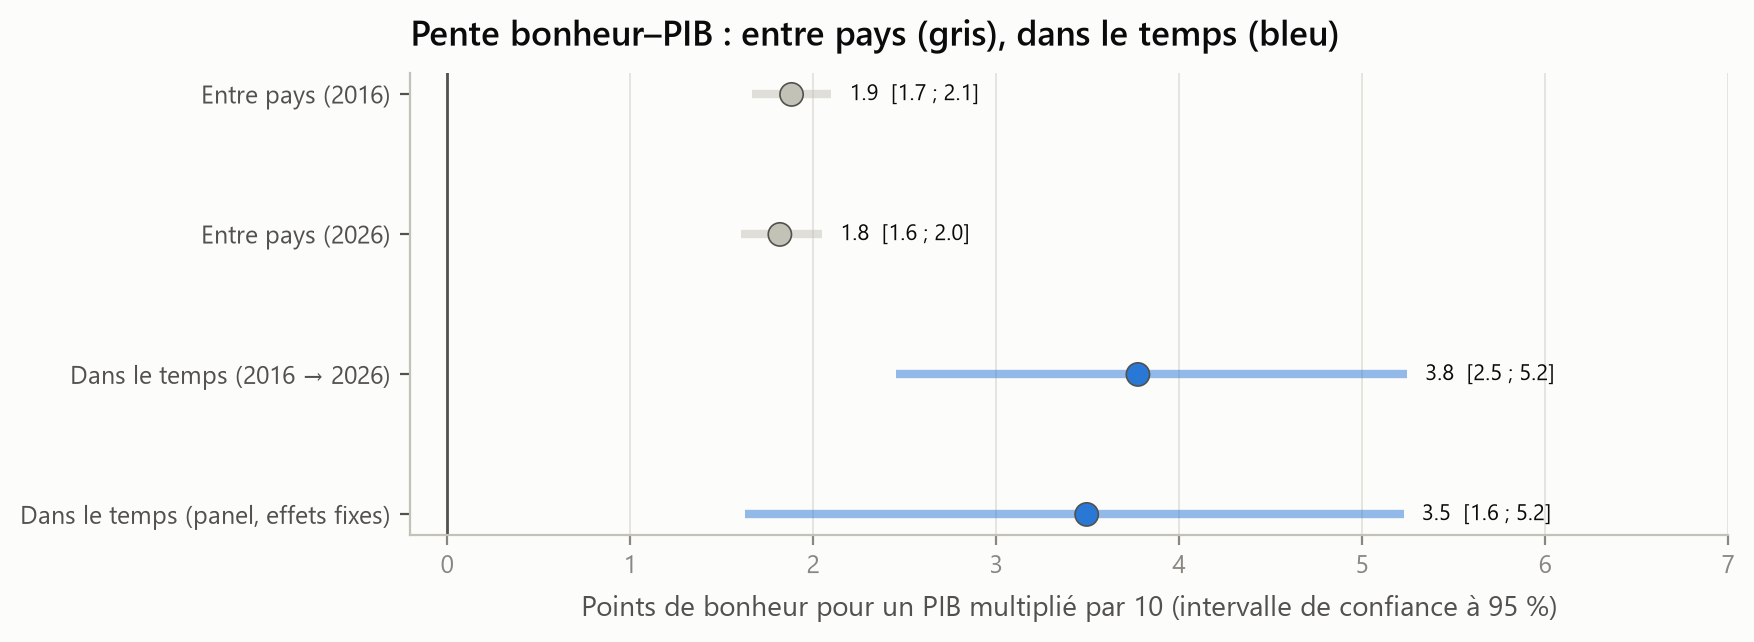

,Pente,n_pays
Robustesse : PIB en hausse seulement,5.04,120
Robustesse : Theil-Sen (peu sensible aux extrêmes),4.11,139
Robustesse : retrait d'un pays (minimum),3.41,138
Robustesse : retrait d'un pays (maximum),4.00,138


In [41]:
principales = pentes[~pentes.approche.str.startswith("Robustesse")].iloc[::-1].reset_index(drop=True)
couleurs = [BLEU if a.startswith("Dans") else GRIS for a in principales.approche]

fig, ax = plt.subplots(figsize=(8.5, 3))
ax.hlines(principales.index, principales.ic_bas, principales.ic_haut, color=couleurs, linewidth=3, alpha=0.5)
ax.scatter(principales.pente, principales.index, s=70, color=couleurs, edgecolor=ENCRE_2, linewidth=0.6, zorder=3)
for i, r in principales.iterrows():
    ax.text(r.ic_haut + 0.1, i, f"{r.pente:.1f}  [{r.ic_bas:.1f} ; {r.ic_haut:.1f}]", va="center", fontsize=8, color=ENCRE)
ax.set_yticks(principales.index, principales.approche)
ax.axvline(0, color=ENCRE_2, linewidth=1)
ax.set_xlim(-0.2, 7)
ax.set_xlabel("Points de bonheur pour un PIB multiplié par 10 (intervalle de confiance à 95 %)")
ax.grid(axis="y", visible=False)
ax.set_title("Pente bonheur–PIB : entre pays (gris), dans le temps (bleu)")
plt.show()
tableau(pentes[pentes.approche.str.startswith("Robustesse")].drop(columns=["ic_bas", "ic_haut"])
        .set_index("approche").rename_axis(None))

> **Lecture.**
> - **Entre pays**, la pente est stable : 1,9 en 2016, 1,8 en 2026.
> - **Dans le temps**, elle est d'environ **3,5 à 3,8**, et nettement **différente de 0** : l'intervalle de confiance du panel commence à 1,6. Les intervalles sont larges, car en 10 ans les PIB bougent peu (+16 % en médiane).
> - **Le résultat est robuste** :
>   - en retirant n'importe quel pays, la pente reste entre 3,4 et 4,0 ;
>   - avec la méthode de Theil-Sen, peu sensible aux valeurs extrêmes, elle est de 4,1 ;
>   - en ne gardant que les pays dont le PIB a augmenté, elle est de 5,0. Le résultat ne dépend donc pas seulement des pays en crise.
>
> **Pourquoi ce résultat contredit-il le paradoxe ?** Ce sont des *hypothèses*, que nos données ne permettent pas de trancher :
> - **Horizon court.** Easterlin et ses coauteurs (*PNAS*, 2010, « The happiness–income paradox revisited ») soutiennent qu'à court terme le bonheur suit la conjoncture, et que le paradoxe ne s'observe que sur le long terme. Or 10 ans est à la limite entre les deux.
> - **Facteurs qui évoluent ensemble.** Une croissance forte s'accompagne souvent d'autres améliorations, comme la fin d'une crise ou de meilleurs services. À l'inverse, un effondrement du PIB (Liban, Afghanistan) s'accompagne souvent d'une crise politique. Le PIB capte alors l'effet de ces autres changements.
> - **Rattrapage.** Les pays à plus forte croissance (Kosovo, Viet Nam, Chine, Géorgie) sont des pays en rattrapage rapide, partis d'un niveau de bonheur modeste.

### 10.1 Synthèse

> **À retenir**
>
> - **Le paradoxe d'Easterlin ne se vérifie pas sur 2016–2026** : quand un pays s'enrichit, son bonheur augmente, et même plus vite que ne le prévoit la comparaison entre pays.
> - **Limites** : 10 ans seulement, des intervalles de confiance larges, et une association qui n'est pas une causalité. La croissance accompagne d'autres changements qu'on ne mesure pas ici.
> - **Pour l'ONG** : en moyenne, la croissance d'un pays va de pair avec une hausse du bien-être. Les deux plus fortes chutes de bonheur (Afghanistan, Liban) accompagnent un effondrement du PIB, mais le Congo (−31 % de PIB) n'a rien perdu : le PIB seul ne suffit pas à repérer les crises (voir section 11).

---

<a id="s11"></a>

## 11. Conclusion et recommandations pour l'ONG

### 11.1 Réponse à la question

**Qu'est-ce qui rend un pays heureux ?** Dans nos données, deux facteurs dominent :
1. **le niveau de développement** (PIB par habitant, accès à internet) ;
2. **l'emploi** : le chômage est le deuxième facteur, avec l'effet le plus précisément estimé.

Les dépenses publiques de santé et d'éducation ont un effet positif, mais faible. Ces 5 variables expliquent **environ 63 % des écarts de bonheur sur des pays que le modèle n'a jamais vus**. Le tiers restant vient de facteurs absents de nos données.

Le graphique ci-dessous traduit les coefficients du modèle final en **ordres de grandeur comparables** : l'effet d'un changement réaliste de chaque variable, les autres restant égales.

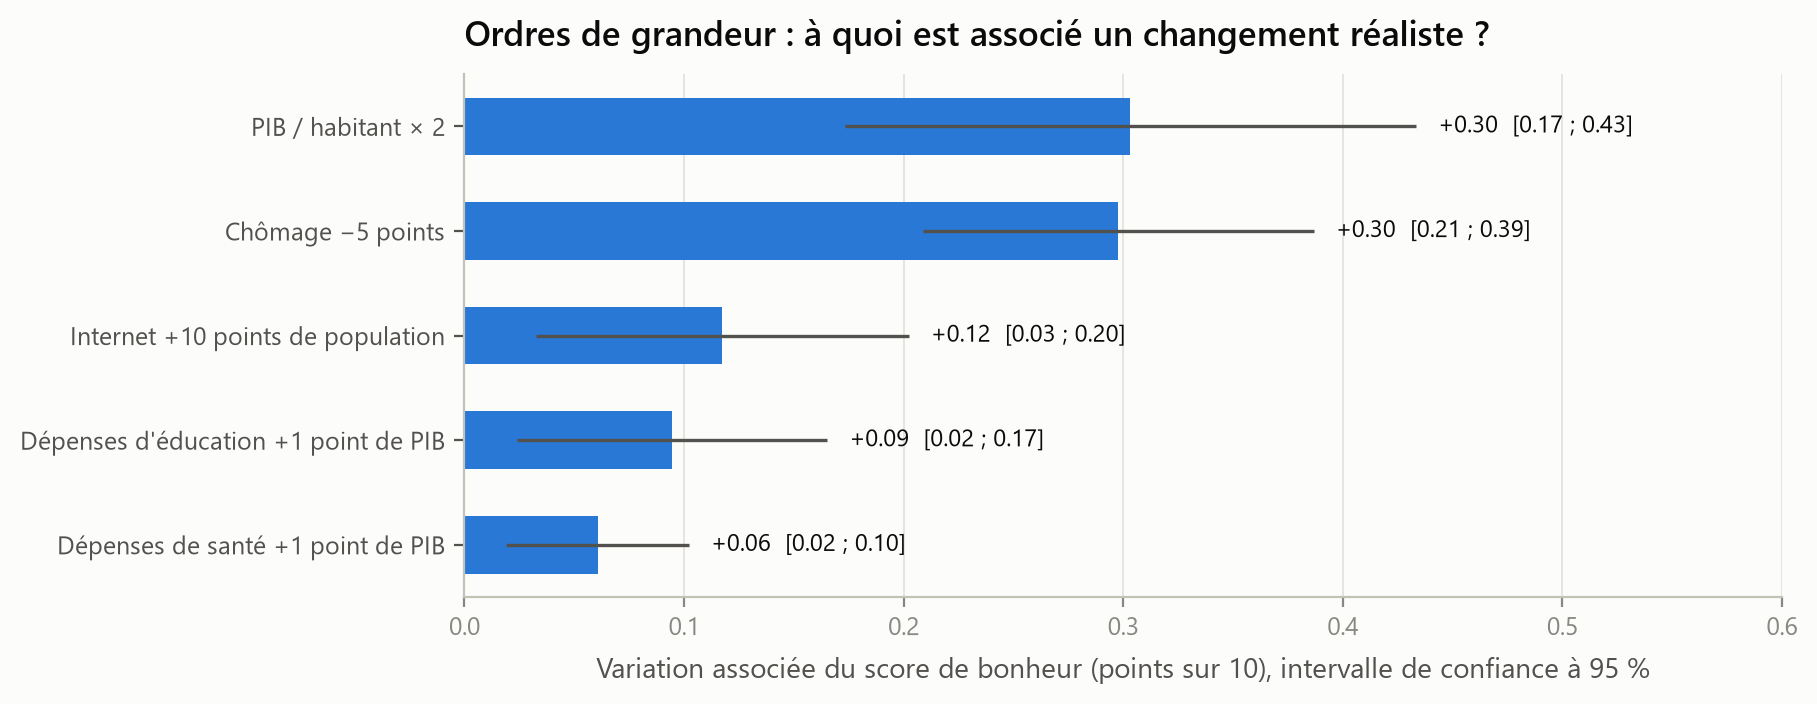

In [42]:
# Effet d'un changement réaliste de chaque variable, d'après le modèle final (section 7.9)
SCENARIOS = {  # variable : (changement, libellé)
    "log_pib": (np.log10(2), "PIB / habitant × 2"),
    "chomage_pct": (-5, "Chômage −5 points"),
    "internet_pct": (10, "Internet +10 points de population"),
    "depenses_education_pct_pib": (1, "Dépenses d'éducation +1 point de PIB"),
    "depenses_sante_pct_pib": (1, "Dépenses de santé +1 point de PIB"),
}
coef = final.set_index("variable")
effets = pd.DataFrame([
    {"scenario": libelle,
     "effet": coef.loc[v, "coefficient"] * d,
     "ic_bas": min(coef.loc[v, "ic_bas"] * d, coef.loc[v, "ic_haut"] * d),
     "ic_haut": max(coef.loc[v, "ic_bas"] * d, coef.loc[v, "ic_haut"] * d)}
    for v, (d, libelle) in SCENARIOS.items()]).iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(effets.index, effets.effet, height=0.55, color=BLEU)
ax.hlines(effets.index, effets.ic_bas, effets.ic_haut, color=ENCRE_2, linewidth=1.2)
for i, r in effets.iterrows():
    ax.text(r.ic_haut + 0.01, i, f"+{r.effet:.2f}  [{r.ic_bas:.2f} ; {r.ic_haut:.2f}]",
            va="center", fontsize=8.5, color=ENCRE)
ax.set_yticks(effets.index, effets.scenario)
ax.set_xlim(0, 0.6)
ax.set_xlabel("Variation associée du score de bonheur (points sur 10), intervalle de confiance à 95 %")
ax.grid(axis="y", visible=False)
ax.set_title("Ordres de grandeur : à quoi est associé un changement réaliste ?")
plt.show()

> **Lecture.** Un chômage plus bas de 5 points est associé au **même gain de bonheur qu'un PIB doublé** (+0,30 point). Or doubler le PIB d'un pays prend en général des décennies. Les trois autres leviers ont des effets 3 à 5 fois plus petits, et des intervalles de confiance plus larges.
>
> ⚠️ Ce sont des **associations entre pays**, à autres variables égales, pas l'effet garanti d'une politique : le modèle ne dit pas ce qui se passerait si l'on changeait une variable dans un pays donné.

### 11.2 Recommandations

**1. Faire de l'emploi une priorité, en particulier dans les pays à chômage élevé.**
- *Ce qui l'appuie* : 5 points de chômage en moins vont de pair avec +0,30 point de bonheur [0,21 ; 0,39], l'effet le plus précis du modèle. Le groupe « Chômage élevé » (15 pays, surtout en Afrique australe, au Maghreb et au Moyen-Orient : Afrique du Sud, Botswana, Namibie, Tunisie, Irak…) est 50 % plus riche que le groupe « En développement », mais **pas plus heureux** (médiane 4,5 dans les deux cas).
- *Limites* : le lien peut aller dans les deux sens, car des personnes malheureuses peuvent aussi moins trouver d'emploi. Le chômage mesuré par l'OIT ignore l'emploi informel, très répandu dans les pays pauvres.

**2. Soutenir le développement économique, et suivre le bonheur lui-même dans le temps.**
- *Ce qui l'appuie* : un PIB doublé va de pair avec +0,30 point [0,17 ; 0,43]. Dans le temps aussi, le bonheur suit la croissance (section 10) : les 49 pays dont le PIB a augmenté de plus de 25 % entre 2016 et 2026 ont gagné en médiane +0,6 point.
- *Mais le PIB n'est pas une alarme fiable* : le Congo a perdu 31 % de PIB sans perdre de bonheur, et la Sierra Leone, le Malawi et le Zimbabwe ont perdu de 0,85 à 1,4 point malgré une croissance positive. **L'ONG devrait suivre directement le score de bonheur publié chaque année** (World Happiness Report), en plus des indicateurs économiques.
- *Limites* : le PIB représente tout un « bloc développement » (santé, infrastructures…) très corrélé (section 7.2). L'analyse dans le temps porte sur 10 ans seulement.

**3. Considérer internet et les services publics comme des leviers complémentaires, et non prioritaires.**
- *Ce qui l'appuie* : +10 points d'accès à internet vont de pair avec +0,12 point [0,03 ; 0,20] ; +1 point de PIB consacré à l'éducation avec +0,09 [0,02 ; 0,17] ; à la santé avec +0,06 [0,02 ; 0,10]. Ces effets sont significatifs, mais modestes.
- *Limites* : internet est aussi un marqueur du développement (VIF 6,1), donc son effet propre est incertain. Les dépenses d'éducation sont la donnée la plus fragile (valeur ancienne pour 54 pays, absente pour 11). Enfin, dépenser plus ne garantit pas de meilleurs services.

**4. Adapter les actions au profil du pays, et compléter par des données de terrain.**

| Profil (section 8) | Pays | Ce qui le distingue | Piste prioritaire |
|---|---|---|---|
| Développés et émergents | 87 | Développement élevé, bonheur élevé (médiane 6,4) | Hors de nos variables : liens sociaux, santé mentale (*hypothèse*) |
| En développement | 44 | PIB et internet faibles, chômage bas | Développement économique et accès aux services |
| Chômage élevé | 15 | Revenu intermédiaire, chômage à 20 % | Emploi |

- *Ce qui l'appuie* : environ un tiers des écarts restent inexpliqués, et la gouvernance n'apporte rien de plus (section 9). Des pays d'Amérique latine sont bien plus heureux que prévu ; *hypothèse* du World Happiness Report : des liens sociaux forts (WHR 2018, chapitre 6). D'autres, comme l'Afghanistan, sont bien moins heureux que prévu.
- *Limites* : les frontières entre profils sont floues (silhouette 0,38). Le profil sert à orienter, pas à classer chaque pays de façon certaine.

### 11.3 Limites générales

- **Associations, pas causes** : aucune de ces analyses ne prouve qu'agir sur une variable *rend* un pays plus heureux.
- **Peu de données** : 146 pays seulement ; les estimations ont des intervalles de confiance larges.
- **Moyennes nationales** : le score ne dit rien des inégalités de bonheur à l'intérieur d'un pays.
- **Données récentes incomplètes** : la World Bank publie avec 1 à 3 ans de retard, et les indicateurs de gouvernance archivés s'arrêtent en 2023.
- **Variables manquantes** : liens sociaux, sécurité, inégalités de revenus, santé mentale. Les ajouter serait la prochaine étape naturelle, par exemple avec l'indice de Gini (`SI.POV.GINI`) de la World Bank.

### 11.4 Synthèse de la démarche

> **À retenir**
>
> | Étape | Résultat principal |
> |---|---|
> | Données | 146 pays × 7 indicateurs World Bank + score de bonheur 2026 ; panel de 8 rapports (1 200 lignes) |
> | Exploration | Le PIB (log) explique 62 % des écarts **sur l'échantillon** (58 % sur des pays inconnus) |
> | Modélisation | 5 variables retenues par des critères chiffrés ; R² hors échantillon ≈ 0,63 ; la régression fait mieux que le Random Forest et XGBoost |
> | Clustering | 3 profils ; le profil à chômage élevé n'est pas plus heureux malgré sa richesse |
> | Gouvernance | Aucun gain au-delà de la richesse |
> | Easterlin | Paradoxe non vérifié sur 2016–2026 : le bonheur suit la croissance |